<a href="https://colab.research.google.com/github/Misha-private/Demo-repo/blob/main/MGGF_Standalone_Reproduciable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage A - Standalone mathematical implementation

In [ ]:
# =============================================================================
# MULTIGRID GRAPH FILTERING ON UNSTRUCTURED GRIDS
#
# Stage A - Standalone mathematical implementation
# Cell 1: Imports, numerical parameters, and reproducibility settings
# =============================================================================
#
# PURPOSE
# -------
# This notebook provides a standalone, reproducible implementation of the
# Multigrid Graph Filter (MGGF) on a spherical, unstructured icosahedral grid.
#
# The implementation is designed to accompany the scientific manuscript:
#
# "Multigrid Graph Filtering on Unstructured Grids"
#
# The notebook will reproduce the main mathematical properties of the
# three-generation MGGF formulation:
#
#   1. Preservation of constant fields.
#   2. Conservation of the area-weighted integral.
#   3. Self-adjointness under the area-weighted inner product.
#   4. Positive semidefiniteness of the filtering operator.
#   5. Consistency of inter-generation transfer operators.
#   6. Conservative spreading of a localized impulse.
#
# The implementation requires no Google Drive access, external grid files,
# or previously generated communication matrices.
#
# All grids and operators will be constructed during execution.
#
# =============================================================================

# -------------------------------------------------------------------------
# 1. Standard Python libraries
# -------------------------------------------------------------------------

import sys
import time
import platform

# -------------------------------------------------------------------------
# 2. Numerical and scientific libraries
# -------------------------------------------------------------------------

import numpy as np

import scipy
import scipy.sparse as sp
import scipy.sparse.linalg as spla

from scipy.spatial import cKDTree
from scipy.spatial import ConvexHull

# -------------------------------------------------------------------------
# 3. Visualization
# -------------------------------------------------------------------------

import matplotlib
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 4. Reproducibility
# -------------------------------------------------------------------------
#
# Fixing the random seed ensures that all random vectors used in
# mathematical verification tests are identical between executions.
#
# This is particularly useful for testing weighted self-adjointness
# and positive semidefiniteness.
#
# The random seed does not affect the deterministic grid construction.

RANDOM_SEED = 2026

rng = np.random.default_rng(RANDOM_SEED)

# -------------------------------------------------------------------------
# 5. Physical constants
# -------------------------------------------------------------------------
#
# We use the same spherical Earth radius as in the reference
# finite-volume shallow-water model.
#
# All geometric calculations are performed on the sphere.

EARTH_RADIUS = 6_371_220.0   # meters

# -------------------------------------------------------------------------
# 6. Three-generation grid hierarchy
# -------------------------------------------------------------------------
#
# The hierarchy consists of three nested spherical icosahedral grids.
#
# G0 : fine grid         2562 cells
# G1 : intermediate grid  642 cells
# G2 : coarse grid        162 cells
#
# These values correspond to successive subdivisions of an icosahedron.
#
# The grids will be generated independently in Cell 2.

GRID_SUBDIVISIONS = {
    "G0": 16,
    "G1": 8,
    "G2": 4,
}

EXPECTED_GRID_SIZES = {
    "G0": 2562,
    "G1": 642,
    "G2": 162,
}

# -------------------------------------------------------------------------
# 7. Graph Filter parameters
# -------------------------------------------------------------------------
#
# The single-generation Graph Filter is defined as
#
#     B = [I + (Gamma/p) L]^(-p)
#
# where
#
#     L     : graph Laplacian
#     Gamma : filtering-strength parameter
#     p     : repeated-resolvent order
#
# For the initial demonstration, we use parameters from the
# three-generation MGGF numerical experiments.
#
# These can be changed later to examine filter-order sensitivity.

GAMMA = 14.0
FILTER_ORDER = 5

# -------------------------------------------------------------------------
# 8. Numerical verification tolerances
# -------------------------------------------------------------------------
#
# Different tests require different numerical tolerances.
#
# Algebraic identities should generally hold close to machine precision.
# Iterative linear solves may introduce larger errors.
#
# We begin with conservative tolerances and will report actual errors
# rather than simply assuming that a test has passed.

TOL_GEOMETRY = 1.0e-10
TOL_CONSTANT = 1.0e-10
TOL_CONSERVATION = 1.0e-10
TOL_ADJOINT = 1.0e-10

# -------------------------------------------------------------------------
# 9. Verification helper
# -------------------------------------------------------------------------
#
# This function prints a standardized PASS/FAIL diagnostic.
#
# A failed verification raises an exception, preventing the notebook
# from silently proceeding with an invalid operator.

def verify(name, error, tolerance):

    passed = np.isfinite(error) and (error <= tolerance)

    status = "PASS" if passed else "FAIL"

    print(
        f"{name:<45s} "
        f"error = {error:.6e}   "
        f"tolerance = {tolerance:.1e}   "
        f"[{status}]"
    )

    if not passed:
        raise AssertionError(
            f"Verification failed: {name}, error={error}"
        )

# -------------------------------------------------------------------------
# 10. Environment information
# -------------------------------------------------------------------------
#
# Recording software versions is useful for reproducibility.
# This information can also be included in the GitHub README.

print("=" * 78)
print("MULTIGRID GRAPH FILTERING ON UNSTRUCTURED GRIDS")
print("Standalone reproducible implementation")
print("=" * 78)

print(f"Python version      : {sys.version.split()[0]}")
print(f"Platform            : {platform.platform()}")
print(f"NumPy version       : {np.__version__}")
print(f"SciPy version       : {scipy.__version__}")
print(f"Matplotlib version  : {matplotlib.__version__}")

print()
print("Grid hierarchy:")
for name in ["G0", "G1", "G2"]:
    print(
        f"  {name}: subdivision = {GRID_SUBDIVISIONS[name]:2d}, "
        f"expected cells = {EXPECTED_GRID_SIZES[name]}"
    )

print()
print(f"Earth radius        : {EARTH_RADIUS:.1f} m")
print(f"Gamma               : {GAMMA}")
print(f"Filter order p      : {FILTER_ORDER}")
print(f"Random seed         : {RANDOM_SEED}")

print()
print("Initialization completed successfully.")
print("=" * 78)

MULTIGRID GRAPH FILTERING ON UNSTRUCTURED GRIDS
Standalone reproducible implementation
Python version      : 3.13.18
Platform            : Linux-6.6.159+-x86_64-with-glibc2.39
NumPy version       : 2.1.3
SciPy version       : 1.16.3
Matplotlib version  : 3.10.0

Grid hierarchy:
  G0: subdivision = 16, expected cells = 2562
  G1: subdivision =  8, expected cells = 642
  G2: subdivision =  4, expected cells = 162

Earth radius        : 6371220.0 m
Gamma               : 14.0
Filter order p      : 5
Random seed         : 2026

Initialization completed successfully.


## Cell 2 - Construction of the spherical icosahedral grid hierarchy

In [ ]:
# =============================================================================
# CELL 2A — CONSTRUCTION OF THE SPHERICAL ICOSAHEDRAL GRID HIERARCHY
# =============================================================================
#
# PURPOSE
# -------
# Construct three spherical triangular meshes whose vertices will serve
# as the centers of the dual hexagon–pentagon grids used by MGGF.
#
# G0: subdivision frequency 16 -> 2562 vertices
# G1: subdivision frequency  8 ->  642 vertices
# G2: subdivision frequency  4 ->  162 vertices
#
# Each original triangular face of a regular icosahedron is subdivided
# into smaller triangles. The new vertices are projected onto the sphere.
#
# For subdivision frequency n, the number of vertices is:
#
#                  N = 10*n**2 + 2
#
# The resulting mesh has:
#
#                  F = 20*n**2 triangular faces
#                  E = 30*n**2 edges
#
# Its dual is a hexagon–pentagon grid with twelve pentagonal cells.
#
# IMPORTANT
# ---------
# This cell constructs the triangular primal mesh and its connectivity.
# It does not yet construct the spherical dual-cell polygons or areas.
# Those will be handled in the next verification/construction step.
#
# =============================================================================

def normalize_rows(x):
    """
    Normalize an array of three-dimensional vectors to unit length.

    The operation projects points onto the unit sphere.
    """
    x = np.asarray(x, dtype=np.float64)
    lengths = np.linalg.norm(x, axis=-1, keepdims=True)

    if np.any(lengths == 0):
        raise ValueError("Cannot normalize a zero-length vector.")

    return x / lengths


def make_base_icosahedron():
    """
    Construct a regular icosahedron inscribed in the unit sphere.

    The twelve vertices are based on the golden ratio. ConvexHull
    determines the twenty triangular faces.

    Face orientation is corrected so that every triangle is outward
    oriented relative to the center of the sphere.
    """

    phi = (1.0 + np.sqrt(5.0)) / 2.0

    vertices = np.array([
        [-1,  phi, 0],
        [ 1,  phi, 0],
        [-1, -phi, 0],
        [ 1, -phi, 0],
        [0, -1,  phi],
        [0,  1,  phi],
        [0, -1, -phi],
        [0,  1, -phi],
        [ phi, 0, -1],
        [ phi, 0,  1],
        [-phi, 0, -1],
        [-phi, 0,  1],
    ], dtype=np.float64)

    vertices = normalize_rows(vertices)

    hull = ConvexHull(vertices)
    faces = np.asarray(hull.simplices, dtype=np.int64).copy()

    for k, face in enumerate(faces):
        a, b, c = vertices[face]
        normal = np.cross(b - a, c - a)

        if np.dot(normal, a + b + c) < 0.0:
            faces[k, 1], faces[k, 2] = faces[k, 2], faces[k, 1]

    return vertices, faces


def generate_icosahedral_mesh(frequency):
    """
    Generate a frequency-refined triangular icosahedral mesh.

    For each base triangular face with vertices A, B, and C, define
    barycentric points:

        X(i,j,k) = (i*A + j*B + k*C) / frequency

    subject to:

        i + j + k = frequency
        i, j, k >= 0

    Each point is projected onto the unit sphere.

    Vertices shared by neighboring base faces are deduplicated using
    a high-precision coordinate key. This is sufficient for the small
    deterministic meshes used here.

    Parameters
    ----------
    frequency : int
        Number of subdivisions along each base-icosahedron edge.

    Returns
    -------
    vertices : ndarray, shape (N,3)
        Unit-sphere vertex coordinates.

    faces : ndarray, shape (F,3)
        Outward-oriented triangular connectivity.
    """

    if not isinstance(frequency, (int, np.integer)) or frequency < 1:
        raise ValueError("frequency must be a positive integer.")

    base_vertices, base_faces = make_base_icosahedron()

    vertices = []
    triangles = []
    vertex_lookup = {}

    def register_vertex(point):
        point = normalize_rows(point)
        key = tuple(np.round(point, decimals=13))

        if key not in vertex_lookup:
            vertex_lookup[key] = len(vertices)
            vertices.append(point)

        return vertex_lookup[key]

    for base_face in base_faces:

        A, B, C = base_vertices[base_face]
        local_index = {}

        # Create all barycentric points within the base triangle.
        for i in range(frequency + 1):
            for j in range(frequency + 1 - i):

                k = frequency - i - j

                point = (
                    i * A + j * B + k * C
                ) / frequency

                local_index[(i, j)] = register_vertex(point)

        # Triangulate the barycentric lattice.
        #
        # Each lattice cell contains one or two triangles.
        # The second triangle is present only inside the boundary.
        for i in range(frequency):
            for j in range(frequency - i):

                a = local_index[(i, j)]
                b = local_index[(i + 1, j)]
                c = local_index[(i, j + 1)]

                triangles.append([a, b, c])

                if i + j < frequency - 1:
                    d = local_index[(i + 1, j + 1)]
                    triangles.append([b, d, c])

    vertices = np.asarray(vertices, dtype=np.float64)
    triangles = np.asarray(triangles, dtype=np.int64)

    # Ensure outward orientation of every triangle.
    a = vertices[triangles[:, 0]]
    b = vertices[triangles[:, 1]]
    c = vertices[triangles[:, 2]]

    normals = np.cross(b - a, c - a)
    orientation = np.einsum("ij,ij->i", normals, a + b + c)

    reverse = orientation < 0.0

    triangles[reverse, 1], triangles[reverse, 2] = (
        triangles[reverse, 2].copy(),
        triangles[reverse, 1].copy()
    )

    return vertices, triangles


# -------------------------------------------------------------------------
# Construct the three generations.
# -------------------------------------------------------------------------

grids = {}

print("=" * 78)
print("CONSTRUCTING THE THREE-GENERATION ICOSAHEDRAL HIERARCHY")
print("=" * 78)

for name in ["G0", "G1", "G2"]:

    frequency = GRID_SUBDIVISIONS[name]

    t0 = time.perf_counter()

    vertices, faces = generate_icosahedral_mesh(frequency)

    elapsed = time.perf_counter() - t0

    grids[name] = {
        "frequency": frequency,
        "vertices": vertices,
        "faces": faces,
    }

    expected_vertices = EXPECTED_GRID_SIZES[name]
    expected_faces = 20 * frequency**2

    print(
        f"{name}: frequency={frequency:2d}, "
        f"vertices={len(vertices):5d}, "
        f"faces={len(faces):5d}, "
        f"time={elapsed:.3f} s"
    )

    assert len(vertices) == expected_vertices, (
        f"{name}: incorrect vertex count."
    )

    assert len(faces) == expected_faces, (
        f"{name}: incorrect triangular face count."
    )

    assert np.allclose(
        np.linalg.norm(vertices, axis=1), 1.0,
        atol=1.0e-12
    ), f"{name}: vertices are not on the unit sphere."

print()
print("All three triangular meshes constructed successfully.")
print("=" * 78)

CONSTRUCTING THE THREE-GENERATION ICOSAHEDRAL HIERARCHY
G0: frequency=16, vertices= 2562, faces= 5120, time=0.107 s
G1: frequency= 8, vertices=  642, faces= 1280, time=0.029 s
G2: frequency= 4, vertices=  162, faces=  320, time=0.013 s

All three triangular meshes constructed successfully.


# Cell 2B - Geometric verification

In [ ]:
# =============================================================================
# CELL 2B — GEOMETRIC VERIFICATION AND SPHERICAL DUAL-CELL AREAS
# =============================================================================
#
# PURPOSE
# -------
# This cell verifies the geometric and topological properties of the three
# icosahedral grids constructed in Cell 2A.
#
# Specifically, we verify:
#
#   1. Euler's identity: V - E + F = 2.
#   2. Exactly 12 vertices have five neighbors (pentagonal dual cells).
#   3. All remaining vertices have six neighbors (hexagonal dual cells).
#   4. Coarse-grid vertices are geometrically nested in finer grids.
#   5. Spherical Voronoi dual cells have positive areas.
#   6. The total dual-cell area equals the surface area of the sphere.
#
# These properties are prerequisites for constructing conservative and
# area-weighted self-adjoint multigrid graph filtering operators.
#
# NOTE
# ----
# We use scipy.spatial.SphericalVoronoi to construct the spherical dual
# polygons. This avoids planar approximations to the spherical cell areas.
#
# =============================================================================

from scipy.spatial import SphericalVoronoi


# -------------------------------------------------------------------------
# 1. Construct unique edges and vertex degrees
# -------------------------------------------------------------------------

def mesh_edges_and_degrees(faces, nvertices):
    """
    Construct the unique undirected edges of a triangular mesh.

    Each triangle contributes three edges:
        (a,b), (b,c), (c,a).

    Shared edges are counted only once.

    The degree of a vertex is the number of neighboring vertices.
    In the dual hexagon-pentagon grid, the degree also determines the
    number of sides of the corresponding dual cell.
    """

    edges = np.vstack([
        faces[:, [0, 1]],
        faces[:, [1, 2]],
        faces[:, [2, 0]]
    ])

    # Treat each edge as undirected.
    edges = np.sort(edges, axis=1)

    # Remove duplicate edges.
    edges = np.unique(edges, axis=0)

    degrees = np.bincount(
        edges.ravel(),
        minlength=nvertices
    )

    return edges, degrees


# -------------------------------------------------------------------------
# 2. Compute spherical Voronoi dual-cell areas
# -------------------------------------------------------------------------

def construct_spherical_dual(vertices):
    """
    Construct spherical Voronoi cells on the unit sphere.

    Each primal mesh vertex is the center (generator) of one Voronoi cell.

    The Voronoi boundaries are equidistant, in spherical distance, from
    neighboring generators.

    SciPy calculates the spherical polygon areas directly on the unit
    sphere. Multiplication by EARTH_RADIUS**2 converts these areas into m².

    Returns
    -------
    vor : scipy.spatial.SphericalVoronoi
        Voronoi vertices and polygon connectivity.

    area_unit : ndarray
        Dual-cell areas on the unit sphere (steradians).

    area_physical : ndarray
        Dual-cell areas in square meters.
    """

    vor = SphericalVoronoi(
        vertices,
        radius=1.0,
        center=np.zeros(3)
    )

    # Order polygon vertices around each Voronoi generator.
    # This ordering is useful for subsequent visualization.
    vor.sort_vertices_of_regions()

    area_unit = vor.calculate_areas()

    area_physical = area_unit * EARTH_RADIUS**2

    return vor, area_unit, area_physical


# -------------------------------------------------------------------------
# 3. Verify exact geometric nesting
# -------------------------------------------------------------------------

def nesting_error(coarse_vertices, fine_vertices):
    """
    Measure the maximum distance from each coarse-grid vertex to the
    nearest fine-grid vertex.

    For our frequency hierarchy (16, 8, 4), the coarse-grid points
    should coincide with points on the finer grids.

    A cKDTree provides an efficient nearest-neighbor search.

    We also verify that distinct coarse vertices map to distinct fine
    vertices. This prevents a misleading nesting result in which multiple
    coarse points match the same fine-grid point.
    """

    tree = cKDTree(fine_vertices)

    distances, indices = tree.query(coarse_vertices, k=1)

    max_error = np.max(distances)

    unique_matches = len(np.unique(indices))

    return max_error, unique_matches, indices


# -------------------------------------------------------------------------
# 4. Construct and verify geometry at each generation
# -------------------------------------------------------------------------

print("=" * 78)
print("ICOSAHEDRAL GRID GEOMETRY AND TOPOLOGY VERIFICATION")
print("=" * 78)

sphere_area = 4.0 * np.pi * EARTH_RADIUS**2

for name in ["G0", "G1", "G2"]:

    grid = grids[name]

    vertices = grid["vertices"]
    faces = grid["faces"]

    nvertices = len(vertices)
    nfaces = len(faces)

    # Graph connectivity and vertex degrees.
    edges, degrees = mesh_edges_and_degrees(
        faces, nvertices
    )

    nedges = len(edges)

    grid["edges"] = edges
    grid["degrees"] = degrees

    # Euler's identity for a triangulated sphere.
    euler_characteristic = nvertices - nedges + nfaces

    # Degree-five vertices correspond to pentagonal dual cells.
    npentagons = np.count_nonzero(degrees == 5)

    # Degree-six vertices correspond to hexagonal dual cells.
    nhexagons = np.count_nonzero(degrees == 6)

    # Construct spherical Voronoi geometry.
    vor, area_unit, area_physical = construct_spherical_dual(
        vertices
    )

    grid["voronoi"] = vor
    grid["area_unit"] = area_unit
    grid["area"] = area_physical

    # Total area of all dual cells.
    total_area = np.sum(area_physical)

    relative_area_error = abs(
        total_area - sphere_area
    ) / sphere_area

    # Check that all cells have positive areas.
    min_area = np.min(area_physical)

    print()
    print(f"{name} GEOMETRY")
    print("-" * 78)
    print(f"Vertices                 : {nvertices}")
    print(f"Edges                    : {nedges}")
    print(f"Triangular faces         : {nfaces}")
    print(f"Euler characteristic     : {euler_characteristic}")
    print(f"Pentagonal cells         : {npentagons}")
    print(f"Hexagonal cells          : {nhexagons}")
    print(f"Minimum dual-cell area   : {min_area:.8e} m²")
    print(f"Total dual-cell area     : {total_area:.8e} m²")
    print(f"Sphere surface area      : {sphere_area:.8e} m²")

    # Mathematical verification.
    verify(
        f"{name}: Euler identity",
        abs(euler_characteristic - 2),
        0.0
    )

    verify(
        f"{name}: number of pentagons",
        abs(npentagons - 12),
        0.0
    )

    verify(
        f"{name}: number of hexagons",
        abs(nhexagons - (nvertices - 12)),
        0.0
    )

    verify(
        f"{name}: total spherical area",
        relative_area_error,
        TOL_GEOMETRY
    )

    if not np.all(area_physical > 0.0):
        raise AssertionError(
            f"{name}: one or more dual-cell areas are nonpositive."
        )


# -------------------------------------------------------------------------
# 5. Verify nesting between generations
# -------------------------------------------------------------------------

print()
print("=" * 78)
print("INTER-GENERATION GEOMETRIC NESTING")
print("=" * 78)

for coarse_name, fine_name in [
    ("G1", "G0"),
    ("G2", "G1"),
    ("G2", "G0")
]:

    coarse_vertices = grids[coarse_name]["vertices"]
    fine_vertices = grids[fine_name]["vertices"]

    error, unique_matches, indices = nesting_error(
        coarse_vertices,
        fine_vertices
    )

    print()
    print(f"{coarse_name} -> {fine_name}")
    print(f"Maximum coordinate mismatch : {error:.8e}")
    print(
        f"Unique matching vertices    : "
        f"{unique_matches}/{len(coarse_vertices)}"
    )

    verify(
        f"{coarse_name} nested in {fine_name}",
        error,
        TOL_GEOMETRY
    )

    if unique_matches != len(coarse_vertices):
        raise AssertionError(
            f"{coarse_name} -> {fine_name}: "
            "coarse vertices do not map uniquely."
        )

    # Preserve the coarse-to-fine index map for later use.
    grids[coarse_name][f"indices_in_{fine_name}"] = indices


# -------------------------------------------------------------------------
# 6. Final summary
# -------------------------------------------------------------------------

print()
print("=" * 78)
print("CELL 2B COMPLETED SUCCESSFULLY")
print("All topology, area, and nesting checks passed.")
print("=" * 78)

ICOSAHEDRAL GRID GEOMETRY AND TOPOLOGY VERIFICATION

G0 GEOMETRY
------------------------------------------------------------------------------
Vertices                 : 2562
Edges                    : 7680
Triangular faces         : 5120
Euler characteristic     : 2
Pentagonal cells         : 12
Hexagonal cells          : 2550
Minimum dual-cell area   : 1.23298693e+11 m²
Total dual-cell area     : 5.10099699e+14 m²
Sphere surface area      : 5.10099699e+14 m²
G0: Euler identity                            error = 0.000000e+00   tolerance = 0.0e+00   [PASS]
G0: number of pentagons                       error = 0.000000e+00   tolerance = 0.0e+00   [PASS]
G0: number of hexagons                        error = 0.000000e+00   tolerance = 0.0e+00   [PASS]
G0: total spherical area                      error = 9.434430e-15   tolerance = 1.0e-10   [PASS]

G1 GEOMETRY
------------------------------------------------------------------------------
Vertices                 : 642
Edges              

# Cell 2C — Visualization of the three generations

GENERATING THREE-GENERATION ICOSAHEDRAL GRID FIGURE


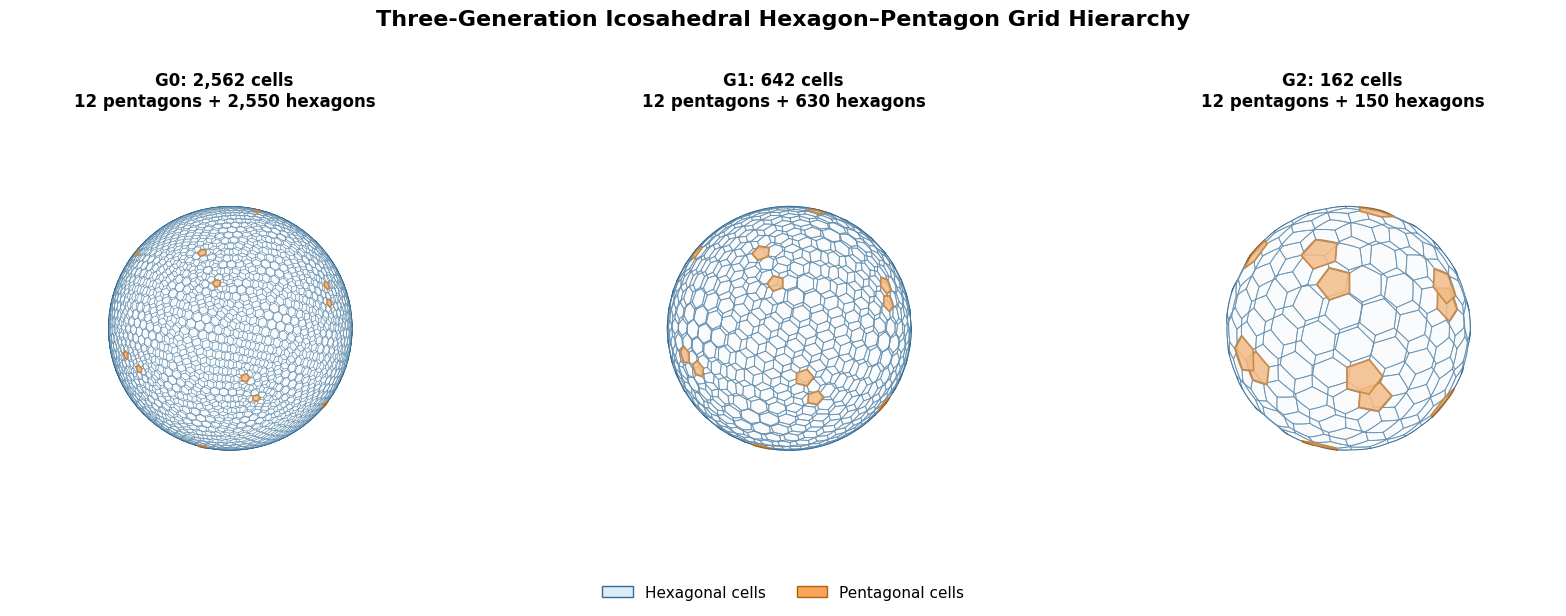

Figure generation time: 9.411 seconds
Cell 2C completed successfully.


In [ ]:
# =============================================================================
# CELL 2C — VISUALIZATION OF THE THREE-GENERATION ICOSAHEDRAL GRID HIERARCHY
# =============================================================================
#
# PURPOSE
# -------
# Display the three spherical hexagon-pentagon grids used by MGGF:
#
#     G0 : 2562 cells (fine resolution)
#     G1 :  642 cells (intermediate resolution)
#     G2 :  162 cells (coarse resolution)
#
# Each cell is a spherical Voronoi polygon surrounding one vertex of the
# underlying triangular icosahedral mesh.
#
# The figure distinguishes:
#
#     Hexagonal cells  : blue boundaries, light-blue faces
#     Pentagonal cells : orange boundaries, orange faces
#
# The twelve pentagonal cells are topologically important because their
# connectivity differs from that of the hexagonal cells.
#
# The figure is generated entirely from the geometry constructed in
# Cells 2A and 2B. No external files or Google Drive access are needed.
#
# =============================================================================

from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Patch


# -------------------------------------------------------------------------
# 1. Define a consistent viewing orientation
# -------------------------------------------------------------------------
#
# Using the same orientation for all generations makes differences in
# resolution easier to interpret.
#
# The view can be changed later without affecting the numerical model.

VIEW_ELEVATION = 23.0
VIEW_AZIMUTH = -65.0

HEX_FACE_COLOR = "#DCECF7"
HEX_EDGE_COLOR = "#326A94"

PENT_FACE_COLOR = "#F5A65B"
PENT_EDGE_COLOR = "#B45F06"


# -------------------------------------------------------------------------
# 2. Construct spherical polygon boundary curves
# -------------------------------------------------------------------------
#
# A spherical Voronoi polygon is bounded by great-circle arcs.
#
# Directly joining polygon vertices with straight lines would create
# chords inside the sphere rather than arcs on its surface.
#
# Spherical linear interpolation (SLERP) is used to draw each boundary
# along the unit sphere.
#
# This affects visualization only, not the grid geometry or cell areas.

def spherical_arc(a, b, npoints=8):
    """
    Return points along the shortest great-circle arc from a to b.

    Both input vectors are assumed to lie on the unit sphere.
    """

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    dot = np.clip(np.dot(a, b), -1.0, 1.0)
    angle = np.arccos(dot)

    t = np.linspace(0.0, 1.0, npoints)

    if angle < 1.0e-12:
        return np.repeat(a[None, :], npoints, axis=0)

    points = (
        np.sin((1.0 - t) * angle)[:, None] * a[None, :]
        + np.sin(t * angle)[:, None] * b[None, :]
    ) / np.sin(angle)

    return points


def spherical_polygon_boundary(polygon_vertices, npoints_per_edge=6):
    """
    Construct a closed boundary following great-circle arcs.
    """

    segments = []

    n = len(polygon_vertices)

    for j in range(n):
        a = polygon_vertices[j]
        b = polygon_vertices[(j + 1) % n]

        arc = spherical_arc(a, b, npoints=npoints_per_edge)

        segments.append(arc[:-1])

    return np.vstack(segments + [segments[0][0:1]])


# -------------------------------------------------------------------------
# 3. Plot one generation
# -------------------------------------------------------------------------

def plot_icosahedral_generation(ax, grid, name):
    """
    Draw the spherical Voronoi cells of one icosahedral generation.

    The number of polygon sides determines whether a cell is a
    pentagon or hexagon.

    To improve the three-dimensional appearance, the cells are
    displayed as translucent polygons and their spherical boundaries
    are drawn separately.
    """

    vertices = grid["vertices"]
    vor = grid["voronoi"]
    degrees = grid["degrees"]

    # Draw a lightly shaded spherical surface.
    longitude = np.linspace(0.0, 2.0 * np.pi, 45)
    latitude = np.linspace(-np.pi / 2, np.pi / 2, 25)

    lon, lat = np.meshgrid(longitude, latitude)

    xs = np.cos(lat) * np.cos(lon)
    ys = np.cos(lat) * np.sin(lon)
    zs = np.sin(lat)

    ax.plot_surface(
        xs, ys, zs,
        color="#F0F5F8",
        alpha=0.16,
        linewidth=0,
        shade=False
    )

    pentagon_polygons = []

    # Draw each spherical Voronoi cell.
    for i, region in enumerate(vor.regions):

        polygon = vor.vertices[np.asarray(region)]

        # Polygon boundaries are curved on the sphere.
        boundary = spherical_polygon_boundary(
            polygon,
            npoints_per_edge=5
        )

        if degrees[i] == 5:
            pentagon_polygons.append(polygon)

            edge_color = PENT_EDGE_COLOR
            edge_width = 1.35
        else:
            edge_color = HEX_EDGE_COLOR
            edge_width = 0.35 if len(vertices) > 1000 else 0.65

        ax.plot(
            boundary[:, 0] * 1.003,
            boundary[:, 1] * 1.003,
            boundary[:, 2] * 1.003,
            color=edge_color,
            linewidth=edge_width,
            alpha=0.85
        )

    # Highlight the pentagonal cells with orange shading.
    #
    # The polygon vertices form a planar approximation for display.
    # Their spherical boundaries were already drawn above.
    pentagon_collection = Poly3DCollection(
        pentagon_polygons,
        facecolors=PENT_FACE_COLOR,
        edgecolors=PENT_EDGE_COLOR,
        linewidths=1.1,
        alpha=0.85
    )

    ax.add_collection3d(pentagon_collection)

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_zlim(-1.05, 1.05)

    ax.set_box_aspect([1, 1, 1])

    ax.view_init(
        elev=VIEW_ELEVATION,
        azim=VIEW_AZIMUTH
    )

    ax.set_axis_off()

    ax.set_title(
        f"{name}: {len(vertices):,} cells\n"
        f"12 pentagons + {len(vertices)-12:,} hexagons",
        fontsize=12,
        fontweight="bold",
        pad=10
    )


# -------------------------------------------------------------------------
# 4. Create the three-panel figure
# -------------------------------------------------------------------------

print("=" * 78)
print("GENERATING THREE-GENERATION ICOSAHEDRAL GRID FIGURE")
print("=" * 78)

t0 = time.perf_counter()

fig = plt.figure(figsize=(17, 6.5))

for panel, name in enumerate(["G0", "G1", "G2"], start=1):

    ax = fig.add_subplot(
        1, 3, panel,
        projection="3d"
    )

    plot_icosahedral_generation(
        ax,
        grids[name],
        name
    )

fig.suptitle(
    "Three-Generation Icosahedral Hexagon–Pentagon Grid Hierarchy",
    fontsize=16,
    fontweight="bold",
    y=0.97
)

legend_elements = [
    Patch(
        facecolor=HEX_FACE_COLOR,
        edgecolor=HEX_EDGE_COLOR,
        label="Hexagonal cells"
    ),
    Patch(
        facecolor=PENT_FACE_COLOR,
        edgecolor=PENT_EDGE_COLOR,
        label="Pentagonal cells"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.04)
)

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.80,
    bottom=0.14,
    wspace=0.02
)

plt.show()

elapsed = time.perf_counter() - t0

print(f"Figure generation time: {elapsed:.3f} seconds")
print("Cell 2C completed successfully.")
print("=" * 78)

# Cell 3A - Construction of the graph Laplacian

In [ ]:
# =============================================================================
# CELL 3A — CONSTRUCTION OF AREA-COMPATIBLE GRAPH LAPLACIANS
# =============================================================================
#
# PURPOSE
# -------
# Construct a graph Laplacian L for each icosahedral generation.
#
# We follow the balanced formulation used in the reference MGGF TEST 9:
#
#   W = adjacency + I
#   S = D W D
#   L = I - A^{-1} S
#
# where:
#   A = diagonal matrix of spherical dual-cell areas
#   D = diagonal scaling determined iteratively
#   S = symmetric nonnegative matrix with row sums equal to cell areas
#
# The balancing condition S 1 = A 1 guarantees L 1 = 0.
#
# Since A L = A - S is symmetric, L is self-adjoint under the
# area-weighted inner product.
#
# The diagonal of W includes self-connections, following TEST 9.
# =============================================================================

def construct_graph_adjacency(edges, n):
    """
    Construct a symmetric sparse adjacency matrix from undirected edges.

    Every edge (i,j) contributes entries (i,j) and (j,i).
    The diagonal remains zero at this stage.
    """
    i, j = edges[:, 0], edges[:, 1]

    rows = np.concatenate([i, j])
    cols = np.concatenate([j, i])
    data = np.ones(len(rows), dtype=np.float64)

    Adj = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(n, n)
    ).tocsr()

    return Adj


def build_area_laplacian(Adj, area, label,
                         tolerance=1.0e-14,
                         max_iterations=20000):
    """
    Construct the area-compatible graph Laplacian.

    The symmetric matrix W contains nearest-neighbor connections
    and self-connections.

    A diagonal scaling D is computed so that S = D W D has
    approximately the prescribed row sums:

        S 1 = area.

    The resulting operator is:

        L = I - A^{-1} S.

    Its desired properties are:
        L 1 = 0
        A L = (A L)^T
        <u, L u>_A >= 0

    The first two properties are tested below. Positive
    semidefiniteness will also be tested independently in Cell 3B.
    """

    n = len(area)

    # Include self-connections, as in the reference implementation.
    W = (Adj + sp.eye(n, format="csr")).tocsr()

    # Initial scaling estimate.
    d = np.sqrt(
        area / np.maximum(W @ np.ones(n), 1.0e-300)
    )

    # Symmetric diagonal balancing.
    for iteration in range(max_iterations):

        Wd = W @ d

        d_target = area / np.maximum(Wd, 1.0e-300)

        d_new = np.sqrt(d * d_target)

        relative_change = np.max(
            np.abs(d_new - d) /
            np.maximum(np.abs(d), 1.0e-300)
        )

        d = d_new

        if relative_change < tolerance:
            break
    else:
        raise RuntimeError(f"{label}: balancing did not converge.")

    S = (sp.diags(d) @ W @ sp.diags(d)).tocsr()

    row_sum = np.asarray(S.sum(axis=1)).ravel()

    balance_error = np.max(
        np.abs(row_sum - area) / area
    )

    L = (
        sp.eye(n, format="csr")
        - sp.diags(1.0 / area) @ S
    ).tocsr()

    AL = (sp.diags(area) @ L).tocsr()
    asymmetry = (AL - AL.T).tocsr()

    adjoint_error = (
        np.max(np.abs(asymmetry.data)) /
        max(np.max(np.abs(AL.data)), 1.0e-300)
        if asymmetry.nnz else 0.0
    )

    constant_error = np.max(np.abs(L @ np.ones(n)))

    print(f"\n{label}")
    print(f"  Cells                  : {n}")
    print(f"  Balancing iterations   : {iteration + 1}")
    print(f"  Relative balance error : {balance_error:.6e}")
    print(f"  Constant-field error   : {constant_error:.6e}")
    print(f"  Weighted-adjoint error : {adjoint_error:.6e}")

    verify(
        f"{label}: constant preservation",
        constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{label}: weighted self-adjointness",
        adjoint_error,
        TOL_ADJOINT
    )

    verify(
        f"{label}: area balancing",
        balance_error,
        1.0e-10
    )

    return L


# -------------------------------------------------------------------------
# Construct Laplacians for all three generations.
# -------------------------------------------------------------------------

print("=" * 78)
print("CONSTRUCTION OF AREA-COMPATIBLE GRAPH LAPLACIANS")
print("=" * 78)

for name in ["G0", "G1", "G2"]:

    grid = grids[name]

    Adj = construct_graph_adjacency(
        grid["edges"],
        len(grid["vertices"])
    )

    grid["adjacency"] = Adj

    grid["L"] = build_area_laplacian(
        Adj,
        grid["area"],
        name
    )

print()
print("Cell 3A completed successfully.")
print("=" * 78)

CONSTRUCTION OF AREA-COMPATIBLE GRAPH LAPLACIANS

G0
  Cells                  : 2562
  Balancing iterations   : 58
  Relative balance error : 9.652864e-15
  Constant-field error   : 9.769963e-15
  Weighted-adjoint error : 5.603290e-17
G0: constant preservation                     error = 9.769963e-15   tolerance = 1.0e-10   [PASS]
G0: weighted self-adjointness                 error = 5.603290e-17   tolerance = 1.0e-10   [PASS]
G0: area balancing                            error = 9.652864e-15   tolerance = 1.0e-10   [PASS]

G1
  Cells                  : 642
  Balancing iterations   : 58
  Relative balance error : 9.161628e-15
  Constant-field error   : 9.103829e-15
  Weighted-adjoint error : 5.752616e-17
G1: constant preservation                     error = 9.103829e-15   tolerance = 1.0e-10   [PASS]
G1: weighted self-adjointness                 error = 5.752616e-17   tolerance = 1.0e-10   [PASS]
G1: area balancing                            error = 9.161628e-15   tolerance = 1.0e-10  

# Cell 3B - Verification of the gaph Laplacian

In [ ]:
# =============================================================================
# CELL 3B — MATHEMATICAL VERIFICATION OF GRAPH LAPLACIANS
# =============================================================================
#
# PURPOSE
# -------
# Verify the mathematical properties of the graph Laplacian L on each
# generation of the spherical icosahedral grid.
#
# The required properties are:
#
#   1. Constant-field preservation:
#          L 1 = 0
#
#   2. Area-weighted self-adjointness:
#          <u, Lv>_A = <Lu, v>_A
#
#   3. Positive semidefiniteness:
#          <u, Lu>_A >= 0
#
#   4. Conservation identity:
#          1^T A L u = 0
#
# These properties provide the mathematical foundation for constructing
# conservative and self-adjoint Graph Filters.
#
# =============================================================================

def weighted_inner_product(u, v, area):
    """
    Compute the area-weighted inner product:

        <u,v>_A = sum_i A_i u_i v_i
    """
    return np.dot(area * u, v)


print("=" * 78)
print("GRAPH LAPLACIAN MATHEMATICAL VERIFICATION")
print("=" * 78)

N_RANDOM_TESTS = 10

for name in ["G0", "G1", "G2"]:

    grid = grids[name]

    L = grid["L"]
    area = grid["area"]
    n = len(area)

    # ---------------------------------------------------------------
    # Test 1: Constant preservation
    # ---------------------------------------------------------------

    constant_error = np.max(
        np.abs(L @ np.ones(n))
    )

    # ---------------------------------------------------------------
    # Test 2: Area-weighted self-adjointness
    # ---------------------------------------------------------------
    #
    # We test the identity:
    #
    #     <u, Lv>_A = <Lu, v>_A
    #
    # using several independent random vector pairs.
    #
    # The error is normalized by the magnitudes of the two
    # inner products to make it dimensionless.

    max_adjoint_error = 0.0

    for _ in range(N_RANDOM_TESTS):

        u = rng.standard_normal(n)
        v = rng.standard_normal(n)

        lhs = weighted_inner_product(u, L @ v, area)
        rhs = weighted_inner_product(L @ u, v, area)

        error = abs(lhs - rhs) / max(
            abs(lhs),
            abs(rhs),
            1.0e-30
        )

        max_adjoint_error = max(
            max_adjoint_error,
            error
        )

    # ---------------------------------------------------------------
    # Test 3: Positive semidefiniteness
    # ---------------------------------------------------------------
    #
    # For a positive-semidefinite operator:
    #
    #     <u, Lu>_A >= 0
    #
    # We test this with random vectors.
    #
    # Small negative values near machine precision may occur due to
    # floating-point rounding.

    minimum_quadratic_form = np.inf

    for _ in range(N_RANDOM_TESTS):

        u = rng.standard_normal(n)

        quadratic_form = weighted_inner_product(
            u, L @ u, area
        )

        normalized_quadratic_form = (
            quadratic_form /
            weighted_inner_product(u, u, area)
        )

        minimum_quadratic_form = min(
            minimum_quadratic_form,
            normalized_quadratic_form
        )

    # ---------------------------------------------------------------
    # Test 4: Conservation identity
    # ---------------------------------------------------------------
    #
    # Since L is area-weighted self-adjoint and L 1 = 0:
    #
    #     1^T A L u = 0.
    #
    # This means that the Laplacian has zero area-weighted integral.

    max_conservation_error = 0.0

    for _ in range(N_RANDOM_TESTS):

        u = rng.standard_normal(n)

        Lu = L @ u

        integral = np.dot(area, Lu)

        normalization = np.sum(
            area * np.abs(Lu)
        )

        error = abs(integral) / max(
            normalization,
            1.0e-30
        )

        max_conservation_error = max(
            max_conservation_error,
            error
        )

    print()
    print(name)
    print("-" * 78)

    print(
        f"Constant-field error       : "
        f"{constant_error:.6e}"
    )

    print(
        f"Weighted-adjoint error     : "
        f"{max_adjoint_error:.6e}"
    )

    print(
        f"Minimum normalized <u,Lu>  : "
        f"{minimum_quadratic_form:.6e}"
    )

    print(
        f"Conservation error         : "
        f"{max_conservation_error:.6e}"
    )

    verify(
        f"{name}: constant preservation",
        constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{name}: weighted self-adjointness",
        max_adjoint_error,
        TOL_ADJOINT
    )

    verify(
        f"{name}: positive semidefiniteness",
        max(0.0, -minimum_quadratic_form),
        1.0e-12
    )

    verify(
        f"{name}: conservation identity",
        max_conservation_error,
        TOL_CONSERVATION
    )

print()
print("=" * 78)
print("CELL 3B COMPLETED SUCCESSFULLY")
print("All graph Laplacian verification tests passed.")
print("=" * 78)

GRAPH LAPLACIAN MATHEMATICAL VERIFICATION

G0
------------------------------------------------------------------------------
Constant-field error       : 9.769963e-15
Weighted-adjoint error     : 1.514850e-15
Minimum normalized <u,Lu>  : 8.328143e-01
Conservation error         : 1.027857e-16
G0: constant preservation                     error = 9.769963e-15   tolerance = 1.0e-10   [PASS]
G0: weighted self-adjointness                 error = 1.514850e-15   tolerance = 1.0e-10   [PASS]
G0: positive semidefiniteness                 error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
G0: conservation identity                     error = 1.027857e-16   tolerance = 1.0e-10   [PASS]

G1
------------------------------------------------------------------------------
Constant-field error       : 9.103829e-15
Weighted-adjoint error     : 1.324311e-14
Minimum normalized <u,Lu>  : 8.327762e-01
Conservation error         : 2.694930e-16
G1: constant preservation                     error = 9.103829e-

## Cell 4A — Construction of the single-generation Graph Filter (GGF)

In [ ]:
# =============================================================================
# CELL 4A — SINGLE-GENERATION GRAPH FILTER (GGF)
# =============================================================================
#
# PURPOSE
# -------
# Implement the single-generation Graph Filter:
#
#       B = [I + (Gamma/p) L]^(-p)
#
# where L is the area-compatible graph Laplacian constructed in Cell 3A.
#
# The filter is applied through p successive sparse linear solves.
#
# We do NOT explicitly form B or calculate a dense matrix inverse.
# Instead, we factorize:
#
#       M = I + (Gamma/p) L
#
# and repeatedly solve:
#
#       M u_next = u_current.
#
# This approach:
#
#   1. Preserves the sparse structure of the graph operator.
#   2. Avoids explicitly forming a potentially dense filter matrix.
#   3. Allows the same factorization to be reused.
#   4. Supports repeated filtering of different input fields.
#
# The parameters Gamma and p are inherited from Cell 1.
#
# =============================================================================


class GraphFilter:
    """
    Repeated-resolvent Graph Filter on a single graph generation.

    Parameters
    ----------
    L : scipy sparse matrix
        Area-compatible graph Laplacian.

    gamma : float
        Filter-strength parameter.

    p : int
        Number of repeated resolvent applications.

    Notes
    -----
    The filter is defined by:

        B = [I + (gamma/p) L]^(-p)

    A sparse LU factorization is constructed once during initialization.

    Each call to apply() then performs p triangular-solve operations
    using the stored factorization.

    The operator B is not explicitly assembled.
    """

    def __init__(self, L, gamma, p):

        if gamma < 0:
            raise ValueError("Gamma must be nonnegative.")

        if not isinstance(p, (int, np.integer)) or p < 1:
            raise ValueError("Filter order p must be a positive integer.")

        self.gamma = float(gamma)
        self.p = int(p)

        self.n = L.shape[0]

        # Construct the sparse resolvent matrix.
        #
        # The graph Laplacian has nonnegative eigenvalues.
        # Therefore, I + (gamma/p)L is nonsingular for gamma >= 0.

        self.M = (
            sp.eye(self.n, format="csc")
            + (self.gamma / self.p) * L.tocsc()
        ).tocsc()

        # Factorize once and reuse for all filtering operations.
        self.factorization = spla.splu(self.M)

    def apply(self, field):
        """
        Apply the Graph Filter to a scalar field.

        Parameters
        ----------
        field : ndarray, shape (n,)
            Input values defined at graph vertices.

        Returns
        -------
        filtered : ndarray, shape (n,)
            Field after p repeated-resolvent applications.
        """

        filtered = np.asarray(field, dtype=np.float64).copy()

        if filtered.shape != (self.n,):
            raise ValueError(
                f"Expected field shape ({self.n},), "
                f"received {filtered.shape}."
            )

        for _ in range(self.p):

            filtered = self.factorization.solve(filtered)

        return filtered


# -------------------------------------------------------------------------
# 1. Construct a Graph Filter for each generation.
# -------------------------------------------------------------------------

print("=" * 78)
print("CONSTRUCTION OF SINGLE-GENERATION GRAPH FILTERS")
print("=" * 78)

for name in ["G0", "G1", "G2"]:

    grid = grids[name]

    t0 = time.perf_counter()

    graph_filter = GraphFilter(
        L=grid["L"],
        gamma=GAMMA,
        p=FILTER_ORDER
    )

    construction_time = time.perf_counter() - t0

    grid["GGF"] = graph_filter
    grid["GGF_construction_time"] = construction_time

    # -------------------------------------------------------------
    # 2. Test the filtering operation with a random scalar field.
    # -------------------------------------------------------------
    #
    # We measure only the filtering time here.
    # Matrix factorization time is reported separately above.
    #
    # The random input is used only as a computational smoke test.
    # Mathematical verification follows in Cell 4B.

    field = rng.standard_normal(len(grid["vertices"]))

    t1 = time.perf_counter()

    filtered = graph_filter.apply(field)

    application_time = time.perf_counter() - t1

    grid["GGF_application_time"] = application_time

    print()
    print(f"{name}")
    print("-" * 78)

    print(f"Cells                  : {len(field)}")
    print(f"Gamma                  : {GAMMA}")
    print(f"Filter order p         : {FILTER_ORDER}")
    print(f"Factorization time     : {construction_time:.6f} s")
    print(f"Filtering time         : {application_time:.6f} s")
    print(f"Input RMS              : {np.sqrt(np.mean(field**2)):.6e}")
    print(f"Filtered RMS           : {np.sqrt(np.mean(filtered**2)):.6e}")

    if not np.all(np.isfinite(filtered)):
        raise AssertionError(
            f"{name}: nonfinite values encountered during filtering."
        )

print()
print("=" * 78)
print("CELL 4A COMPLETED SUCCESSFULLY")
print("All three single-generation Graph Filters constructed and applied.")
print("=" * 78)

CONSTRUCTION OF SINGLE-GENERATION GRAPH FILTERS

G0
------------------------------------------------------------------------------
Cells                  : 2562
Gamma                  : 14.0
Filter order p         : 5
Factorization time     : 0.031072 s
Filtering time         : 0.009266 s
Input RMS              : 1.013562e+00
Filtered RMS           : 1.129688e-01

G1
------------------------------------------------------------------------------
Cells                  : 642
Gamma                  : 14.0
Filter order p         : 5
Factorization time     : 0.005362 s
Filtering time         : 0.002511 s
Input RMS              : 1.012428e+00
Filtered RMS           : 1.002566e-01

G2
------------------------------------------------------------------------------
Cells                  : 162
Gamma                  : 14.0
Filter order p         : 5
Factorization time     : 0.001565 s
Filtering time         : 0.000264 s
Input RMS              : 9.550825e-01
Filtered RMS           : 6.379947e-02


# Cell 4B — Mathematical verification of GGF

In [ ]:
# =============================================================================
# CELL 4B — MATHEMATICAL VERIFICATION OF SINGLE-GENERATION GRAPH FILTERS
# =============================================================================
#
# PURPOSE
# -------
# Verify the fundamental mathematical properties of the Graph Filter:
#
#                  B = [I + (Gamma/p)L]^(-p)
#
# For each generation, we test:
#
#   1. Constant preservation:       B 1 = 1
#   2. Area-integral conservation:  sum(A * B u) = sum(A * u)
#   3. Weighted self-adjointness:   <u,Bv>_A = <Bu,v>_A
#   4. Positive semidefiniteness:   <u,Bu>_A >= 0
#   5. Impulse-mass conservation:   a unit-mass impulse retains mass 1
#
# The tests use random vectors and a localized impulse.
#
# IMPORTANT
# ---------
# No normalization or mass correction is applied after filtering.
# Conservation must follow from the filter construction itself.
#
# =============================================================================

N_GGF_TESTS = 10

print("=" * 78)
print("SINGLE-GENERATION GRAPH FILTER VERIFICATION")
print("=" * 78)

for name in ["G0", "G1", "G2"]:

    grid = grids[name]
    B = grid["GGF"]
    area = grid["area"]
    n = len(area)

    # ---------------------------------------------------------------
    # TEST 1 — Constant preservation
    # ---------------------------------------------------------------
    #
    # A constant field must remain unchanged by the Graph Filter.
    #
    # This property follows from L 1 = 0.

    ones = np.ones(n)
    filtered_ones = B.apply(ones)

    constant_error = np.max(np.abs(filtered_ones - ones))

    # ---------------------------------------------------------------
    # TEST 2 — Area-integral conservation
    # ---------------------------------------------------------------
    #
    # For every field u:
    #
    #     sum_i A_i (Bu)_i = sum_i A_i u_i
    #
    # We use random vectors and normalize the residual by the
    # area-weighted L1 norm of the input to avoid cancellation.

    max_mass_error = 0.0

    for _ in range(N_GGF_TESTS):

        u = rng.standard_normal(n)
        Bu = B.apply(u)

        mass_before = np.dot(area, u)
        mass_after = np.dot(area, Bu)

        scale = np.dot(area, np.abs(u))

        error = abs(mass_after - mass_before) / max(
            scale, 1.0e-300
        )

        max_mass_error = max(max_mass_error, error)

    # ---------------------------------------------------------------
    # TEST 3 — Area-weighted self-adjointness
    # ---------------------------------------------------------------
    #
    # The filtering operator must satisfy:
    #
    #     <u,Bv>_A = <Bu,v>_A
    #
    # Normalize by the product of the weighted vector norms.
    # This avoids artificially large relative errors when the
    # inner products happen to be close to zero.

    max_adjoint_error = 0.0

    for _ in range(N_GGF_TESTS):

        u = rng.standard_normal(n)
        v = rng.standard_normal(n)

        Bu = B.apply(u)
        Bv = B.apply(v)

        lhs = weighted_inner_product(u, Bv, area)
        rhs = weighted_inner_product(Bu, v, area)

        norm_u = np.sqrt(weighted_inner_product(u, u, area))
        norm_v = np.sqrt(weighted_inner_product(v, v, area))

        error = abs(lhs - rhs) / max(
            norm_u * norm_v, 1.0e-300
        )

        max_adjoint_error = max(max_adjoint_error, error)

    # ---------------------------------------------------------------
    # TEST 4 — Positive semidefiniteness
    # ---------------------------------------------------------------
    #
    # The filter B is a positive-definite function of the
    # nonnegative Laplacian L.
    #
    # Therefore:
    #
    #     <u,Bu>_A >= 0
    #
    # We verify this property using random vectors.
    #
    # These numerical samples supplement the mathematical
    # argument; they do not constitute a complete spectral proof.

    minimum_quadratic_form = np.inf

    for _ in range(N_GGF_TESTS):

        u = rng.standard_normal(n)
        Bu = B.apply(u)

        q = (
            weighted_inner_product(u, Bu, area)
            / weighted_inner_product(u, u, area)
        )

        minimum_quadratic_form = min(
            minimum_quadratic_form, q
        )

    # ---------------------------------------------------------------
    # TEST 5 — Localized impulse conservation
    # ---------------------------------------------------------------
    #
    # Choose one cell near the positive x-axis.
    #
    # Define a discrete impulse whose area-weighted integral
    # is exactly one:
    #
    #     impulse[j] = 1 / A[j]
    #
    # Filtering should spread the impulse without changing
    # its total area-weighted mass.
    #
    # This normalization is applied to the INPUT impulse only.
    # No correction is applied to the filtered result.

    source = int(np.argmax(grid["vertices"][:, 0]))

    impulse = np.zeros(n)
    impulse[source] = 1.0 / area[source]

    filtered_impulse = B.apply(impulse)

    impulse_mass_before = np.dot(area, impulse)
    impulse_mass_after = np.dot(area, filtered_impulse)

    impulse_mass_error = abs(
        impulse_mass_after - impulse_mass_before
    )

    # A positive resolvent filter should preserve nonnegativity
    # for a nonnegative impulse, up to numerical roundoff.
    minimum_impulse_value = np.min(filtered_impulse)

    # ---------------------------------------------------------------
    # REPORT RESULTS
    # ---------------------------------------------------------------

    print()
    print(name)
    print("-" * 78)

    print(f"Constant-field error        : {constant_error:.6e}")
    print(f"Area-integral error         : {max_mass_error:.6e}")
    print(f"Weighted-adjoint error      : {max_adjoint_error:.6e}")
    print(f"Minimum normalized <u,Bu>   : {minimum_quadratic_form:.6e}")
    print(f"Impulse mass before         : {impulse_mass_before:.12f}")
    print(f"Impulse mass after          : {impulse_mass_after:.12f}")
    print(f"Impulse mass error          : {impulse_mass_error:.6e}")
    print(f"Minimum filtered impulse    : {minimum_impulse_value:.6e}")

    verify(
        f"{name}: constant preservation",
        constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{name}: area-integral conservation",
        max_mass_error,
        TOL_CONSERVATION
    )

    verify(
        f"{name}: weighted self-adjointness",
        max_adjoint_error,
        TOL_ADJOINT
    )

    verify(
        f"{name}: positive semidefiniteness",
        max(0.0, -minimum_quadratic_form),
        1.0e-12
    )

    verify(
        f"{name}: impulse mass conservation",
        impulse_mass_error,
        TOL_CONSERVATION
    )

    verify(
        f"{name}: impulse nonnegativity",
        max(0.0, -minimum_impulse_value),
        1.0e-12
    )

    # Save the impulse response for later visualization.
    grid["GGF_impulse_source"] = source
    grid["GGF_impulse_response"] = filtered_impulse

print()
print("=" * 78)
print("CELL 4B COMPLETED SUCCESSFULLY")
print("All single-generation GGF verification tests passed.")
print("=" * 78)

SINGLE-GENERATION GRAPH FILTER VERIFICATION

G0
------------------------------------------------------------------------------
Constant-field error        : 8.992806e-15
Area-integral error         : 1.332232e-16
Weighted-adjoint error      : 3.301781e-18
Minimum normalized <u,Bu>   : 2.622940e-02
Impulse mass before         : 1.000000000000
Impulse mass after          : 1.000000000000
Impulse mass error          : 4.440892e-16
Minimum filtered impulse    : 4.692503e-30
G0: constant preservation                     error = 8.992806e-15   tolerance = 1.0e-10   [PASS]
G0: area-integral conservation                error = 1.332232e-16   tolerance = 1.0e-10   [PASS]
G0: weighted self-adjointness                 error = 3.301781e-18   tolerance = 1.0e-10   [PASS]
G0: positive semidefiniteness                 error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
G0: impulse mass conservation                 error = 4.440892e-16   tolerance = 1.0e-10   [PASS]
G0: impulse nonnegativity          

# Cell 4C — Visualizing the single-generation impulse response

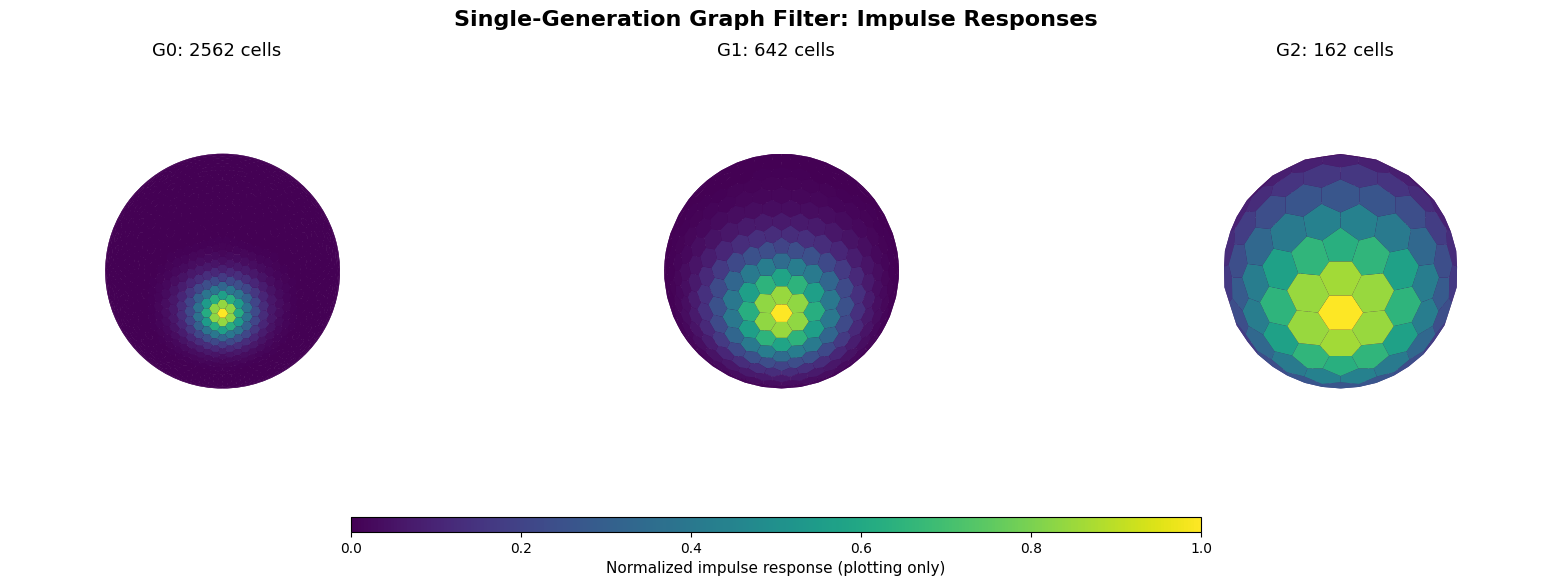

In [ ]:
# =============================================================================
# CELL 4C — SINGLE-GENERATION GRAPH FILTER IMPULSE RESPONSES
# =============================================================================
#
# PURPOSE
# -------
# Visualize the response of the single-generation Graph Filter to
# a localized, unit-area-integral impulse.
#
# The impulse responses were computed and stored in Cell 4B.
#
# For visualization only, each response is divided by its maximum.
# This allows us to compare spatial spreading across generations.
#
# The original numerical fields are NOT modified.
#
# =============================================================================

from matplotlib import cm, colors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection


def plot_ggf_impulse(ax, grid, label):
    """
    Plot the spherical Voronoi dual cells colored by the
    normalized single-generation GGF impulse response.
    """

    vertices = grid["vertices"]
    vor = grid["voronoi"]

    response = grid["GGF_impulse_response"]
    source = grid["GGF_impulse_source"]

    # Normalize only for plotting.
    normalized_response = response / np.max(response)

    cmap = plt.get_cmap("viridis")
    norm = colors.Normalize(vmin=0.0, vmax=1.0)

    # Draw spherical Voronoi cells as filled polygons.
    # The Voronoi vertices lie on the unit sphere.
    #
    # For this overview figure, each curved cell is represented
    # by a planar polygon connecting its spherical vertices.

    polygons = []
    facecolors = []

    for i, region in enumerate(vor.regions):

        polygon = vor.vertices[region]

        polygons.append(polygon)

        facecolors.append(
            cmap(norm(normalized_response[i]))
        )

    collection = Poly3DCollection(
        polygons,
        facecolors=facecolors,
        edgecolors="none",
        linewidths=0.0
    )

    ax.add_collection3d(collection)

    # Mark the impulse source.
    source_xyz = vertices[source]

    ax.scatter(
        [1.025 * source_xyz[0]],
        [1.025 * source_xyz[1]],
        [1.025 * source_xyz[2]],
        color="red",
        s=70,
        edgecolors="white",
        linewidths=1.0,
        depthshade=False
    )

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_zlim(-1.05, 1.05)

    ax.set_box_aspect((1, 1, 1))

    # View from the positive x-axis, close to the impulse source.
    ax.view_init(elev=20, azim=0)

    ax.set_axis_off()

    ax.set_title(
        f"{label}: {len(vertices)} cells",
        fontsize=13,
        pad=10
    )


# -------------------------------------------------------------------------
# Create the three-generation comparison figure.
# -------------------------------------------------------------------------

fig = plt.figure(figsize=(17, 6))

for panel, name in enumerate(["G0", "G1", "G2"], start=1):

    ax = fig.add_subplot(
        1, 3, panel,
        projection="3d"
    )

    plot_ggf_impulse(
        ax,
        grids[name],
        name
    )

fig.suptitle(
    "Single-Generation Graph Filter: Impulse Responses",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

# Shared colorbar.
sm = cm.ScalarMappable(
    norm=colors.Normalize(vmin=0.0, vmax=1.0),
    cmap="viridis"
)
sm.set_array([])

cax = fig.add_axes([0.25, 0.09, 0.50, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(
    "Normalized impulse response (plotting only)",
    fontsize=11
)

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.86,
    bottom=0.17,
    wspace=0.02
)

plt.show()

# Cell 5A: Geometric preparation for second-order inter-generation interpolation

In [ ]:
# =============================================================================
# CELL 5A — GEOMETRY FOR SECOND-ORDER INTER-GENERATION INTERPOLATION
# =============================================================================
#
# PURPOSE
# -------
# Prepare geometric information needed to interpolate from a coarse
# icosahedral generation to the next finer generation.
#
# For each fine-grid vertex:
#
#   1. Identify the nearest coarse-grid vertex.
#   2. Construct a local orthonormal tangent-plane basis.
#   3. Identify a coarse-grid stencil around that vertex.
#   4. Express stencil vertices and the fine-grid target in
#      local tangent-plane coordinates.
#
# No interpolation coefficients are calculated in this cell.
#
# The geometric data will be used in Cell 5B to construct the
# second-order prolongation operator.
#
# =============================================================================

def tangent_basis(center):
    """
    Construct an orthonormal tangent-plane basis at a point
    on the unit sphere.

    Returns
    -------
    east, north : ndarray, shape (3,)
        Two orthonormal vectors tangent to the sphere.
    """

    center = np.asarray(center, dtype=np.float64)
    center = center / np.linalg.norm(center)

    reference = np.array([0.0, 0.0, 1.0])

    # Avoid near-parallel reference vectors.
    if abs(np.dot(center, reference)) > 0.9:
        reference = np.array([0.0, 1.0, 0.0])

    east = np.cross(reference, center)
    east /= np.linalg.norm(east)

    north = np.cross(center, east)
    north /= np.linalg.norm(north)

    return east, north


def tangent_coordinates(points, center, east, north):
    """
    Project spherical points onto a tangent plane centered at 'center'.

    Coordinates are dimensionless because the sphere has unit radius.

    The orthogonal tangent-plane projection is:

        x = (point - center) dot east
        y = (point - center) dot north

    These coordinates are used locally, not as a global map projection.
    """

    displacement = np.asarray(points) - center

    x = displacement @ east
    y = displacement @ north

    return np.column_stack([x, y])


def build_coarse_neighbor_lists(edges, n):
    """
    Construct adjacency lists from undirected coarse-grid edges.
    """

    neighbors = [[] for _ in range(n)]

    for i, j in edges:
        neighbors[i].append(j)
        neighbors[j].append(i)

    return [
        np.asarray(sorted(set(row)), dtype=np.int64)
        for row in neighbors
    ]


def prepare_interpolation_geometry(coarse, fine):
    """
    Prepare local geometry for interpolation from coarse to fine.

    Each fine vertex is assigned its nearest coarse vertex as
    the center of a local stencil.

    The stencil initially consists of the center and its immediate
    coarse-grid neighbors (six or seven points total).

    The returned coordinates are expressed in a tangent plane
    centered at the selected coarse vertex.
    """

    coarse_vertices = coarse["vertices"]
    fine_vertices = fine["vertices"]

    nc = len(coarse_vertices)
    nf = len(fine_vertices)

    tree = cKDTree(coarse_vertices)

    distances, nearest_coarse = tree.query(
        fine_vertices, k=1
    )

    coarse_neighbors = build_coarse_neighbor_lists(
        coarse["edges"], nc
    )

    stencils = []
    stencil_coordinates = []
    target_coordinates = []

    for i in range(nf):

        parent = int(nearest_coarse[i])
        center = coarse_vertices[parent]

        # Center plus all immediate coarse neighbors.
        stencil = np.concatenate([
            np.array([parent], dtype=np.int64),
            coarse_neighbors[parent]
        ])

        east, north = tangent_basis(center)

        xy_stencil = tangent_coordinates(
            coarse_vertices[stencil],
            center,
            east,
            north
        )

        xy_target = tangent_coordinates(
            fine_vertices[i:i+1],
            center,
            east,
            north
        )[0]

        stencils.append(stencil)
        stencil_coordinates.append(xy_stencil)
        target_coordinates.append(xy_target)

    return {
        "nearest_coarse": nearest_coarse,
        "nearest_distance": distances,
        "stencils": stencils,
        "stencil_xy": stencil_coordinates,
        "target_xy": np.asarray(target_coordinates),
    }


# -------------------------------------------------------------------------
# Prepare the two adjacent-generation communication geometries.
# -------------------------------------------------------------------------

print("=" * 78)
print("SECOND-ORDER INTERPOLATION: GEOMETRIC PREPARATION")
print("=" * 78)

interpolation_geometry = {}

for coarse_name, fine_name in [
    ("G1", "G0"),
    ("G2", "G1")
]:

    t0 = time.perf_counter()

    geometry = prepare_interpolation_geometry(
        grids[coarse_name],
        grids[fine_name]
    )

    elapsed = time.perf_counter() - t0

    key = f"{coarse_name}_to_{fine_name}"

    interpolation_geometry[key] = geometry

    stencil_sizes = np.array([
        len(stencil)
        for stencil in geometry["stencils"]
    ])

    target_distances = np.linalg.norm(
        geometry["target_xy"], axis=1
    )

    print()
    print(f"{coarse_name} -> {fine_name}")
    print("-" * 78)

    print(f"Coarse cells           : {len(grids[coarse_name]['vertices'])}")
    print(f"Fine cells             : {len(grids[fine_name]['vertices'])}")
    print(f"Minimum stencil size   : {stencil_sizes.min()}")
    print(f"Maximum stencil size   : {stencil_sizes.max()}")
    print(f"Mean stencil size      : {stencil_sizes.mean():.3f}")
    print(f"Maximum target offset  : {target_distances.max():.6e}")
    print(f"Geometry setup time    : {elapsed:.6f} s")

    # Verify that each stencil contains its selected center.
    assert all(
        stencil[0] == parent
        for stencil, parent in zip(
            geometry["stencils"],
            geometry["nearest_coarse"]
        )
    )

    # Verify that all tangent-plane coordinates are finite.
    assert all(
        np.all(np.isfinite(xy))
        for xy in geometry["stencil_xy"]
    )

    assert np.all(
        np.isfinite(geometry["target_xy"])
    )

    print("Geometry checks       : PASS")

print()
print("=" * 78)
print("CELL 5A COMPLETED SUCCESSFULLY")
print("=" * 78)

SECOND-ORDER INTERPOLATION: GEOMETRIC PREPARATION

G1 -> G0
------------------------------------------------------------------------------
Coarse cells           : 642
Fine cells             : 2562
Minimum stencil size   : 6
Maximum stencil size   : 7
Mean stencil size      : 6.972
Maximum target offset  : 8.232358e-02
Geometry setup time    : 0.388447 s
Geometry checks       : PASS

G2 -> G1
------------------------------------------------------------------------------
Coarse cells           : 162
Fine cells             : 642
Minimum stencil size   : 6
Maximum stencil size   : 7
Mean stencil size      : 6.888
Maximum target offset  : 1.624598e-01
Geometry setup time    : 0.070921 s
Geometry checks       : PASS

CELL 5A COMPLETED SUCCESSFULLY


### Cell 5B — Construction and Verification of Second-Order Prolongation Weights

In [ ]:
# =============================================================================
# CELL 5B — CONSTRUCTION AND VERIFICATION OF QUADRATIC PROLONGATION WEIGHTS
# =============================================================================
#
# PURPOSE
# -------
# Construct candidate interpolation weights using the local tangent-plane
# geometry prepared in Cell 5A.
#
# The quadratic polynomial basis is:
#
#       q(x,y) = a + bx + cy + dx^2 + ey^2 + fxy
#
# For each fine-grid vertex:
#
#   1. Identify whether it coincides with a coarse-grid vertex.
#   2. If coincident, enforce exact injection from that coarse vertex.
#   3. Otherwise, calculate quadratic interpolation weights.
#   4. Examine polynomial reproduction and conditioning.
#   5. Examine negative weights and constant preservation.
#
# IMPORTANT
# ---------
# These are candidate UNLIMITED quadratic interpolation weights.
#
# They are NOT yet the final monotone second-order prolongation operator.
#
# Exact injection is imposed at coincident vertices.
#
# =============================================================================


def quadratic_basis(xy):
    """
    Evaluate the six quadratic polynomial basis functions:

        1, x, y, x^2, y^2, xy

    Parameters
    ----------
    xy : ndarray, shape (n, 2)

    Returns
    -------
    Q : ndarray, shape (n, 6)
    """

    xy = np.atleast_2d(
        np.asarray(xy, dtype=np.float64)
    )

    x = xy[:, 0]
    y = xy[:, 1]

    return np.column_stack([
        np.ones(len(x)),
        x,
        y,
        x*x,
        y*y,
        x*y
    ])


def compute_quadratic_weights(stencil_xy, target_xy):
    """
    Compute interpolation weights reproducing quadratic polynomials.

    Let Q be the polynomial matrix evaluated at the coarse stencil
    points, and b the polynomial basis evaluated at the fine target.

    We seek:

        Q.T @ w = b

    For seven-point stencils, the system has more unknown weights
    than polynomial constraints. The pseudoinverse selects the
    minimum-Euclidean-norm solution.

    For six-point stencils, the system is square.

    These weights are not guaranteed to be nonnegative.
    """

    Q = quadratic_basis(stencil_xy)

    b = quadratic_basis(
        np.asarray(target_xy).reshape(1, 2)
    )[0]

    # SVD-based pseudoinverse.
    w = np.linalg.pinv(
        Q.T,
        rcond=1.0e-12
    ) @ b

    # Polynomial reproduction residual.
    reproduction_error = np.max(
        np.abs(Q.T @ w - b)
        / np.maximum(1.0, np.abs(b))
    )

    condition_number = np.linalg.cond(Q)

    return w, reproduction_error, condition_number


print("=" * 78)
print("QUADRATIC PROLONGATION WEIGHTS: DIAGNOSTIC CONSTRUCTION")
print("=" * 78)

quadratic_candidates = {}

# -------------------------------------------------------------------------
# Process both adjacent-generation pairs.
# -------------------------------------------------------------------------

for coarse_name, fine_name in [
    ("G1", "G0"),
    ("G2", "G1")
]:

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    coarse_vertices = grids[coarse_name]["vertices"]
    fine_vertices = grids[fine_name]["vertices"]

    nf = len(fine_vertices)
    nc = len(coarse_vertices)

    rows = []
    cols = []
    values = []

    reproduction_errors = []
    condition_numbers = []
    minimum_weights = []
    negative_weight_counts = []
    weight_sums = []

    injection_count = 0
    interpolation_count = 0

    # ---------------------------------------------------------------------
    # Construct weights for every fine-grid vertex.
    # ---------------------------------------------------------------------

    for i in range(nf):

        stencil = geometry["stencils"][i]
        stencil_xy = geometry["stencil_xy"][i]
        target_xy = geometry["target_xy"][i]

        parent = int(geometry["nearest_coarse"][i])

        nearest_distance = geometry["nearest_distance"][i]

        # -------------------------------------------------------------
        # CASE 1: Exact coarse/fine vertex coincidence.
        #
        # At a coincident vertex, the fine-grid value must equal
        # the corresponding coarse-grid value exactly.
        #
        # The first stencil entry is the nearest coarse vertex.
        # Therefore, injection weights are:
        #
        #       w = [1, 0, 0, ...]
        #
        # -------------------------------------------------------------

        if nearest_distance < 1.0e-10:

            w = np.zeros(
                len(stencil),
                dtype=np.float64
            )

            w[0] = 1.0

            error = 0.0

            # No polynomial system is solved for injection.
            condition = np.nan

            injection_count += 1

        # -------------------------------------------------------------
        # CASE 2: Noncoincident fine-grid vertex.
        #
        # Construct unrestricted quadratic interpolation weights.
        # -------------------------------------------------------------

        else:

            w, error, condition = compute_quadratic_weights(
                stencil_xy,
                target_xy
            )

            interpolation_count += 1

        # -------------------------------------------------------------
        # Save sparse matrix entries.
        # -------------------------------------------------------------

        rows.extend(
            [i] * len(stencil)
        )

        cols.extend(
            stencil.tolist()
        )

        values.extend(
            w.tolist()
        )

        # -------------------------------------------------------------
        # Save diagnostics.
        # -------------------------------------------------------------

        reproduction_errors.append(error)
        condition_numbers.append(condition)

        minimum_weights.append(
            np.min(w)
        )

        negative_weight_counts.append(
            np.count_nonzero(w < -1.0e-12)
        )

        weight_sums.append(
            np.sum(w)
        )

    # ---------------------------------------------------------------------
    # Assemble candidate prolongation matrix.
    #
    # Shape:
    #
    #       P : (number of fine cells, number of coarse cells)
    #
    # ---------------------------------------------------------------------

    P = sp.coo_matrix(
        (values, (rows, cols)),
        shape=(nf, nc)
    ).tocsr()

    P.eliminate_zeros()

    reproduction_errors = np.asarray(
        reproduction_errors
    )

    condition_numbers = np.asarray(
        condition_numbers
    )

    minimum_weights = np.asarray(
        minimum_weights
    )

    negative_weight_counts = np.asarray(
        negative_weight_counts
    )

    weight_sums = np.asarray(
        weight_sums
    )

    # ---------------------------------------------------------------------
    # TEST 1 — Constant preservation.
    #
    #       P 1 = 1
    #
    # ---------------------------------------------------------------------

    constant_error = np.max(
        np.abs(
            P @ np.ones(nc) - np.ones(nf)
        )
    )

    # ---------------------------------------------------------------------
    # TEST 2 — Exact injection at coincident vertices.
    #
    # The coarse grid is nested within the fine grid.
    #
    # Every coarse vertex must have a corresponding fine vertex
    # whose interpolation row is exactly the identity row.
    #
    # ---------------------------------------------------------------------

    coarse_in_fine = grids[coarse_name][
        f"indices_in_{fine_name}"
    ]

    coincident_error = 0.0

    for coarse_index, fine_index in enumerate(coarse_in_fine):

        row = P.getrow(
            int(fine_index)
        ).toarray().ravel()

        expected = np.zeros(nc)

        expected[coarse_index] = 1.0

        coincident_error = max(
            coincident_error,
            np.max(
                np.abs(row - expected)
            )
        )

    # ---------------------------------------------------------------------
    # TEST 3 — Polynomial reproduction.
    #
    # For noncoincident vertices, the quadratic interpolation
    # weights should reproduce the six basis functions.
    #
    # Coincident vertices use exact injection.
    #
    # ---------------------------------------------------------------------

    max_reproduction_error = np.max(
        reproduction_errors
    )

    # ---------------------------------------------------------------------
    # TEST 4 — Conditioning.
    #
    # Injection rows have NaN condition numbers because no
    # polynomial system was solved there.
    #
    # Use nanmax and nanmedian to report only interpolated rows.
    #
    # ---------------------------------------------------------------------

    max_condition = np.nanmax(
        condition_numbers
    )

    median_condition = np.nanmedian(
        condition_numbers
    )

    # ---------------------------------------------------------------------
    # REPORT RESULTS
    # ---------------------------------------------------------------------

    print()
    print(f"{coarse_name} -> {fine_name}")
    print("-" * 78)

    print(f"Coarse cells                 : {nc}")
    print(f"Fine cells                   : {nf}")

    print(f"Exact injection rows         : {injection_count}")
    print(f"Quadratic interpolation rows : {interpolation_count}")

    print(
        f"Maximum reproduction error   : "
        f"{max_reproduction_error:.6e}"
    )

    print(
        f"Maximum condition number     : "
        f"{max_condition:.6e}"
    )

    print(
        f"Median condition number      : "
        f"{median_condition:.6e}"
    )

    print(
        f"Minimum interpolation weight : "
        f"{minimum_weights.min():.6e}"
    )

    print(
        f"Rows with negative weights   : "
        f"{np.count_nonzero(negative_weight_counts)}"
    )

    print(
        f"Maximum negative count/row   : "
        f"{negative_weight_counts.max()}"
    )

    print(
        f"Maximum weight-sum error     : "
        f"{np.max(np.abs(weight_sums - 1.0)):.6e}"
    )

    print(
        f"Constant-preservation error  : "
        f"{constant_error:.6e}"
    )

    print(
        f"Coincident-vertex error      : "
        f"{coincident_error:.6e}"
    )

    # ---------------------------------------------------------------------
    # FORMAL VERIFICATION
    # ---------------------------------------------------------------------

    verify(
        f"{key}: polynomial reproduction",
        max_reproduction_error,
        1.0e-9
    )

    verify(
        f"{key}: constant preservation",
        constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{key}: coincident vertices",
        coincident_error,
        1.0e-9
    )

    # ---------------------------------------------------------------------
    # Store candidate operator and diagnostics.
    #
    # These results will be used to assess the need for monotonicity
    # treatment before constructing the final prolongation operator.
    #
    # ---------------------------------------------------------------------

    quadratic_candidates[key] = {
        "P": P,
        "reproduction_errors": reproduction_errors,
        "condition_numbers": condition_numbers,
        "minimum_weights": minimum_weights,
        "negative_weight_counts": negative_weight_counts,
        "weight_sums": weight_sums,
        "injection_count": injection_count,
        "interpolation_count": interpolation_count
    }

print()
print("=" * 78)
print("CELL 5B COMPLETED SUCCESSFULLY")
print("Candidate quadratic prolongation weights constructed.")
print("=" * 78)

QUADRATIC PROLONGATION WEIGHTS: DIAGNOSTIC CONSTRUCTION

G1 -> G0
------------------------------------------------------------------------------
Coarse cells                 : 642
Fine cells                   : 2562
Exact injection rows         : 642
Quadratic interpolation rows : 1920
Maximum reproduction error   : 1.598721e-14
Maximum condition number     : 2.668880e+02
Median condition number      : 1.798497e+02
Minimum interpolation weight : -1.407614e-01
Rows with negative weights   : 1920
Maximum negative count/row   : 3
Maximum weight-sum error     : 1.576517e-14
Constant-preservation error  : 1.598721e-14
Coincident-vertex error      : 0.000000e+00
G1_to_G0: polynomial reproduction             error = 1.598721e-14   tolerance = 1.0e-09   [PASS]
G1_to_G0: constant preservation               error = 1.598721e-14   tolerance = 1.0e-10   [PASS]
G1_to_G0: coincident vertices                 error = 0.000000e+00   tolerance = 1.0e-09   [PASS]

G2 -> G1
-------------------------------

### Cell 5C — Construction of Monotone Second-Order Prolongation Operators

In [ ]:
# =============================================================================
# CELL 5C — MONOTONE SECOND-ORDER PROLONGATION
# =============================================================================
#
# PURPOSE
# -------
# Construct fixed, linear prolongation operators:
#
#     P01 : G1 -> G0
#     P12 : G2 -> G1
#
# Following the original validated MGGF implementation:
#
# 1. Use exact injection at coincident coarse/fine vertices.
# 2. Use the parent plus its immediate coarse-grid neighbors.
# 3. Enforce exact constant and local linear reproduction.
# 4. Enforce nonnegative interpolation weights.
# 5. Minimize the mismatch in quadratic moments.
#
# This provides a monotone, linearly exact interpolation operator
# with second-order approximation accuracy for smooth fields.
#
# Unlike Cell 5B, exact quadratic reproduction is NOT required.
#
# The area-weighted-adjoint restrictions will be constructed
# separately in Cell 5D.
# =============================================================================

from scipy.optimize import minimize


def construct_monotone_prolongation(geometry, nc, nf, label):
    """
    Construct a fixed sparse monotone prolongation matrix.

    The local optimization minimizes quadratic-moment mismatch
    subject to exact constant/linear reproduction and 0 <= w <= 1.
    """

    rows = []
    cols = []
    values = []

    constraint_errors = np.zeros(nf)
    quadratic_errors = np.zeros(nf)

    injection_count = 0
    interpolation_count = 0

    for i in range(nf):

        stencil = geometry["stencils"][i]
        xy = geometry["stencil_xy"][i]
        target = geometry["target_xy"][i]

        # ---------------------------------------------------------
        # Exact injection at coincident vertices
        # ---------------------------------------------------------

        if geometry["nearest_distance"][i] < 1.0e-10:

            rows.append(i)
            cols.append(int(stencil[0]))
            values.append(1.0)

            injection_count += 1
            continue

        # ---------------------------------------------------------
        # Local tangent-plane coordinates
        # ---------------------------------------------------------

        xs = xy[:, 0]
        ys = xy[:, 1]

        xt = float(target[0])
        yt = float(target[1])

        # ---------------------------------------------------------
        # Exact constant and linear reproduction
        # ---------------------------------------------------------

        Aeq = np.vstack([
            np.ones(len(stencil)),
            xs,
            ys
        ])

        beq = np.array([
            1.0,
            xt,
            yt
        ])

        # ---------------------------------------------------------
        # Initial minimum-norm estimate
        # ---------------------------------------------------------

        try:
            w0 = Aeq.T @ np.linalg.solve(
                Aeq @ Aeq.T,
                beq
            )
        except np.linalg.LinAlgError:
            w0 = np.full(
                len(stencil),
                1.0 / len(stencil)
            )

        w0 = np.maximum(w0, 1.0e-8)
        w0 /= np.sum(w0)

        # ---------------------------------------------------------
        # Quadratic moments
        # ---------------------------------------------------------

        Q = np.vstack([
            xs * xs,
            ys * ys,
            xs * ys
        ])

        target_Q = np.array([
            xt * xt,
            yt * yt,
            xt * yt
        ])

        def objective(w):
            d = Q @ w - target_Q
            return float(d @ d)

        def gradient(w):
            d = Q @ w - target_Q
            return 2.0 * Q.T @ d

        constraints = {
            "type": "eq",
            "fun": lambda w, A=Aeq, b=beq: A @ w - b,
            "jac": lambda w, A=Aeq: A
        }

        # ---------------------------------------------------------
        # Constrained monotone interpolation
        # ---------------------------------------------------------

        result = minimize(
            objective,
            w0,
            jac=gradient,
            method="SLSQP",
            bounds=[(0.0, 1.0)] * len(stencil),
            constraints=constraints,
            options={
                "ftol": 1.0e-14,
                "maxiter": 1000,
                "disp": False
            }
        )

        if not result.success:
            raise RuntimeError(
                f"{label}: optimization failed at fine cell {i}: "
                f"{result.message}"
            )

        w = np.asarray(result.x, dtype=np.float64)

        constraint_errors[i] = np.max(
            np.abs(Aeq @ w - beq)
        )

        quadratic_errors[i] = np.linalg.norm(
            Q @ w - target_Q
        )

        # Retain coefficients above numerical zero.
        keep = w > 1.0e-14

        rows.extend([i] * np.count_nonzero(keep))
        cols.extend(stencil[keep].tolist())
        values.extend(w[keep].tolist())

        interpolation_count += 1

    # -------------------------------------------------------------
    # Assemble sparse prolongation
    # -------------------------------------------------------------

    P = sp.coo_matrix(
        (values, (rows, cols)),
        shape=(nf, nc)
    ).tocsr()

    P.eliminate_zeros()

    # -------------------------------------------------------------
    # Diagnostics
    # -------------------------------------------------------------

    constant_error = np.max(
        np.abs(P @ np.ones(nc) - np.ones(nf))
    )

    negative_count = np.count_nonzero(
        P.data < -1.0e-12
    )

    minimum_weight = P.data.min()

    print()
    print(label)
    print("-" * 78)

    print(f"Matrix shape                : {P.shape}")
    print(f"Nonzero entries             : {P.nnz}")
    print(f"Injection rows              : {injection_count}")
    print(f"Interpolation rows          : {interpolation_count}")
    print(f"Minimum weight              : {minimum_weight:.6e}")
    print(f"Negative weights            : {negative_count}")
    print(f"Constant-preservation error : {constant_error:.6e}")
    print(f"Maximum linear error        : {constraint_errors.max():.6e}")
    print(f"Maximum quadratic mismatch  : {quadratic_errors.max():.6e}")

    verify(
        f"{label}: constant preservation",
        constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{label}: nonnegative weights",
        max(0.0, -minimum_weight),
        1.0e-12
    )

    verify(
        f"{label}: linear reproduction",
        constraint_errors.max(),
        1.0e-10
    )

    return P, {
        "constraint_errors": constraint_errors,
        "quadratic_errors": quadratic_errors,
        "injection_count": injection_count,
        "interpolation_count": interpolation_count
    }


# =============================================================================
# Construct both adjacent-generation prolongation operators
# =============================================================================

print("=" * 78)
print("MONOTONE SECOND-ORDER INTER-GENERATION PROLONGATION")
print("=" * 78)

monotone_prolongation = {}

for coarse_name, fine_name, operator_name in [
    ("G1", "G0", "P01"),
    ("G2", "G1", "P12")
]:

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    nc = len(grids[coarse_name]["vertices"])
    nf = len(grids[fine_name]["vertices"])

    t0 = time.perf_counter()

    P, diagnostics = construct_monotone_prolongation(
        geometry,
        nc,
        nf,
        operator_name
    )

    elapsed = time.perf_counter() - t0

    monotone_prolongation[operator_name] = P

    print(f"Construction time           : {elapsed:.6f} s")

print()
print("=" * 78)
print("CELL 5C COMPLETED SUCCESSFULLY")
print("Both monotone prolongation operators constructed.")
print("=" * 78)

MONOTONE SECOND-ORDER INTER-GENERATION PROLONGATION

P01
------------------------------------------------------------------------------
Matrix shape                : (2562, 642)
Nonzero entries             : 8018
Injection rows              : 642
Interpolation rows          : 1920
Minimum weight              : 2.710006e-03
Negative weights            : 0
Constant-preservation error : 3.552714e-15
Maximum linear error        : 3.774758e-15
Maximum quadratic mismatch  : 6.380077e-03
P01: constant preservation                    error = 3.552714e-15   tolerance = 1.0e-10   [PASS]
P01: nonnegative weights                      error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
P01: linear reproduction                      error = 3.774758e-15   tolerance = 1.0e-10   [PASS]
Construction time           : 5.397465 s

P12
------------------------------------------------------------------------------
Matrix shape                : (642, 162)
Nonzero entries             : 2002
Injection rows     

### Cell 5D — Area-Weighted-Adjoint Restriction and Multigrid Transfer Verification

In [ ]:
# =============================================================================
# CELL 5D — AREA-WEIGHTED-ADJOINT RESTRICTION
# =============================================================================
#
# PURPOSE
# -------
# Construct restriction operators corresponding to the monotone
# prolongation operators obtained in Cell 5C.
#
# For a fine grid f and coarse grid c:
#
#     P : coarse -> fine
#
# Define:
#
#     R = A_c^(-1) P^T A_f
#
# where A_f and A_c are diagonal matrices of physical cell areas.
#
# This construction guarantees:
#
#     <P u_c, v_f>_Af = <u_c, R v_f>_Ac
#
# It also guarantees:
#
#     1_c^T A_c R v_f = 1_f^T A_f v_f
#
# provided P preserves constants.
#
# IMPORTANT:
# ----------
# R 1_f = 1_c is NOT automatically guaranteed by this definition.
#
# Similarly, the composite P R is self-adjoint and conservative
# in the area-integral sense, but it does not necessarily preserve
# a constant field.
#
# We explicitly measure these properties instead of assuming them.
# =============================================================================


def area_inner(u, v, area):
    """Area-weighted inner product."""
    return float(np.dot(area * u, v))


def construct_adjoint_restriction(P, area_f, area_c):
    """
    Construct R = A_c^(-1) P.T A_f without dense matrices.
    """
    return (
        sp.diags(1.0 / area_c)
        @ P.T
        @ sp.diags(area_f)
    ).tocsr()


print("=" * 78)
print("AREA-WEIGHTED-ADJOINT RESTRICTION")
print("=" * 78)

restriction_operators = {}

transfer_diagnostics = {}

test_rng = np.random.default_rng(20261028)

for coarse_name, fine_name, pname, rname in [
    ("G1", "G0", "P01", "R10"),
    ("G2", "G1", "P12", "R21")
]:

    P = monotone_prolongation[pname]

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nf, nc = P.shape

    R = construct_adjoint_restriction(
        P,
        area_f,
        area_c
    )

    restriction_operators[rname] = R

    # -------------------------------------------------------------
    # TEST 1 — Prolongation preserves constants
    # -------------------------------------------------------------

    ones_f = np.ones(nf)
    ones_c = np.ones(nc)

    p_constant_error = np.max(
        np.abs(P @ ones_c - ones_f)
    )

    # -------------------------------------------------------------
    # TEST 2 — Weighted adjointness
    # -------------------------------------------------------------

    u_c = test_rng.standard_normal(nc)
    v_f = test_rng.standard_normal(nf)

    lhs = area_inner(
        P @ u_c,
        v_f,
        area_f
    )

    rhs = area_inner(
        u_c,
        R @ v_f,
        area_c
    )

    adjoint_error = (
        abs(lhs - rhs)
        / max(1.0, abs(lhs), abs(rhs))
    )

    # -------------------------------------------------------------
    # TEST 3 — Conservation under restriction
    #
    # Fine-grid integral must equal coarse-grid integral.
    # -------------------------------------------------------------

    fine_integral = np.dot(
        area_f,
        v_f
    )

    coarse_integral = np.dot(
        area_c,
        R @ v_f
    )

    conservation_error = (
        abs(fine_integral - coarse_integral)
        / max(
            1.0,
            abs(fine_integral),
            abs(coarse_integral)
        )
    )

    # -------------------------------------------------------------
    # TEST 4 — Restriction of a constant field
    #
    # This is a diagnostic, not a required identity.
    # -------------------------------------------------------------

    r_constant_error = np.max(
        np.abs(R @ ones_f - ones_c)
    )

    # -------------------------------------------------------------
    # TEST 5 — Composite P R
    #
    # Check area-weighted self-adjointness.
    # -------------------------------------------------------------

    x = test_rng.standard_normal(nf)
    y = test_rng.standard_normal(nf)

    Cx = P @ (R @ x)
    Cy = P @ (R @ y)

    lhs_composite = area_inner(
        x,
        Cy,
        area_f
    )

    rhs_composite = area_inner(
        Cx,
        y,
        area_f
    )

    composite_adjoint_error = (
        abs(lhs_composite - rhs_composite)
        / max(
            1.0,
            abs(lhs_composite),
            abs(rhs_composite)
        )
    )

    # -------------------------------------------------------------
    # TEST 6 — Composite conservation
    #
    # This is measured, not presumed.
    #
    # Since R conserves integrals but P need not conserve them
    # with respect to the supplied coarse-grid areas, P R
    # may not conserve the fine-grid integral.
    # -------------------------------------------------------------

    composite_integral_before = np.dot(
        area_f,
        x
    )

    composite_integral_after = np.dot(
        area_f,
        Cx
    )

    composite_conservation_error = (
        abs(composite_integral_after - composite_integral_before)
        / max(
            1.0,
            abs(composite_integral_before),
            abs(composite_integral_after)
        )
    )

    # -------------------------------------------------------------
    # TEST 7 — Composite constant preservation
    # -------------------------------------------------------------

    composite_constant_error = np.max(
        np.abs(
            P @ (R @ ones_f) - ones_f
        )
    )

    print()
    print(f"{pname} / {rname}")
    print("-" * 78)

    print(f"Prolongation shape             : {P.shape}")
    print(f"Restriction shape              : {R.shape}")
    print(f"Restriction nonzeros           : {R.nnz}")

    print(
        f"P constant error               : "
        f"{p_constant_error:.6e}"
    )

    print(
        f"Weighted adjoint error         : "
        f"{adjoint_error:.6e}"
    )

    print(
        f"Restriction conservation error : "
        f"{conservation_error:.6e}"
    )

    print(
        f"R constant error (diagnostic)  : "
        f"{r_constant_error:.6e}"
    )

    print(
        f"PR adjoint error               : "
        f"{composite_adjoint_error:.6e}"
    )

    print(
        f"PR conservation (diagnostic)   : "
        f"{composite_conservation_error:.6e}"
    )

    print(
        f"PR constant error (diagnostic) : "
        f"{composite_constant_error:.6e}"
    )

    # -------------------------------------------------------------
    # Formal verification of guaranteed identities
    # -------------------------------------------------------------

    verify(
        f"{pname}: constant preservation",
        p_constant_error,
        TOL_CONSTANT
    )

    verify(
        f"{rname}: weighted adjointness",
        adjoint_error,
        TOL_ADJOINT
    )

    verify(
        f"{rname}: integral conservation",
        conservation_error,
        TOL_CONSERVATION
    )

    verify(
        f"{pname}{rname}: weighted adjointness",
        composite_adjoint_error,
        TOL_ADJOINT
    )

    transfer_diagnostics[pname] = {
        "P_constant_error": p_constant_error,
        "R_adjoint_error": adjoint_error,
        "R_conservation_error": conservation_error,
        "R_constant_error": r_constant_error,
        "PR_adjoint_error": composite_adjoint_error,
        "PR_conservation_error": composite_conservation_error,
        "PR_constant_error": composite_constant_error
    }


print()
print("=" * 78)
print("CELL 5D COMPLETED")
print("Area-weighted-adjoint restriction operators constructed.")
print("=" * 78)

AREA-WEIGHTED-ADJOINT RESTRICTION

P01 / R10
------------------------------------------------------------------------------
Prolongation shape             : (2562, 642)
Restriction shape              : (642, 2562)
Restriction nonzeros           : 8018
P constant error               : 3.552714e-15
Weighted adjoint error         : 1.971713e-16
Restriction conservation error : 6.895335e-16
R constant error (diagnostic)  : 3.135111e-02
PR adjoint error               : 9.054380e-16
PR conservation (diagnostic)   : 5.768533e-03
PR constant error (diagnostic) : 3.135111e-02
P01: constant preservation                    error = 3.552714e-15   tolerance = 1.0e-10   [PASS]
R10: weighted adjointness                     error = 1.971713e-16   tolerance = 1.0e-10   [PASS]
R10: integral conservation                    error = 6.895335e-16   tolerance = 1.0e-10   [PASS]
P01R10: weighted adjointness                  error = 9.054380e-16   tolerance = 1.0e-10   [PASS]

P12 / R21
-----------------------

### Cell 5E — Area Compatibility and Conservation Diagnostics

CELL 5E — AREA COMPATIBILITY AND CONSERVATION DIAGNOSTICS

P01 / R10
------------------------------------------------------------------------------
Fine-grid cells                 : 2562
Coarse-grid cells               : 642
Total fine area                 : 5.100996990708e+14
Total coarse area               : 5.100996990708e+14
Total induced area              : 5.100996990708e+14
Maximum relative mismatch       : 3.135111e-02
Mean absolute relative mismatch : 4.429001e-03
RMS relative mismatch           : 6.381011e-03
Maximum hexagon mismatch        : 1.356356e-02
Maximum pentagon mismatch       : 3.135111e-02
Restriction identity error      : 4.440892e-16
P01: induced-area identity                    error = 4.440892e-16   tolerance = 1.0e-12   [PASS]

P12 / R21
------------------------------------------------------------------------------
Fine-grid cells                 : 642
Coarse-grid cells               : 162
Total fine area                 : 5.100996990708e+14
Total coarse area

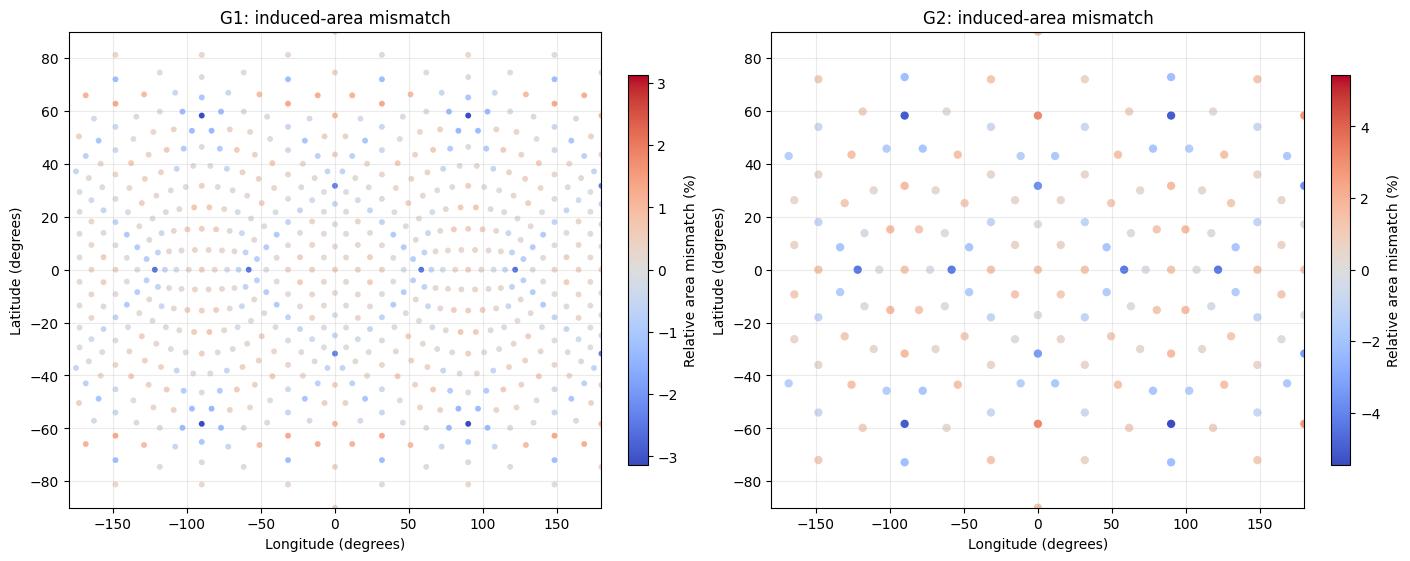


CELL 5E COMPLETED
Area mismatch and conservation diagnostics are available.
No transfer operators have been modified.


In [ ]:
# =============================================================================
# CELL 5E — AREA COMPATIBILITY AND CONSERVATION DIAGNOSTICS
# =============================================================================
#
# PURPOSE
# -------
# Investigate the compatibility of the monotone prolongation operators
# with the physical Voronoi cell areas on adjacent grid generations.
#
# For a fine grid f and coarse grid c, we have:
#
#     P : coarse -> fine
#
#     R = A_c^(-1) P.T A_f
#
# The prolongation preserves constants:
#
#     P 1_c = 1_f
#
# For restriction to preserve constants, we additionally require:
#
#     P.T A_f 1_f = A_c 1_c
#
# Define the area induced on the coarse grid by prolongation:
#
#     a_induced = P.T a_f
#
# and the relative area mismatch:
#
#     epsilon = (a_induced - a_c) / a_c
#
# We investigate:
#
#   1. Induced coarse-grid areas
#   2. Relative area mismatch
#   3. Spatial distribution of the mismatch
#   4. Relationship between mismatch and grid geometry
#   5. Conservation of the unnormalized composite P B R
#
# Here B is the coarse-grid GGF constructed in Cell 4A.
#
# No modifications to P, R, or B are made in this cell.
# =============================================================================

import matplotlib.pyplot as plt


print("=" * 78)
print("CELL 5E — AREA COMPATIBILITY AND CONSERVATION DIAGNOSTICS")
print("=" * 78)

area_compatibility_diagnostics = {}

diagnostic_rng = np.random.default_rng(20261028)


# =============================================================================
# PART 1 — AREA COMPATIBILITY
# =============================================================================

for coarse_name, fine_name, pname, rname in [
    ("G1", "G0", "P01", "R10"),
    ("G2", "G1", "P12", "R21")
]:

    P = monotone_prolongation[pname]
    R = restriction_operators[rname]

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nc = len(area_c)
    nf = len(area_f)

    # -------------------------------------------------------------------------
    # Induced coarse-grid areas
    #
    # Each coarse-grid area is obtained by collecting contributions
    # from all fine-grid cells through the prolongation weights.
    # -------------------------------------------------------------------------

    area_induced = np.asarray(
        P.T @ area_f
    ).ravel()

    area_difference = area_induced - area_c

    relative_mismatch = area_difference / area_c

    # -------------------------------------------------------------------------
    # Area-integral diagnostics
    # -------------------------------------------------------------------------

    total_area_f = np.sum(area_f)
    total_area_c = np.sum(area_c)
    total_area_induced = np.sum(area_induced)

    max_relative_mismatch = np.max(
        np.abs(relative_mismatch)
    )

    mean_relative_mismatch = np.mean(
        np.abs(relative_mismatch)
    )

    rms_relative_mismatch = np.sqrt(
        np.mean(relative_mismatch**2)
    )

    # -------------------------------------------------------------------------
    # Compare hexagonal and pentagonal coarse-grid vertices
    # -------------------------------------------------------------------------

    degrees = grids[coarse_name]["degrees"]

    hex_mask = degrees == 6
    pent_mask = degrees == 5

    hex_max = np.max(
        np.abs(relative_mismatch[hex_mask])
    )

    pent_max = np.max(
        np.abs(relative_mismatch[pent_mask])
    )

    # -------------------------------------------------------------------------
    # Verify the mathematical relationship:
    #
    #     R 1_f = area_induced / area_c
    #
    # -------------------------------------------------------------------------

    restriction_constant = R @ np.ones(nf)

    identity_error = np.max(
        np.abs(
            restriction_constant
            - area_induced / area_c
        )
    )

    print()
    print(f"{pname} / {rname}")
    print("-" * 78)

    print(f"Fine-grid cells                 : {nf}")
    print(f"Coarse-grid cells               : {nc}")

    print(f"Total fine area                 : {total_area_f:.12e}")
    print(f"Total coarse area               : {total_area_c:.12e}")
    print(f"Total induced area              : {total_area_induced:.12e}")

    print(
        f"Maximum relative mismatch       : "
        f"{max_relative_mismatch:.6e}"
    )

    print(
        f"Mean absolute relative mismatch : "
        f"{mean_relative_mismatch:.6e}"
    )

    print(
        f"RMS relative mismatch           : "
        f"{rms_relative_mismatch:.6e}"
    )

    print(
        f"Maximum hexagon mismatch        : "
        f"{hex_max:.6e}"
    )

    print(
        f"Maximum pentagon mismatch       : "
        f"{pent_max:.6e}"
    )

    print(
        f"Restriction identity error      : "
        f"{identity_error:.6e}"
    )

    verify(
        f"{pname}: induced-area identity",
        identity_error,
        1.0e-12
    )

    # -------------------------------------------------------------------------
    # Store diagnostics
    # -------------------------------------------------------------------------

    area_compatibility_diagnostics[pname] = {
        "area_induced": area_induced,
        "area_difference": area_difference,
        "relative_mismatch": relative_mismatch,
        "max_relative_mismatch": max_relative_mismatch,
        "mean_relative_mismatch": mean_relative_mismatch,
        "rms_relative_mismatch": rms_relative_mismatch,
        "hex_max": hex_max,
        "pent_max": pent_max
    }


# =============================================================================
# PART 2 — CONSERVATION OF UNNORMALIZED COARSE-GRID CONTRIBUTIONS
# =============================================================================
#
# Examine:
#
#     C = P B R
#
# where B is the coarse-grid GGF.
#
# We test:
#
#   - Constant preservation
#   - Conservation of the area integral
#   - Weighted self-adjointness
#
# =============================================================================

print()
print("=" * 78)
print("UNNORMALIZED COARSE-GENERATION CONTRIBUTIONS")
print("=" * 78)

for coarse_name, fine_name, pname, rname in [
    ("G1", "G0", "P01", "R10"),
    ("G2", "G1", "P12", "R21")
]:

    P = monotone_prolongation[pname]
    R = restriction_operators[rname]

    B = grids[coarse_name]["GGF"]

    area_f = grids[fine_name]["area"]

    nf = len(area_f)

    def apply_composite(x):
        return P @ B.apply(R @ x)

    # -------------------------------------------------------------------------
    # Constant preservation
    # -------------------------------------------------------------------------

    ones = np.ones(nf)

    constant_response = apply_composite(ones)

    constant_error = np.max(
        np.abs(constant_response - ones)
    )

    # -------------------------------------------------------------------------
    # Conservation for a smooth positive field
    # -------------------------------------------------------------------------

    vertices = grids[fine_name]["vertices"]

    x = (
        1.0
        + 0.2 * vertices[:, 0]
        + 0.1 * vertices[:, 1]
        + 0.05 * vertices[:, 2]
    )

    Cx = apply_composite(x)

    integral_before = np.dot(area_f, x)
    integral_after = np.dot(area_f, Cx)

    conservation_error = (
        abs(integral_after - integral_before)
        / max(
            1.0,
            abs(integral_before),
            abs(integral_after)
        )
    )

    # -------------------------------------------------------------------------
    # Weighted self-adjointness
    # -------------------------------------------------------------------------

    u = diagnostic_rng.standard_normal(nf)
    v = diagnostic_rng.standard_normal(nf)

    Cu = apply_composite(u)
    Cv = apply_composite(v)

    lhs = np.dot(area_f * u, Cv)
    rhs = np.dot(area_f * Cu, v)

    adjoint_error = (
        abs(lhs - rhs)
        / max(1.0, abs(lhs), abs(rhs))
    )

    print()
    print(f"Composite {pname} B {rname}")
    print("-" * 78)

    print(
        f"Constant-preservation error : "
        f"{constant_error:.6e}"
    )

    print(
        f"Relative integral error     : "
        f"{conservation_error:.6e}"
    )

    print(
        f"Weighted adjoint error      : "
        f"{adjoint_error:.6e}"
    )

    verify(
        f"{pname} B {rname}: weighted adjointness",
        adjoint_error,
        TOL_ADJOINT
    )

    area_compatibility_diagnostics[pname].update({
        "composite_constant_error": constant_error,
        "composite_conservation_error": conservation_error,
        "composite_adjoint_error": adjoint_error
    })


# =============================================================================
# PART 3 — VISUALIZE SPATIAL AREA MISMATCH
# =============================================================================
#
# Scatter plots in longitude/latitude coordinates.
#
# These plots show the coarse-grid locations where the area induced
# by prolongation differs from the physical coarse-grid Voronoi area.
#
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    constrained_layout=True
)

for ax, coarse_name, pname in zip(
    axes,
    ["G1", "G2"],
    ["P01", "P12"]
):

    vertices = grids[coarse_name]["vertices"]

    longitude = np.degrees(
        np.arctan2(
            vertices[:, 1],
            vertices[:, 0]
        )
    )

    latitude = np.degrees(
        np.arcsin(
            np.clip(vertices[:, 2], -1.0, 1.0)
        )
    )

    mismatch = area_compatibility_diagnostics[
        pname
    ]["relative_mismatch"]

    limit = np.max(np.abs(mismatch))

    scatter = ax.scatter(
        longitude,
        latitude,
        c=100.0 * mismatch,
        cmap="coolwarm",
        vmin=-100.0 * limit,
        vmax=100.0 * limit,
        s=18 if coarse_name == "G1" else 36,
        edgecolors="none"
    )

    ax.set_title(
        f"{coarse_name}: induced-area mismatch"
    )

    ax.set_xlabel("Longitude (degrees)")
    ax.set_ylabel("Latitude (degrees)")

    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

    ax.grid(
        True,
        alpha=0.25
    )

    colorbar = fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.82
    )

    colorbar.set_label(
        "Relative area mismatch (%)"
    )

plt.show()


print()
print("=" * 78)
print("CELL 5E COMPLETED")
print("Area mismatch and conservation diagnostics are available.")
print("No transfer operators have been modified.")
print("=" * 78)

### Cell 5F — Feasibility of Area-Compatible Monotone Prolongation

In [ ]:
# =============================================================================
# CELL 5F — FEASIBILITY OF AREA-COMPATIBLE MONOTONE PROLONGATION
# =============================================================================
#
# PURPOSE
# -------
# Determine whether a nonnegative prolongation matrix can satisfy:
#
#   1. Exact injection at coincident vertices
#   2. Constant preservation: P @ 1 = 1
#   3. Area compatibility: P.T @ area_f = area_c
#
# We use the existing local stencils from Cell 5A.
#
# The test is formulated as a sparse linear programming problem.
#
# IMPORTANT:
#   - This is a feasibility experiment.
#   - The existing Cell 5C and 5D operators are not modified.
#   - Local linear reproduction is measured after solving.
# =============================================================================

from scipy.optimize import linprog
from scipy.sparse import coo_matrix, vstack

print("=" * 78)
print("CELL 5F — AREA-COMPATIBILITY FEASIBILITY")
print("=" * 78)

feasibility_results = {}

for coarse_name, fine_name, pname in [
    ("G1", "G0", "P01"),
    ("G2", "G1", "P12")
]:

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    P_reference = monotone_prolongation[pname]

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nf, nc = P_reference.shape

    # -------------------------------------------------------------
    # Construct the list of allowed interpolation coefficients.
    #
    # At coincident vertices, only the injection coefficient
    # is permitted.
    # -------------------------------------------------------------

    row_indices = []
    col_indices = []

    for i in range(nf):

        stencil = geometry["stencils"][i]

        if geometry["nearest_distance"][i] < 1.0e-10:
            stencil = stencil[:1]

        for j in stencil:
            row_indices.append(i)
            col_indices.append(int(j))

    row_indices = np.asarray(row_indices, dtype=np.int64)
    col_indices = np.asarray(col_indices, dtype=np.int64)

    nvar = len(row_indices)

    # -------------------------------------------------------------
    # Row constraints:
    #
    #       sum_j P_ij = 1
    # -------------------------------------------------------------

    variable_indices = np.arange(nvar)

    A_rows = coo_matrix(
        (
            np.ones(nvar),
            (row_indices, variable_indices)
        ),
        shape=(nf, nvar)
    ).tocsr()

    b_rows = np.ones(nf)

    # -------------------------------------------------------------
    # Area-weighted column constraints:
    #
    #       sum_i area_f[i] * P_ij = area_c[j]
    #
    # Scale all areas by their mean to improve conditioning.
    # -------------------------------------------------------------

    area_scale = np.mean(area_f)

    area_f_scaled = area_f / area_scale
    area_c_scaled = area_c / area_scale

    A_cols = coo_matrix(
        (
            area_f_scaled[row_indices],
            (col_indices, variable_indices)
        ),
        shape=(nc, nvar)
    ).tocsr()

    b_cols = area_c_scaled

    # -------------------------------------------------------------
    # Assemble equality constraints.
    # -------------------------------------------------------------

    A_eq = vstack(
        [A_rows, A_cols],
        format="csr"
    )

    b_eq = np.concatenate(
        [b_rows, b_cols]
    )

    # -------------------------------------------------------------
    # Solve feasibility problem.
    #
    # Minimize zero subject to:
    #
    #       A_eq @ w = b_eq
    #       0 <= w <= 1
    #
    # -------------------------------------------------------------

    print()
    print(f"{pname}: {coarse_name} -> {fine_name}")
    print("-" * 78)

    print(f"Fine cells                : {nf}")
    print(f"Coarse cells              : {nc}")
    print(f"Allowed coefficients      : {nvar}")
    print(f"Equality constraints      : {len(b_eq)}")

    result = linprog(
        c=np.zeros(nvar),
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=(0.0, 1.0),
        method="highs",
        options={
            "primal_feasibility_tolerance": 1.0e-9,
            "dual_feasibility_tolerance": 1.0e-9
        }
    )

    print(f"Solver status             : {result.status}")
    print(f"Solver message            : {result.message}")

    if not result.success:

        feasibility_results[pname] = {
            "feasible": False,
            "message": result.message
        }

        print("Feasibility result        : NOT ESTABLISHED")

        continue

    # -------------------------------------------------------------
    # Construct feasible prolongation.
    # -------------------------------------------------------------

    P_feasible = coo_matrix(
        (
            result.x,
            (row_indices, col_indices)
        ),
        shape=(nf, nc)
    ).tocsr()

    P_feasible.eliminate_zeros()

    # -------------------------------------------------------------
    # Verify constant preservation and area compatibility.
    # -------------------------------------------------------------

    constant_error = np.max(
        np.abs(
            P_feasible @ np.ones(nc) - np.ones(nf)
        )
    )

    induced_area = P_feasible.T @ area_f

    relative_area_error = np.max(
        np.abs(induced_area - area_c) / area_c
    )

    minimum_weight = (
        P_feasible.data.min()
        if P_feasible.nnz else 0.0
    )

    # -------------------------------------------------------------
    # Measure local linear reproduction.
    #
    # These constraints were NOT imposed in this feasibility test.
    # -------------------------------------------------------------

    linear_errors = []

    for i in range(nf):

        if geometry["nearest_distance"][i] < 1.0e-10:
            continue

        stencil = geometry["stencils"][i]
        xy = geometry["stencil_xy"][i]
        target = geometry["target_xy"][i]

        weights = np.asarray(
            P_feasible[i, stencil].toarray()
        ).ravel()

        reproduced = weights @ xy

        linear_errors.append(
            np.linalg.norm(reproduced - target)
        )

    max_linear_error = max(linear_errors)

    print(f"Feasibility result        : FEASIBLE")
    print(f"Nonzero coefficients      : {P_feasible.nnz}")
    print(f"Minimum weight            : {minimum_weight:.6e}")
    print(f"Constant error            : {constant_error:.6e}")
    print(f"Relative area error       : {relative_area_error:.6e}")
    print(f"Maximum linear error      : {max_linear_error:.6e}")

    verify(
        f"{pname}: feasible constant preservation",
        constant_error,
        1.0e-8
    )

    verify(
        f"{pname}: feasible area compatibility",
        relative_area_error,
        1.0e-8
    )

    feasibility_results[pname] = {
        "feasible": True,
        "P": P_feasible,
        "constant_error": constant_error,
        "relative_area_error": relative_area_error,
        "max_linear_error": max_linear_error
    }


print()
print("=" * 78)
print("CELL 5F COMPLETED")
print("Original prolongation and restriction operators remain unchanged.")
print("=" * 78)

CELL 5F — AREA-COMPATIBILITY FEASIBILITY

P01: G1 -> G0
------------------------------------------------------------------------------
Fine cells                : 2562
Coarse cells              : 642
Allowed coefficients      : 14022
Equality constraints      : 3204
Solver status             : 0
Solver message            : Optimization terminated successfully. (HiGHS Status 7: Optimal)
Feasibility result        : FEASIBLE
Nonzero coefficients      : 3203
Minimum weight            : 8.750228e-04
Constant error            : 2.220446e-16
Relative area error       : 5.149635e-13
Maximum linear error      : 2.421367e-01
P01: feasible constant preservation           error = 2.220446e-16   tolerance = 1.0e-08   [PASS]
P01: feasible area compatibility              error = 5.149635e-13   tolerance = 1.0e-08   [PASS]

P12: G2 -> G1
------------------------------------------------------------------------------
Fine cells                : 642
Coarse cells              : 162
Allowed coefficients   

### Cell 5G — Full Feasibility Test with Linear Reproduction

In [ ]:
# =============================================================================
# CELL 5G — FULL FEASIBILITY TEST WITH LINEAR REPRODUCTION
# =============================================================================
#
# PURPOSE
# -------
# Determine whether the existing local interpolation stencils can satisfy
# all the following requirements simultaneously:
#
#   1. Exact injection at coincident coarse/fine vertices
#
#   2. Constant preservation:
#          P @ 1_c = 1_f
#
#   3. Area compatibility:
#          P.T @ area_f = area_c
#
#   4. Nonnegative interpolation weights:
#          P_ij >= 0
#
#   5. Exact local linear reproduction:
#          sum_j P_ij * x_j = x_target
#          sum_j P_ij * y_j = y_target
#
# Here x and y are coordinates in the local tangent plane used in Cell 5A.
#
# This is a sparse linear programming feasibility problem.
#
# IMPORTANT
# ---------
# We do not modify the previously constructed operators.
#
# A successful result demonstrates numerical feasibility of all constraints.
#
# An unsuccessful result does not necessarily prove mathematical
# infeasibility: solver status and residuals must be examined.
# =============================================================================

import time
from scipy.optimize import linprog
from scipy.sparse import coo_matrix, vstack

print("=" * 78)
print("CELL 5G — FULL FEASIBILITY WITH LINEAR REPRODUCTION")
print("=" * 78)

full_feasibility_results = {}

for coarse_name, fine_name, pname in [
    ("G1", "G0", "P01"),
    ("G2", "G1", "P12")
]:

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    P_reference = monotone_prolongation[pname]

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nf, nc = P_reference.shape

    # -------------------------------------------------------------------------
    # STEP 1 — Construct the allowed interpolation coefficients.
    #
    # At coincident vertices, allow only exact injection.
    #
    # At noncoincident vertices, use the complete local stencil.
    # -------------------------------------------------------------------------

    row_indices = []
    col_indices = []

    local_x = []
    local_y = []

    target_x = np.zeros(nf)
    target_y = np.zeros(nf)

    injection_count = 0

    for i in range(nf):

        stencil = np.asarray(
            geometry["stencils"][i],
            dtype=np.int64
        )

        xy = np.asarray(
            geometry["stencil_xy"][i],
            dtype=np.float64
        )

        target = np.asarray(
            geometry["target_xy"][i],
            dtype=np.float64
        )

        if geometry["nearest_distance"][i] < 1.0e-10:

            # Exact injection at coincident vertices.
            stencil = stencil[:1]
            xy = xy[:1]

            injection_count += 1

        target_x[i] = target[0]
        target_y[i] = target[1]

        for k, j in enumerate(stencil):

            row_indices.append(i)
            col_indices.append(int(j))

            local_x.append(float(xy[k, 0]))
            local_y.append(float(xy[k, 1]))

    row_indices = np.asarray(
        row_indices,
        dtype=np.int64
    )

    col_indices = np.asarray(
        col_indices,
        dtype=np.int64
    )

    local_x = np.asarray(
        local_x,
        dtype=np.float64
    )

    local_y = np.asarray(
        local_y,
        dtype=np.float64
    )

    nvar = len(row_indices)

    variable_indices = np.arange(
        nvar,
        dtype=np.int64
    )

    # -------------------------------------------------------------------------
    # STEP 2 — Row-sum constraints.
    #
    # For each fine-grid vertex i:
    #
    #       sum_j P_ij = 1
    # -------------------------------------------------------------------------

    A_constant = coo_matrix(
        (
            np.ones(nvar),
            (row_indices, variable_indices)
        ),
        shape=(nf, nvar)
    ).tocsr()

    b_constant = np.ones(nf)

    # -------------------------------------------------------------------------
    # STEP 3 — Local linear reproduction.
    #
    # For each fine-grid vertex i:
    #
    #       sum_j P_ij * x_j = x_target
    #       sum_j P_ij * y_j = y_target
    #
    # Scale coordinates to improve numerical conditioning.
    #
    # We use one characteristic scale per grid pair.
    # -------------------------------------------------------------------------

    coordinate_scale = max(
        np.max(np.abs(local_x)),
        np.max(np.abs(local_y)),
        np.max(np.abs(target_x)),
        np.max(np.abs(target_y))
    )

    if coordinate_scale <= 0.0:
        raise ValueError(
            f"{pname}: invalid coordinate scale"
        )

    A_linear_x = coo_matrix(
        (
            local_x / coordinate_scale,
            (row_indices, variable_indices)
        ),
        shape=(nf, nvar)
    ).tocsr()

    A_linear_y = coo_matrix(
        (
            local_y / coordinate_scale,
            (row_indices, variable_indices)
        ),
        shape=(nf, nvar)
    ).tocsr()

    b_linear_x = target_x / coordinate_scale
    b_linear_y = target_y / coordinate_scale

    # -------------------------------------------------------------------------
    # STEP 4 — Area compatibility.
    #
    # For each coarse-grid vertex j:
    #
    #       sum_i area_f[i] * P_ij = area_c[j]
    #
    # Scale physical areas by their mean.
    # -------------------------------------------------------------------------

    area_scale = np.mean(area_f)

    area_f_scaled = area_f / area_scale
    area_c_scaled = area_c / area_scale

    A_area = coo_matrix(
        (
            area_f_scaled[row_indices],
            (col_indices, variable_indices)
        ),
        shape=(nc, nvar)
    ).tocsr()

    b_area = area_c_scaled

    # -------------------------------------------------------------------------
    # STEP 5 — Assemble equality constraints.
    #
    # The complete system is:
    #
    #       A_eq @ w = b_eq
    #
    # with:
    #
    #       0 <= w <= 1
    # -------------------------------------------------------------------------

    A_eq = vstack(
        [
            A_constant,
            A_linear_x,
            A_linear_y,
            A_area
        ],
        format="csr"
    )

    b_eq = np.concatenate(
        [
            b_constant,
            b_linear_x,
            b_linear_y,
            b_area
        ]
    )

    # -------------------------------------------------------------------------
    # STEP 6 — Solve the sparse feasibility problem.
    #
    # The objective is zero: we seek any feasible solution.
    # -------------------------------------------------------------------------

    print()
    print(f"{pname}: {coarse_name} -> {fine_name}")
    print("-" * 78)

    print(f"Fine-grid cells           : {nf}")
    print(f"Coarse-grid cells         : {nc}")
    print(f"Injection rows            : {injection_count}")
    print(f"Allowed coefficients      : {nvar}")
    print(f"Equality constraints      : {A_eq.shape[0]}")
    print(f"Coordinate scale          : {coordinate_scale:.6e}")

    t0 = time.perf_counter()

    result = linprog(
        c=np.zeros(nvar),
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=(0.0, 1.0),
        method="highs",
        options={
            "primal_feasibility_tolerance": 1.0e-9,
            "dual_feasibility_tolerance": 1.0e-9
        }
    )

    elapsed = time.perf_counter() - t0

    print(f"Solver status             : {result.status}")
    print(f"Solver message            : {result.message}")
    print(f"Solver time               : {elapsed:.6f} s")

    # -------------------------------------------------------------------------
    # STEP 7 — Handle unsuccessful solver termination.
    #
    # We do not stop the notebook with an assertion here.
    # The solver result itself is scientifically informative.
    # -------------------------------------------------------------------------

    if not result.success:

        full_feasibility_results[pname] = {
            "feasible": False,
            "status": result.status,
            "message": result.message,
            "solver_time": elapsed
        }

        print()
        print("FULL FEASIBILITY: NOT ESTABLISHED")
        print("No new prolongation operator was constructed.")

        continue

    # -------------------------------------------------------------------------
    # STEP 8 — Construct the candidate prolongation matrix.
    # -------------------------------------------------------------------------

    P_candidate = coo_matrix(
        (
            result.x,
            (row_indices, col_indices)
        ),
        shape=(nf, nc)
    ).tocsr()

    P_candidate.eliminate_zeros()

    # -------------------------------------------------------------------------
    # STEP 9 — Verify constant preservation.
    # -------------------------------------------------------------------------

    constant_error = np.max(
        np.abs(
            P_candidate @ np.ones(nc)
            - np.ones(nf)
        )
    )

    # -------------------------------------------------------------------------
    # STEP 10 — Verify area compatibility.
    # -------------------------------------------------------------------------

    induced_area = np.asarray(
        P_candidate.T @ area_f
    ).ravel()

    relative_area_error = np.max(
        np.abs(induced_area - area_c) / area_c
    )

    # -------------------------------------------------------------------------
    # STEP 11 — Verify local linear reproduction.
    #
    # Evaluate the original unscaled tangent-plane coordinates.
    # -------------------------------------------------------------------------

    linear_errors = []

    for i in range(nf):

        stencil = geometry["stencils"][i]

        xy = geometry["stencil_xy"][i]
        target = geometry["target_xy"][i]

        weights = np.asarray(
            P_candidate[i, stencil].toarray()
        ).ravel()

        reproduced = weights @ xy

        linear_errors.append(
            np.linalg.norm(reproduced - target)
        )

    max_linear_error = np.max(linear_errors)

    # -------------------------------------------------------------------------
    # STEP 12 — Verify exact injection.
    # -------------------------------------------------------------------------

    coarse_in_fine = grids[coarse_name][
        f"indices_in_{fine_name}"
    ]

    injection_error = 0.0

    for j, i in enumerate(coarse_in_fine):

        row = P_candidate.getrow(
            int(i)
        ).toarray().ravel()

        expected = np.zeros(nc)
        expected[j] = 1.0

        injection_error = max(
            injection_error,
            np.max(np.abs(row - expected))
        )

    # -------------------------------------------------------------------------
    # STEP 13 — Verify nonnegative weights.
    # -------------------------------------------------------------------------

    minimum_weight = (
        P_candidate.data.min()
        if P_candidate.nnz
        else 0.0
    )

    # -------------------------------------------------------------------------
    # STEP 14 — Report diagnostics.
    # -------------------------------------------------------------------------

    print()
    print("Candidate operator diagnostics")
    print("-" * 78)

    print(f"Nonzero coefficients      : {P_candidate.nnz}")
    print(f"Minimum weight            : {minimum_weight:.6e}")
    print(f"Constant error            : {constant_error:.6e}")
    print(f"Relative area error       : {relative_area_error:.6e}")
    print(f"Maximum linear error      : {max_linear_error:.6e}")
    print(f"Injection error           : {injection_error:.6e}")

    verify(
        f"{pname}: full constant preservation",
        constant_error,
        1.0e-8
    )

    verify(
        f"{pname}: full area compatibility",
        relative_area_error,
        1.0e-8
    )

    verify(
        f"{pname}: full linear reproduction",
        max_linear_error,
        1.0e-8
    )

    verify(
        f"{pname}: full injection",
        injection_error,
        1.0e-8
    )

    verify(
        f"{pname}: full nonnegativity",
        max(0.0, -minimum_weight),
        1.0e-12
    )

    # -------------------------------------------------------------------------
    # STEP 15 — Store successful candidate.
    #
    # Do not overwrite the original Cell 5C prolongation.
    # -------------------------------------------------------------------------

    full_feasibility_results[pname] = {
        "feasible": True,
        "P": P_candidate,
        "constant_error": constant_error,
        "relative_area_error": relative_area_error,
        "max_linear_error": max_linear_error,
        "injection_error": injection_error,
        "minimum_weight": minimum_weight,
        "solver_time": elapsed
    }

    print()
    print("FULL FEASIBILITY: SUCCESS")


print()
print("=" * 78)
print("CELL 5G COMPLETED")
print("Original Cell 5C operators remain unchanged.")
print("=" * 78)

CELL 5G — FULL FEASIBILITY WITH LINEAR REPRODUCTION

P01: G1 -> G0
------------------------------------------------------------------------------
Fine-grid cells           : 2562
Coarse-grid cells         : 642
Injection rows            : 642
Allowed coefficients      : 14022
Equality constraints      : 8328
Coordinate scale          : 1.640883e-01
Solver status             : 0
Solver message            : Optimization terminated successfully. (HiGHS Status 7: Optimal)
Solver time               : 11.588889 s

Candidate operator diagnostics
------------------------------------------------------------------------------
Nonzero coefficients      : 6731
Minimum weight            : 1.250599e-04
Constant error            : 4.297673e-13
Relative area error       : 6.805118e-13
Maximum linear error      : 1.359107e-14
Injection error           : 0.000000e+00
P01: full constant preservation               error = 4.297673e-13   tolerance = 1.0e-08   [PASS]
P01: full area compatibility            

### Cell 5H — Optimization of Area-Compatible Monotone Prolongation

In [ ]:
# =============================================================================
# CELL 5H — OPTIMIZATION OF AREA-COMPATIBLE MONOTONE PROLONGATION
# =============================================================================
#
# PURPOSE
# -------
# Find an area-compatible, monotone, linearly exact prolongation that is
# as close as possible to the original Cell 5C interpolation.
#
# Minimize:
#
#     0.5 * ||w - w_reference||_2^2
#
# subject to:
#
#     P @ 1 = 1
#     P.T @ area_f = area_c
#     exact local linear reproduction
#     exact injection
#     w >= 0
#
# We solve the equivalent Euclidean projection problem with Dykstra's
# algorithm. Each iteration alternates between:
#
#     (1) the affine equality-constraint set
#     (2) the nonnegative orthant
#
# Dykstra corrections are retained, so the converged solution is the
# minimum-distance projection, not merely an arbitrary feasible point.
#
# Existing Cell 5C, 5D, and 5G operators remain unchanged.
# =============================================================================

import time
import numpy as np
import scipy.sparse as sp

from scipy.sparse.linalg import splu

print("=" * 78)
print("CELL 5H — AREA-COMPATIBLE PROLONGATION OPTIMIZATION")
print("=" * 78)


def build_projection_problem(coarse_name, fine_name, pname):

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    P_reference = monotone_prolongation[pname].tocsr()
    P_feasible = full_feasibility_results[pname]["P"].tocsr()

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nf, nc = P_reference.shape

    rows = []
    cols = []
    local_x = []
    local_y = []

    target_x = np.zeros(nf)
    target_y = np.zeros(nf)

    for i in range(nf):

        stencil = np.asarray(geometry["stencils"][i], dtype=int)
        xy = np.asarray(geometry["stencil_xy"][i], dtype=float)
        target = np.asarray(geometry["target_xy"][i], dtype=float)

        if geometry["nearest_distance"][i] < 1.0e-10:
            stencil = stencil[:1]
            xy = xy[:1]

        target_x[i] = target[0]
        target_y[i] = target[1]

        for k, j in enumerate(stencil):
            rows.append(i)
            cols.append(int(j))
            local_x.append(xy[k, 0])
            local_y.append(xy[k, 1])

    rows = np.asarray(rows, dtype=int)
    cols = np.asarray(cols, dtype=int)
    local_x = np.asarray(local_x, dtype=float)
    local_y = np.asarray(local_y, dtype=float)

    nvar = len(rows)
    vidx = np.arange(nvar)

    coordinate_scale = max(
        np.max(np.abs(local_x)),
        np.max(np.abs(local_y)),
        np.max(np.abs(target_x)),
        np.max(np.abs(target_y))
    )

    area_scale = np.mean(area_f)

    A0 = sp.coo_matrix(
        (np.ones(nvar), (rows, vidx)),
        shape=(nf, nvar)
    ).tocsr()

    Ax = sp.coo_matrix(
        (local_x / coordinate_scale, (rows, vidx)),
        shape=(nf, nvar)
    ).tocsr()

    Ay = sp.coo_matrix(
        (local_y / coordinate_scale, (rows, vidx)),
        shape=(nf, nvar)
    ).tocsr()

    Aa = sp.coo_matrix(
        (area_f[rows] / area_scale, (cols, vidx)),
        shape=(nc, nvar)
    ).tocsr()

    A = sp.vstack([A0, Ax, Ay, Aa], format="csr")

    b = np.concatenate([
        np.ones(nf),
        target_x / coordinate_scale,
        target_y / coordinate_scale,
        area_c / area_scale
    ])

    # Extract original and feasible weights on the same variable ordering.
    w_reference = np.asarray(P_reference[rows, cols]).ravel()
    w_feasible = np.asarray(P_feasible[rows, cols]).ravel()

    return {
        "A": A,
        "b": b,
        "rows": rows,
        "cols": cols,
        "shape": (nf, nc),
        "w_reference": w_reference,
        "w_feasible": w_feasible,
        "geometry": geometry,
        "area_f": area_f,
        "area_c": area_c
    }


def optimize_dykstra(problem, max_iterations=3000,
                     tolerance=1.0e-10,
                     report_every=100):

    A = problem["A"]
    b = problem["b"]

    w_reference = problem["w_reference"]
    w_feasible = problem["w_feasible"]

    # The equality system contains dependent constraints.
    #
    # Use a small regularization of A A.T to obtain a stable
    # approximate affine projection. Its residual is checked below.
    #
    # This regularized projection is a numerical approximation;
    # final feasibility and optimality must be verified.

    G = (A @ A.T).tocsc()

    diagonal_scale = max(
        float(np.max(np.abs(G.diagonal()))),
        1.0
    )

    regularization = 1.0e-12 * diagonal_scale

    G = G + regularization * sp.eye(G.shape[0], format="csc")

    factor = splu(G)

    def project_affine(v):

        residual = A @ v - b

        correction = A.T @ factor.solve(residual)

        return v - correction

    # Start from the original interpolation weights.
    #
    # Dykstra correction vectors.
    w = w_reference.copy()

    correction_affine = np.zeros_like(w)
    correction_positive = np.zeros_like(w)

    history = []

    start = time.perf_counter()

    for iteration in range(1, max_iterations + 1):

        # Projection onto equality constraints.
        z = w + correction_affine

        y = project_affine(z)

        correction_affine = z - y

        # Projection onto nonnegative orthant.
        z = y + correction_positive

        w_new = np.maximum(z, 0.0)

        correction_positive = z - w_new

        w = w_new

        if iteration == 1 or iteration % report_every == 0:

            equality_error = np.max(np.abs(A @ w - b))

            distance = np.linalg.norm(w - w_reference)

            history.append(
                (iteration, equality_error, distance)
            )

            print(
                f"iteration {iteration:5d}  "
                f"equality error = {equality_error:.3e}  "
                f"distance = {distance:.6e}"
            )

            if equality_error < tolerance:
                break

    elapsed = time.perf_counter() - start

    return w, history, elapsed, iteration


optimized_prolongation = {}
optimization_diagnostics = {}

for coarse_name, fine_name, pname in [
    ("G1", "G0", "P01"),
    ("G2", "G1", "P12")
]:

    print()
    print("=" * 78)
    print(f"OPTIMIZING {pname}: {coarse_name} -> {fine_name}")
    print("=" * 78)

    problem = build_projection_problem(
        coarse_name, fine_name, pname
    )

    print(f"Variables                 : {len(problem['w_reference'])}")
    print(f"Equality constraints      : {problem['A'].shape[0]}")

    w, history, elapsed, iterations = optimize_dykstra(
        problem,
        max_iterations=3000,
        tolerance=1.0e-10,
        report_every=100
    )

    rows = problem["rows"]
    cols = problem["cols"]

    nf, nc = problem["shape"]

    P_opt = sp.coo_matrix(
        (w, (rows, cols)),
        shape=(nf, nc)
    ).tocsr()

    P_opt.eliminate_zeros()

    area_f = problem["area_f"]
    area_c = problem["area_c"]

    constant_error = np.max(
        np.abs(P_opt @ np.ones(nc) - np.ones(nf))
    )

    relative_area_error = np.max(
        np.abs(P_opt.T @ area_f - area_c) / area_c
    )

    linear_errors = []

    geometry = problem["geometry"]

    for i in range(nf):

        stencil = geometry["stencils"][i]
        xy = geometry["stencil_xy"][i]
        target = geometry["target_xy"][i]

        weights = np.asarray(
            P_opt[i, stencil].toarray()
        ).ravel()

        linear_errors.append(
            np.linalg.norm(weights @ xy - target)
        )

    max_linear_error = max(linear_errors)

    distance_reference = np.linalg.norm(
        w - problem["w_reference"]
    )

    distance_feasible = np.linalg.norm(
        problem["w_feasible"] - problem["w_reference"]
    )

    print()
    print("Optimization results")
    print("-" * 78)

    print(f"Iterations                : {iterations}")
    print(f"Optimization time         : {elapsed:.3f} s")
    print(f"Nonzero coefficients      : {P_opt.nnz}")
    print(f"Minimum weight            : {P_opt.data.min():.6e}")
    print(f"Constant error            : {constant_error:.6e}")
    print(f"Relative area error       : {relative_area_error:.6e}")
    print(f"Maximum linear error      : {max_linear_error:.6e}")
    print(f"Distance from Cell 5C     : {distance_reference:.6e}")
    print(f"Cell 5G distance from 5C  : {distance_feasible:.6e}")

    optimized_prolongation[pname] = P_opt

    optimization_diagnostics[pname] = {
        "iterations": iterations,
        "time": elapsed,
        "constant_error": constant_error,
        "relative_area_error": relative_area_error,
        "linear_error": max_linear_error,
        "distance_reference": distance_reference,
        "distance_feasible": distance_feasible,
        "history": history
    }

print()
print("=" * 78)
print("CELL 5H COMPLETED")
print("Original transfer operators remain unchanged.")
print("=" * 78)

CELL 5H — AREA-COMPATIBLE PROLONGATION OPTIMIZATION

OPTIMIZING P01: G1 -> G0
Variables                 : 14022
Equality constraints      : 8328
iteration     1  equality error = 4.965e-02  distance = 4.995090e-01
iteration   100  equality error = 2.022e-03  distance = 9.159394e-01
iteration   200  equality error = 2.860e-04  distance = 9.336716e-01
iteration   300  equality error = 4.960e-05  distance = 9.352433e-01
iteration   400  equality error = 9.916e-06  distance = 9.353948e-01
iteration   500  equality error = 2.149e-06  distance = 9.354127e-01
iteration   600  equality error = 4.895e-07  distance = 9.354154e-01
iteration   700  equality error = 1.156e-07  distance = 9.354158e-01
iteration   800  equality error = 2.813e-08  distance = 9.354159e-01
iteration   900  equality error = 7.014e-09  distance = 9.354160e-01
iteration  1000  equality error = 1.783e-09  distance = 9.354160e-01
iteration  1100  equality error = 4.563e-10  distance = 9.354160e-01
iteration  1200  equality e

### Cell 5I — Validation of Optimized Multigrid Transfer Operators

CELL 5I — OPTIMIZED TRANSFER VALIDATION

P01 / R10: G1 -> G0

Quadratic-moment interpolation errors
------------------------------------------------------------------------------
Operator                       Maximum            Mean             RMS
Cell 5C original          6.380077e-03    5.138842e-03    5.187534e-03
Cell 5G feasible          1.981523e-02    1.318058e-02    1.359934e-02
Cell 5H optimized         7.026667e-03    5.300749e-03    5.360886e-03

Optimized transfer diagnostics
------------------------------------------------------------------------------
P constant error          : 2.325029e-11
R constant error          : 9.553691e-12
Area compatibility error  : 9.553512e-12
Minimum P weight          : 1.780236e-06
Injection error           : 2.094325e-11
Weighted adjoint error    : 3.345055e-16
Restriction conservation  : 4.352090e-13

Filtered composite diagnostics
------------------------------------------------------------------------------
Composite constant error  : 

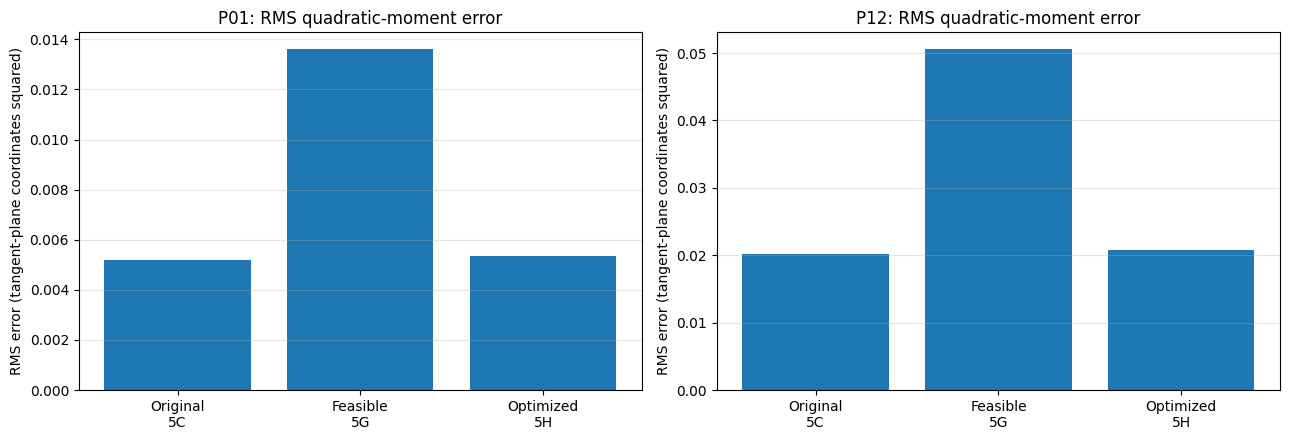


CELL 5I COMPLETED
Optimized restrictions and validation diagnostics are available.
Original transfer operators remain unchanged.


In [ ]:
# =============================================================================
# CELL 5I — VALIDATION OF OPTIMIZED MULTIGRID TRANSFER OPERATORS
# =============================================================================
#
# PURPOSE
# -------
# 1. Compare interpolation accuracy for:
#       Cell 5C: original monotone interpolation
#       Cell 5G: feasible area-compatible interpolation
#       Cell 5H: optimized area-compatible interpolation
#
# 2. Construct the area-weighted-adjoint restriction for Cell 5H.
#
# 3. Verify:
#       - constant preservation
#       - area compatibility
#       - exact injection
#       - nonnegativity
#       - weighted adjointness
#       - integral conservation
#
# 4. Verify the filtered composite:
#
#           C = P B R
#
#    where B is the coarse-generation graph filter.
#
# 5. Examine quadratic-moment interpolation errors.
#
# IMPORTANT
# ---------
# The original operators remain unchanged.
# =============================================================================

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

print("=" * 78)
print("CELL 5I — OPTIMIZED TRANSFER VALIDATION")
print("=" * 78)


def quadratic_moment_diagnostics(P, geometry):

    """
    Measure local quadratic reproduction errors.

    For each fine-grid vertex, compare the weighted coarse-grid
    quadratic monomials with their target values in the tangent plane.

    Monomials:
        x^2, y^2, xy

    These diagnostics measure quadratic consistency; they do not
    constitute a complete interpolation-error convergence study.
    """

    nf = P.shape[0]

    errors = []

    for i in range(nf):

        if geometry["nearest_distance"][i] < 1.0e-10:
            continue

        stencil = geometry["stencils"][i]

        xy = geometry["stencil_xy"][i]
        target = geometry["target_xy"][i]

        weights = np.asarray(
            P[i, stencil].toarray()
        ).ravel()

        x = xy[:, 0]
        y = xy[:, 1]

        xt, yt = target

        reproduced = np.array([
            weights @ (x * x),
            weights @ (y * y),
            weights @ (x * y)
        ])

        expected = np.array([
            xt * xt,
            yt * yt,
            xt * yt
        ])

        errors.append(
            np.linalg.norm(reproduced - expected)
        )

    errors = np.asarray(errors)

    return {
        "maximum": np.max(errors),
        "mean": np.mean(errors),
        "rms": np.sqrt(np.mean(errors**2)),
        "values": errors
    }


optimized_restriction = {}
optimized_transfer_validation = {}

for coarse_name, fine_name, pname, rname in [
    ("G1", "G0", "P01", "R10"),
    ("G2", "G1", "P12", "R21")
]:

    print()
    print("=" * 78)
    print(f"{pname} / {rname}: {coarse_name} -> {fine_name}")
    print("=" * 78)

    key = f"{coarse_name}_to_{fine_name}"

    geometry = interpolation_geometry[key]

    P_original = monotone_prolongation[pname].tocsr()
    P_feasible = full_feasibility_results[pname]["P"].tocsr()
    P_optimized = optimized_prolongation[pname].tocsr()

    area_f = grids[fine_name]["area"]
    area_c = grids[coarse_name]["area"]

    nf, nc = P_optimized.shape

    # -------------------------------------------------------------------------
    # STEP 1 — Compare quadratic-moment errors.
    # -------------------------------------------------------------------------

    q_original = quadratic_moment_diagnostics(
        P_original, geometry
    )

    q_feasible = quadratic_moment_diagnostics(
        P_feasible, geometry
    )

    q_optimized = quadratic_moment_diagnostics(
        P_optimized, geometry
    )

    print()
    print("Quadratic-moment interpolation errors")
    print("-" * 78)

    print(
        f"{'Operator':<22}"
        f"{'Maximum':>16}"
        f"{'Mean':>16}"
        f"{'RMS':>16}"
    )

    for label, q in [
        ("Cell 5C original", q_original),
        ("Cell 5G feasible", q_feasible),
        ("Cell 5H optimized", q_optimized)
    ]:

        print(
            f"{label:<22}"
            f"{q['maximum']:>16.6e}"
            f"{q['mean']:>16.6e}"
            f"{q['rms']:>16.6e}"
        )

    # -------------------------------------------------------------------------
    # STEP 2 — Construct optimized area-weighted-adjoint restriction.
    #
    #       R = A_c^{-1} P.T A_f
    # -------------------------------------------------------------------------

    R_optimized = (
        sp.diags(1.0 / area_c)
        @ P_optimized.T
        @ sp.diags(area_f)
    ).tocsr()

    optimized_restriction[rname] = R_optimized

    # -------------------------------------------------------------------------
    # STEP 3 — Verify constant preservation and area compatibility.
    # -------------------------------------------------------------------------

    ones_f = np.ones(nf)
    ones_c = np.ones(nc)

    P_constant_error = np.max(
        np.abs(P_optimized @ ones_c - ones_f)
    )

    R_constant_error = np.max(
        np.abs(R_optimized @ ones_f - ones_c)
    )

    induced_area = P_optimized.T @ area_f

    area_error = np.max(
        np.abs(induced_area - area_c) / area_c
    )

    minimum_weight = P_optimized.data.min()

    # -------------------------------------------------------------------------
    # STEP 4 — Verify exact injection.
    # -------------------------------------------------------------------------

    coarse_in_fine = grids[coarse_name][
        f"indices_in_{fine_name}"
    ]

    injection_error = 0.0

    for j, i in enumerate(coarse_in_fine):

        row = P_optimized.getrow(
            int(i)
        ).toarray().ravel()

        expected = np.zeros(nc)
        expected[j] = 1.0

        injection_error = max(
            injection_error,
            np.max(np.abs(row - expected))
        )

    # -------------------------------------------------------------------------
    # STEP 5 — Verify weighted adjointness.
    #
    #       <P u, v>_Af = <u, R v>_Ac
    # -------------------------------------------------------------------------

    u = rng.standard_normal(nc)
    v = rng.standard_normal(nf)

    lhs = np.sum(area_f * (P_optimized @ u) * v)
    rhs = np.sum(area_c * u * (R_optimized @ v))

    adjoint_error = (
        abs(lhs - rhs)
        / max(abs(lhs), abs(rhs), 1.0)
    )

    # -------------------------------------------------------------------------
    # STEP 6 — Verify restriction conservation.
    # -------------------------------------------------------------------------

    x = (
        1.0
        + 0.2 * grids[fine_name]["vertices"][:, 0]
        + 0.1 * grids[fine_name]["vertices"][:, 1]
        + 0.05 * grids[fine_name]["vertices"][:, 2]
    )

    restricted = R_optimized @ x

    integral_f = np.sum(area_f * x)
    integral_c = np.sum(area_c * restricted)

    restriction_conservation_error = (
        abs(integral_f - integral_c)
        / max(abs(integral_f), 1.0)
    )

    # -------------------------------------------------------------------------
    # STEP 7 — Construct the filtered composite:
    #
    #       C x = P B R x
    # -------------------------------------------------------------------------

    coarse_filter = grids[coarse_name]["GGF"]

    def apply_composite(field):

        return P_optimized @ coarse_filter.apply(
            R_optimized @ field
        )

    # -------------------------------------------------------------------------
    # STEP 8 — Composite constant preservation.
    # -------------------------------------------------------------------------

    composite_constant_error = np.max(
        np.abs(
            apply_composite(ones_f) - ones_f
        )
    )

    # -------------------------------------------------------------------------
    # STEP 9 — Composite integral conservation.
    # -------------------------------------------------------------------------

    y = apply_composite(x)

    composite_conservation_error = (
        abs(np.sum(area_f * y) - np.sum(area_f * x))
        / max(abs(np.sum(area_f * x)), 1.0)
    )

    # -------------------------------------------------------------------------
    # STEP 10 — Composite weighted adjointness.
    # -------------------------------------------------------------------------

    u_f = rng.standard_normal(nf)
    v_f = rng.standard_normal(nf)

    lhs = np.sum(
        area_f * u_f * apply_composite(v_f)
    )

    rhs = np.sum(
        area_f * apply_composite(u_f) * v_f
    )

    composite_adjoint_error = (
        abs(lhs - rhs)
        / max(abs(lhs), abs(rhs), 1.0)
    )

    # -------------------------------------------------------------------------
    # STEP 11 — Composite positivity.
    #
    # A nonnegative input should remain nonnegative.
    # -------------------------------------------------------------------------

    positive_input = np.abs(
        rng.standard_normal(nf)
    )

    positive_output = apply_composite(
        positive_input
    )

    minimum_composite_output = np.min(
        positive_output
    )

    # -------------------------------------------------------------------------
    # STEP 12 — Report diagnostics.
    # -------------------------------------------------------------------------

    print()
    print("Optimized transfer diagnostics")
    print("-" * 78)

    print(f"P constant error          : {P_constant_error:.6e}")
    print(f"R constant error          : {R_constant_error:.6e}")
    print(f"Area compatibility error  : {area_error:.6e}")
    print(f"Minimum P weight          : {minimum_weight:.6e}")
    print(f"Injection error           : {injection_error:.6e}")
    print(f"Weighted adjoint error    : {adjoint_error:.6e}")
    print(
        f"Restriction conservation  : "
        f"{restriction_conservation_error:.6e}"
    )

    print()
    print("Filtered composite diagnostics")
    print("-" * 78)

    print(
        f"Composite constant error  : "
        f"{composite_constant_error:.6e}"
    )

    print(
        f"Composite conservation    : "
        f"{composite_conservation_error:.6e}"
    )

    print(
        f"Composite adjoint error   : "
        f"{composite_adjoint_error:.6e}"
    )

    print(
        f"Minimum positive response : "
        f"{minimum_composite_output:.6e}"
    )

    # -------------------------------------------------------------------------
    # STEP 13 — Formal verification.
    # -------------------------------------------------------------------------

    verify(
        f"{pname}: optimized P constant",
        P_constant_error,
        1.0e-9
    )

    verify(
        f"{pname}: optimized R constant",
        R_constant_error,
        1.0e-9
    )

    verify(
        f"{pname}: optimized area compatibility",
        area_error,
        1.0e-9
    )

    verify(
        f"{pname}: optimized injection",
        injection_error,
        1.0e-9
    )

    verify(
        f"{pname}: optimized weighted adjoint",
        adjoint_error,
        1.0e-9
    )

    verify(
        f"{pname}: optimized restriction conservation",
        restriction_conservation_error,
        1.0e-9
    )

    verify(
        f"{pname}: composite constant",
        composite_constant_error,
        1.0e-9
    )

    verify(
        f"{pname}: composite conservation",
        composite_conservation_error,
        1.0e-9
    )

    verify(
        f"{pname}: composite adjoint",
        composite_adjoint_error,
        1.0e-9
    )

    verify(
        f"{pname}: composite positivity",
        max(0.0, -minimum_composite_output),
        1.0e-12
    )

    optimized_transfer_validation[pname] = {
        "quadratic_original": q_original,
        "quadratic_feasible": q_feasible,
        "quadratic_optimized": q_optimized,
        "P_constant_error": P_constant_error,
        "R_constant_error": R_constant_error,
        "area_error": area_error,
        "composite_constant_error": composite_constant_error,
        "composite_conservation_error": composite_conservation_error,
        "composite_adjoint_error": composite_adjoint_error,
        "minimum_composite_output": minimum_composite_output
    }


# =============================================================================
# STEP 14 — Plot quadratic-moment error comparisons.
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for ax, pname in zip(
    axes,
    ["P01", "P12"]
):

    d = optimized_transfer_validation[pname]

    labels = [
        "Original\n5C",
        "Feasible\n5G",
        "Optimized\n5H"
    ]

    values = [
        d["quadratic_original"]["rms"],
        d["quadratic_feasible"]["rms"],
        d["quadratic_optimized"]["rms"]
    ]

    ax.bar(labels, values)

    ax.set_title(
        f"{pname}: RMS quadratic-moment error"
    )

    ax.set_ylabel(
        "RMS error (tangent-plane coordinates squared)"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

plt.tight_layout()
plt.show()


print()
print("=" * 78)
print("CELL 5I COMPLETED")
print("Optimized restrictions and validation diagnostics are available.")
print("Original transfer operators remain unchanged.")
print("=" * 78)

### Cell 6A — Construction and Validation of the Three-Generation MGGF

In [ ]:
# =============================================================================
# CELL 6A — CONSTRUCTION AND VALIDATION OF THE THREE-GENERATION MGGF
# =============================================================================
#
# Three-generation operator:
#
#   M = w0 B0
#     + w1 P01 B1 R10
#     + w2 P01 P12 B2 R21 R10
#
# B0, B1, B2:
#   Single-generation graph filters from Cell 4A.
#
# P01, P12:
#   Optimized area-compatible prolongations from Cell 5H.
#
# R10, R21:
#   Area-weighted-adjoint restrictions from Cell 5I.
#
# Initial weights:
#   w0 = w1 = w2 = 1/3
#
# Properties to verify:
#   - Constant preservation
#   - Integral conservation
#   - Area-weighted self-adjointness
#   - Positivity
#   - Positive semidefiniteness (sampled quadratic forms)
#   - Impulse mass conservation
#   - Computational timing
#
# All calculations are performed on the existing global icosahedral grids.
# No external files are required.
# =============================================================================

import time
import numpy as np

print("=" * 78)
print("CELL 6A — THREE-GENERATION MGGF")
print("=" * 78)


# =============================================================================
# STEP 1 — Retrieve validated components
# =============================================================================

P01 = optimized_prolongation["P01"].tocsr()
P12 = optimized_prolongation["P12"].tocsr()

R10 = optimized_restriction["R10"].tocsr()
R21 = optimized_restriction["R21"].tocsr()

B0 = grids["G0"]["GGF"]
B1 = grids["G1"]["GGF"]
B2 = grids["G2"]["GGF"]

area0 = grids["G0"]["area"]
area1 = grids["G1"]["area"]
area2 = grids["G2"]["area"]

n0 = len(area0)
n1 = len(area1)
n2 = len(area2)

print()
print("Grid hierarchy")
print("-" * 78)

print(f"G0 cells : {n0}")
print(f"G1 cells : {n1}")
print(f"G2 cells : {n2}")

print()
print("Transfer operators")
print("-" * 78)

print(f"P01 shape : {P01.shape}")
print(f"R10 shape : {R10.shape}")
print(f"P12 shape : {P12.shape}")
print(f"R21 shape : {R21.shape}")


# =============================================================================
# STEP 2 — Define the complete matrix-free MGGF
# =============================================================================

class ThreeGenerationMGGF:

    """
    Three-generation multigrid graph filter.

    The operator is

        M = w0 B0
          + w1 P01 B1 R10
          + w2 P01 P12 B2 R21 R10

    where the generation weights are nonnegative and sum to one.

    The implementation is matrix-free with respect to the complete
    MGGF operator. Sparse transfer matrices and previously factored
    single-generation graph filters are reused.
    """

    def __init__(
        self,
        B0,
        B1,
        B2,
        P01,
        P12,
        R10,
        R21,
        weights=(1/3, 1/3, 1/3)
    ):

        self.B0 = B0
        self.B1 = B1
        self.B2 = B2

        self.P01 = P01
        self.P12 = P12

        self.R10 = R10
        self.R21 = R21

        self.set_weights(weights)

    def set_weights(self, weights):

        weights = np.asarray(weights, dtype=float)

        if weights.shape != (3,):
            raise ValueError("Exactly three generation weights required.")

        if not np.all(np.isfinite(weights)):
            raise ValueError("Generation weights must be finite.")

        if np.any(weights < 0):
            raise ValueError("Generation weights must be nonnegative.")

        if not np.isclose(np.sum(weights), 1.0, atol=1e-12):
            raise ValueError("Generation weights must sum to one.")

        self.weights = weights.copy()

    def apply_components(self, field):

        """
        Return the three unweighted generation contributions.
        """

        field = np.asarray(field, dtype=float)

        if field.shape != (self.P01.shape[0],):
            raise ValueError("Input field has incorrect shape.")

        # ---------------------------------------------------------
        # Generation G0
        # ---------------------------------------------------------

        c0 = self.B0.apply(field)

        # ---------------------------------------------------------
        # Restrict G0 -> G1
        # ---------------------------------------------------------

        x1 = self.R10 @ field

        # ---------------------------------------------------------
        # Generation G1
        # ---------------------------------------------------------

        c1 = self.P01 @ self.B1.apply(x1)

        # ---------------------------------------------------------
        # Restrict G1 -> G2
        # ---------------------------------------------------------

        x2 = self.R21 @ x1

        # ---------------------------------------------------------
        # Generation G2
        # ---------------------------------------------------------

        c2 = (
            self.P01
            @ (
                self.P12
                @ self.B2.apply(x2)
            )
        )

        return c0, c1, c2

    def apply(self, field):

        c0, c1, c2 = self.apply_components(field)

        w0, w1, w2 = self.weights

        return (
            w0 * c0
            + w1 * c1
            + w2 * c2
        )


# =============================================================================
# STEP 3 — Instantiate MGGF
# =============================================================================

MGGF = ThreeGenerationMGGF(
    B0=B0,
    B1=B1,
    B2=B2,
    P01=P01,
    P12=P12,
    R10=R10,
    R21=R21,
    weights=(1/3, 1/3, 1/3)
)

print()
print("Generation weights")
print("-" * 78)

print(f"w0 = {MGGF.weights[0]:.8f}")
print(f"w1 = {MGGF.weights[1]:.8f}")
print(f"w2 = {MGGF.weights[2]:.8f}")


# =============================================================================
# STEP 4 — Constant preservation
# =============================================================================

ones = np.ones(n0)

constant_output = MGGF.apply(ones)

constant_error = np.max(
    np.abs(constant_output - ones)
)

print()
print("Constant preservation")
print("-" * 78)

print(f"Maximum error : {constant_error:.6e}")

verify(
    "Three-generation MGGF: constant preservation",
    constant_error,
    1.0e-9
)


# =============================================================================
# STEP 5 — Integral conservation
# =============================================================================

vertices0 = grids["G0"]["vertices"]

smooth_field = (
    1.0
    + 0.2 * vertices0[:, 0]
    + 0.1 * vertices0[:, 1]
    + 0.05 * vertices0[:, 2]
)

smooth_output = MGGF.apply(smooth_field)

integral_input = np.sum(
    area0 * smooth_field
)

integral_output = np.sum(
    area0 * smooth_output
)

conservation_error = (
    abs(integral_output - integral_input)
    / max(abs(integral_input), 1.0)
)

print()
print("Integral conservation")
print("-" * 78)

print(f"Relative integral error : {conservation_error:.6e}")

verify(
    "Three-generation MGGF: conservation",
    conservation_error,
    1.0e-9
)


# =============================================================================
# STEP 6 — Area-weighted self-adjointness
# =============================================================================

u = rng.standard_normal(n0)
v = rng.standard_normal(n0)

Mu = MGGF.apply(u)
Mv = MGGF.apply(v)

lhs = np.sum(area0 * u * Mv)
rhs = np.sum(area0 * Mu * v)

adjoint_error = (
    abs(lhs - rhs)
    / max(abs(lhs), abs(rhs), 1.0)
)

print()
print("Weighted self-adjointness")
print("-" * 78)

print(f"Relative adjoint error : {adjoint_error:.6e}")

verify(
    "Three-generation MGGF: weighted adjointness",
    adjoint_error,
    1.0e-9
)


# =============================================================================
# STEP 7 — Positivity
# =============================================================================

positive_input = np.abs(
    rng.standard_normal(n0)
)

positive_output = MGGF.apply(
    positive_input
)

minimum_positive_output = np.min(
    positive_output
)

print()
print("Positivity")
print("-" * 78)

print(f"Minimum output : {minimum_positive_output:.6e}")

verify(
    "Three-generation MGGF: positivity",
    max(0.0, -minimum_positive_output),
    1.0e-12
)


# =============================================================================
# STEP 8 — Positive semidefiniteness
#
# For random vectors x, evaluate:
#
#       <x, Mx>_A
#
# A nonnegative result is necessary for positive semidefiniteness.
# These sampled tests do not constitute a complete spectral proof.
# =============================================================================

quadratic_forms = []

for _ in range(10):

    x = rng.standard_normal(n0)

    Mx = MGGF.apply(x)

    q = np.sum(
        area0 * x * Mx
    )

    quadratic_forms.append(q)

minimum_quadratic_form = min(
    quadratic_forms
)

print()
print("Positive semidefiniteness")
print("-" * 78)

print(
    f"Minimum sampled quadratic form : "
    f"{minimum_quadratic_form:.6e}"
)

verify(
    "Three-generation MGGF: sampled PSD",
    max(0.0, -minimum_quadratic_form),
    1.0e-10
)


# =============================================================================
# STEP 9 — Impulse response
#
# Use a unit-integral impulse:
#
#       impulse[source] = 1 / area0[source]
#
# The integral of the input is exactly one.
# =============================================================================

source = grids["G0"]["GGF_impulse_source"]

impulse = np.zeros(n0)

impulse[source] = 1.0 / area0[source]

impulse_output = MGGF.apply(
    impulse
)

impulse_mass = np.sum(
    area0 * impulse_output
)

impulse_mass_error = abs(
    impulse_mass - 1.0
)

print()
print("Impulse conservation")
print("-" * 78)

print(f"Impulse source : {source}")
print(f"Output mass    : {impulse_mass:.12f}")
print(f"Mass error     : {impulse_mass_error:.6e}")

verify(
    "Three-generation MGGF: impulse conservation",
    impulse_mass_error,
    1.0e-9
)


# =============================================================================
# STEP 10 — Timing
#
# Repeated applications are timed after factorization.
# =============================================================================

n_timing = 20

timing_input = rng.standard_normal(n0)

# Warm-up
MGGF.apply(timing_input)

t0 = time.perf_counter()

for _ in range(n_timing):
    MGGF.apply(timing_input)

elapsed = time.perf_counter() - t0

average_time = elapsed / n_timing

print()
print("Computational timing")
print("-" * 78)

print(f"Applications      : {n_timing}")
print(f"Total time        : {elapsed:.6f} s")
print(f"Average time      : {average_time:.6f} s")


# =============================================================================
# STEP 11 — Store results for subsequent figures and diagnostics
# =============================================================================

mggf_validation = {
    "constant_error": constant_error,
    "conservation_error": conservation_error,
    "adjoint_error": adjoint_error,
    "minimum_positive_output": minimum_positive_output,
    "minimum_quadratic_form": minimum_quadratic_form,
    "impulse_source": source,
    "impulse_input": impulse,
    "impulse_output": impulse_output,
    "impulse_mass": impulse_mass,
    "impulse_mass_error": impulse_mass_error,
    "average_application_time": average_time,
    "weights": MGGF.weights.copy()
}

print()
print("=" * 78)
print("CELL 6A COMPLETED")
print("Three-generation MGGF constructed and validated.")
print("Impulse-response data are available for the next cell.")
print("=" * 78)

CELL 6A — THREE-GENERATION MGGF

Grid hierarchy
------------------------------------------------------------------------------
G0 cells : 2562
G1 cells : 642
G2 cells : 162

Transfer operators
------------------------------------------------------------------------------
P01 shape : (2562, 642)
R10 shape : (642, 2562)
P12 shape : (642, 162)
R21 shape : (162, 642)

Generation weights
------------------------------------------------------------------------------
w0 = 0.33333333
w1 = 0.33333333
w2 = 0.33333333

Constant preservation
------------------------------------------------------------------------------
Maximum error : 2.143197e-11
Three-generation MGGF: constant preservation  error = 2.143197e-11   tolerance = 1.0e-09   [PASS]

Integral conservation
------------------------------------------------------------------------------
Relative integral error : 5.650856e-13
Three-generation MGGF: conservation           error = 5.650856e-13   tolerance = 1.0e-09   [PASS]

Weighted self-adjo

### Cell 6B — Hexagon and Pentagon Impulse Responses

CELL 6B — HEXAGON AND PENTAGON IMPULSE RESPONSES

Hexagon source : 2052
Pentagon source: 0

Hexagon source 2052
------------------------------------------------------------------------------
G0           integral = 1.000000000000
Hexagon G0: impulse mass                      error = 4.440892e-16   tolerance = 1.0e-09   [PASS]
G1           integral = 1.000000000001
Hexagon G1: impulse mass                      error = 1.091571e-12   tolerance = 1.0e-09   [PASS]
G2           integral = 1.000000000005
Hexagon G2: impulse mass                      error = 4.790612e-12   tolerance = 1.0e-09   [PASS]
Combined     integral = 1.000000000002
Hexagon Combined: impulse mass                error = 1.960432e-12   tolerance = 1.0e-09   [PASS]

Pentagon source 0
------------------------------------------------------------------------------
G0           integral = 1.000000000000
Pentagon G0: impulse mass                     error = 7.771561e-15   tolerance = 1.0e-09   [PASS]
G1           integral = 1.

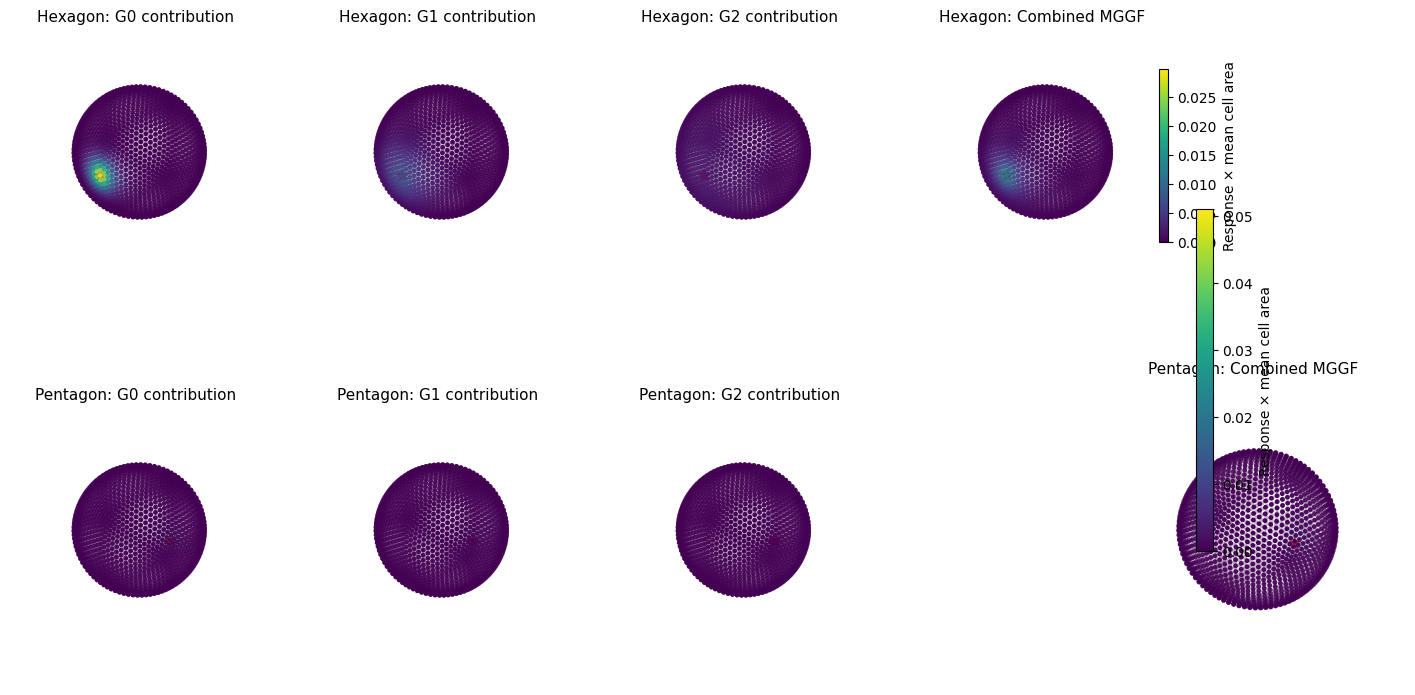


RESPONSE SUMMARY

Hexagon
------------------------------------------------------------------------------
G0 contribution     minimum = 4.692503e-30  maximum = 1.501569e-13
Hexagon: G0 contribution nonnegativity        error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
G1 contribution     minimum = 7.557536e-21  maximum = 3.794164e-14
Hexagon: G1 contribution nonnegativity        error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
G2 contribution     minimum = 5.625081e-17  maximum = 1.032880e-14
Hexagon: G2 contribution nonnegativity        error = 0.000000e+00   tolerance = 1.0e-12   [PASS]
Combined MGGF       minimum = 1.875279e-17  maximum = 6.614245e-14
Hexagon: Combined MGGF nonnegativity          error = 0.000000e+00   tolerance = 1.0e-12   [PASS]

Pentagon
------------------------------------------------------------------------------
G0 contribution     minimum = 1.127727e-30  maximum = 2.563481e-13
Pentagon: G0 contribution nonnegativity       error = 0.000000e+00   tolerance

In [ ]:
# =============================================================================
# CELL 6B — HEXAGON AND PENTAGON IMPULSE RESPONSES
# =============================================================================
#
# Display the three generation contributions and the combined MGGF response.
#
# Each impulse has unit area-weighted integral:
#
#     impulse[source] = 1 / area0[source]
#
# To make the response amplitudes easier to interpret, plot
#
#     response * mean(area0)
#
# This scaling is used ONLY for visualization.
#
# The actual MGGF responses remain unchanged.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D

print("=" * 78)
print("CELL 6B — HEXAGON AND PENTAGON IMPULSE RESPONSES")
print("=" * 78)

vertices = grids["G0"]["vertices"]
areas = grids["G0"]["area"]
degrees = grids["G0"]["degrees"]

n = len(areas)

# -------------------------------------------------------------------------
# STEP 1 — Choose source vertices.
#
# Prefer the source already used in Cell 6A if it is a hexagon.
# Choose a pentagon separately.
# -------------------------------------------------------------------------

hexagon_candidates = np.where(degrees == 6)[0]
pentagon_candidates = np.where(degrees == 5)[0]

previous_source = int(mggf_validation["impulse_source"])

if degrees[previous_source] == 6:
    hex_source = previous_source
else:
    hex_source = int(hexagon_candidates[0])

pent_source = int(pentagon_candidates[0])

sources = [
    ("Hexagon", hex_source),
    ("Pentagon", pent_source)
]

print()
print(f"Hexagon source : {hex_source}")
print(f"Pentagon source: {pent_source}")


# -------------------------------------------------------------------------
# STEP 2 — Evaluate the three unweighted contributions.
# -------------------------------------------------------------------------

impulse_results = {}

for label, source in sources:

    impulse = np.zeros(n)
    impulse[source] = 1.0 / areas[source]

    c0, c1, c2 = MGGF.apply_components(impulse)

    combined = MGGF.apply(impulse)

    contributions = [c0, c1, c2, combined]

    masses = [
        np.sum(areas * field)
        for field in contributions
    ]

    impulse_results[label] = {
        "source": source,
        "impulse": impulse,
        "contributions": contributions,
        "masses": masses
    }

    print()
    print(f"{label} source {source}")
    print("-" * 78)

    for name, mass in zip(
        ["G0", "G1", "G2", "Combined"],
        masses
    ):
        print(f"{name:<12} integral = {mass:.12f}")

        verify(
            f"{label} {name}: impulse mass",
            abs(mass - 1.0),
            1.0e-9
        )


# -------------------------------------------------------------------------
# STEP 3 — Plot spherical response fields.
#
# Each source row uses a common color scale.
# -------------------------------------------------------------------------

fig = plt.figure(figsize=(18, 9))

titles = [
    "G0 contribution",
    "G1 contribution",
    "G2 contribution",
    "Combined MGGF"
]

mean_area = np.mean(areas)

for row, (label, source) in enumerate(sources):

    fields = impulse_results[label]["contributions"]

    scaled_fields = [
        field * mean_area
        for field in fields
    ]

    vmax = max(
        np.max(field)
        for field in scaled_fields
    )

    norm = Normalize(vmin=0.0, vmax=vmax)

    for col, (title, field) in enumerate(
        zip(titles, scaled_fields)
    ):

        ax = fig.add_subplot(
            2, 4,
            row * 4 + col + 1,
            projection="3d"
        )

        scatter = ax.scatter(
            vertices[:, 0],
            vertices[:, 1],
            vertices[:, 2],
            c=field,
            cmap="viridis",
            norm=norm,
            s=12,
            linewidths=0
        )

        # Mark the impulse source.
        ax.scatter(
            [vertices[source, 0]],
            [vertices[source, 1]],
            [vertices[source, 2]],
            color="red",
            s=65,
            marker="*",
            depthshade=False
        )

        ax.set_box_aspect((1, 1, 1))

        ax.view_init(
            elev=25,
            azim=35
        )

        ax.set_axis_off()

        ax.set_title(
            f"{label}: {title}",
            fontsize=11
        )

    # One shared colorbar for the entire source row.
    fig.colorbar(
        plt.cm.ScalarMappable(
            norm=norm,
            cmap="viridis"
        ),
        ax=fig.axes[row * 4:(row + 1) * 4],
        shrink=0.55,
        pad=0.02,
        label="Response × mean cell area"
    )

plt.show()


# -------------------------------------------------------------------------
# STEP 4 — Summarize response amplitudes and positivity.
# -------------------------------------------------------------------------

print()
print("=" * 78)
print("RESPONSE SUMMARY")
print("=" * 78)

for label, result in impulse_results.items():

    print()
    print(label)
    print("-" * 78)

    for name, field in zip(
        titles,
        result["contributions"]
    ):

        print(
            f"{name:<20}"
            f"minimum = {field.min():.6e}  "
            f"maximum = {field.max():.6e}"
        )

        verify(
            f"{label}: {name} nonnegativity",
            max(0.0, -field.min()),
            1.0e-12
        )


print()
print("=" * 78)
print("CELL 6B COMPLETED")
print("Hexagon and pentagon impulse responses are available.")
print("=" * 78)

### Cell 6C — Source-Centered Hexagon and Pentagon Responses

CELL 6C — SOURCE-CENTERED IMPULSE RESPONSE VISUALIZATION


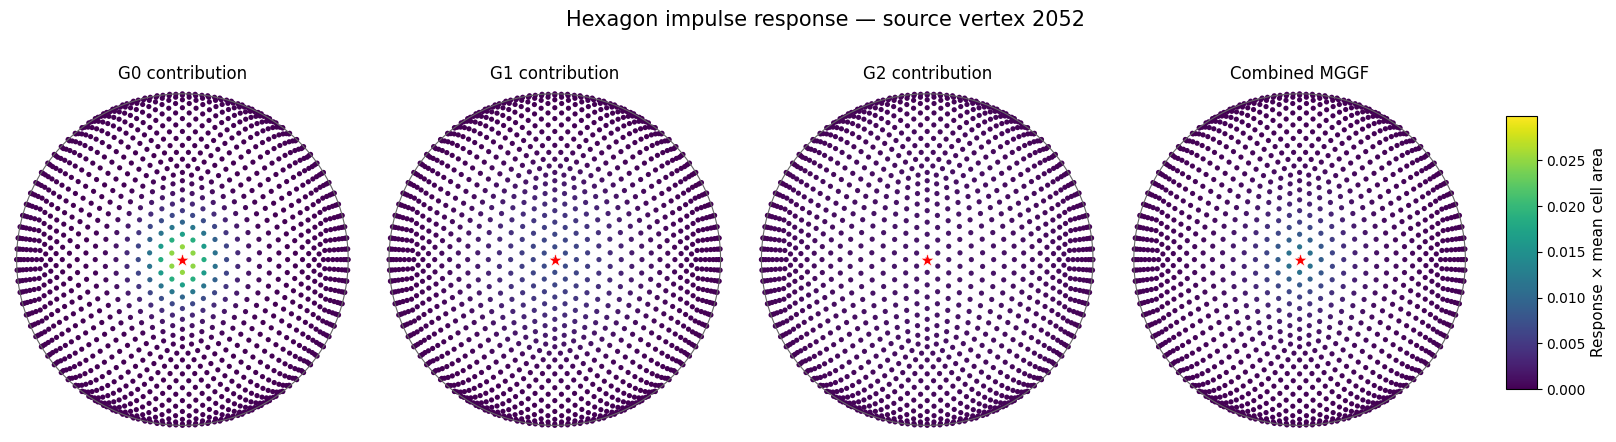

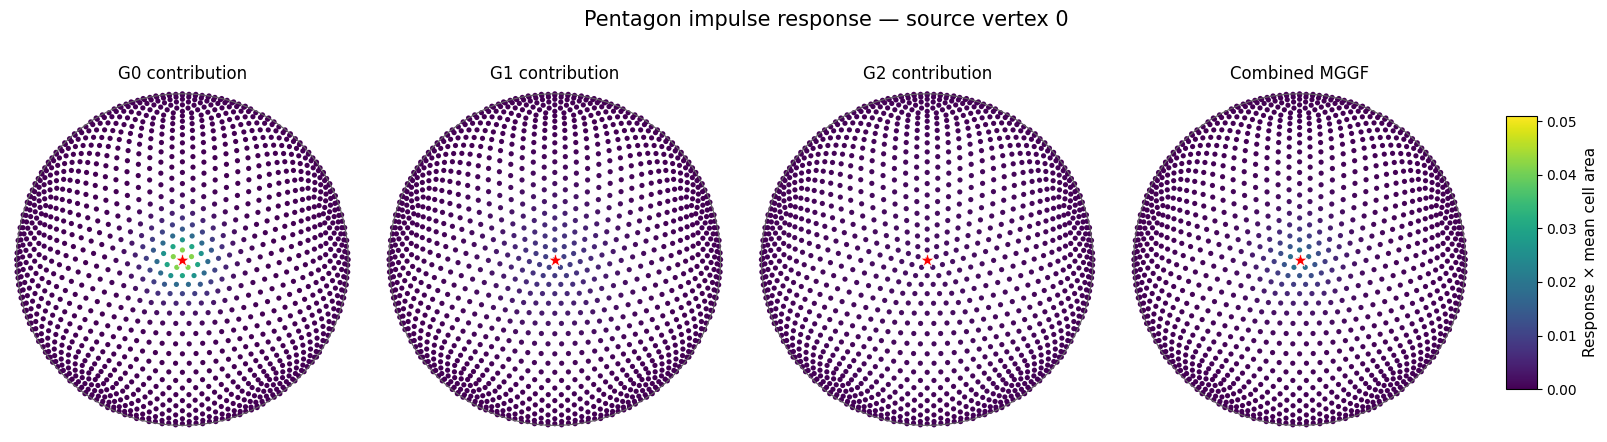


CELL 6C COMPLETED
Both impulse responses are displayed in source-centered coordinates.


In [ ]:
# =============================================================================
# CELL 6C — SOURCE-CENTERED IMPULSE RESPONSE VISUALIZATION
# =============================================================================
#
# PURPOSE
# -------
# Improve the visualization of the impulse responses from Cell 6B.
#
# For each source:
#   - Rotate the sphere so the source is centered toward the viewer.
#   - Display the G0, G1, G2, and combined responses.
#   - Use a common color scale for all four panels.
#   - Place the colorbar outside the panels.
#   - Mark the source vertex.
#
# The physical responses and the MGGF operator are unchanged.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

print("=" * 78)
print("CELL 6C — SOURCE-CENTERED IMPULSE RESPONSE VISUALIZATION")
print("=" * 78)

vertices = grids["G0"]["vertices"]
areas = grids["G0"]["area"]
mean_area = np.mean(areas)

panel_titles = [
    "G0 contribution",
    "G1 contribution",
    "G2 contribution",
    "Combined MGGF"
]


def source_centered_coordinates(vertices, source):

    """
    Rotate unit-sphere coordinates into an orthonormal frame
    whose positive z-axis points toward the impulse source.

    The source is therefore located at (0, 0, 1).
    """

    ez = np.asarray(vertices[source], dtype=float)
    ez = ez / np.linalg.norm(ez)

    reference = np.array([0.0, 0.0, 1.0])

    if abs(np.dot(ez, reference)) > 0.9:
        reference = np.array([0.0, 1.0, 0.0])

    ex = np.cross(reference, ez)
    ex /= np.linalg.norm(ex)

    ey = np.cross(ez, ex)
    ey /= np.linalg.norm(ey)

    return np.column_stack([
        vertices @ ex,
        vertices @ ey,
        vertices @ ez
    ])


for label in ["Hexagon", "Pentagon"]:

    result = impulse_results[label]

    source = result["source"]
    fields = result["contributions"]

    rotated = source_centered_coordinates(
        vertices, source
    )

    # Show only the hemisphere facing the source.
    visible = rotated[:, 2] >= 0.0

    # Scale amplitudes for readable colorbar values.
    scaled_fields = [
        field * mean_area
        for field in fields
    ]

    vmax = max(
        np.max(field)
        for field in scaled_fields
    )

    norm = Normalize(
        vmin=0.0,
        vmax=vmax
    )

    fig, axes = plt.subplots(
        1, 4,
        figsize=(17, 4.8),
        sharex=True,
        sharey=True
    )

    for ax, title, field in zip(
        axes,
        panel_titles,
        scaled_fields
    ):

        # Plot the visible hemisphere using an orthographic
        # projection onto the plane perpendicular to the source.
        scatter = ax.scatter(
            rotated[visible, 0],
            rotated[visible, 1],
            c=field[visible],
            cmap="viridis",
            norm=norm,
            s=14,
            linewidths=0
        )

        # Draw the outline of the visible hemisphere.
        theta = np.linspace(0, 2*np.pi, 400)

        ax.plot(
            np.cos(theta),
            np.sin(theta),
            color="0.4",
            linewidth=0.8
        )

        # The source is at the center.
        ax.scatter(
            [0.0],
            [0.0],
            marker="*",
            s=110,
            color="red",
            edgecolors="white",
            linewidths=0.5,
            zorder=10
        )

        ax.set_aspect("equal")

        ax.set_xlim(-1.04, 1.04)
        ax.set_ylim(-1.04, 1.04)

        ax.set_title(
            title,
            fontsize=12
        )

        ax.axis("off")

    fig.suptitle(
        f"{label} impulse response — source vertex {source}",
        fontsize=15,
        y=0.98
    )

    # Reserve space for a single colorbar.
    fig.subplots_adjust(
        left=0.02,
        right=0.88,
        bottom=0.08,
        top=0.84,
        wspace=0.08
    )

    cax = fig.add_axes([
        0.90, 0.19, 0.018, 0.57
    ])

    colorbar = fig.colorbar(
        plt.cm.ScalarMappable(
            norm=norm,
            cmap="viridis"
        ),
        cax=cax
    )

    colorbar.set_label(
        "Response × mean cell area",
        fontsize=11
    )

    plt.show()


print()
print("=" * 78)
print("CELL 6C COMPLETED")
print("Both impulse responses are displayed in source-centered coordinates.")
print("=" * 78)

### Cell 6D — Radial Spread and Isotropy Diagnostics

CELL 6D — RADIAL SPREAD AND ISOTROPY DIAGNOSTICS

HEXAGON SOURCE — VERTEX 2052
Response           r_eff         r50         r90         r95     Median CV
                    (km)        (km)        (km)        (km)              
G0               1706.97     1306.35     2637.95     3091.74        0.1818
Hexagon G0: radial mass                       error = 4.440892e-16   tolerance = 1.0e-09   [PASS]
G1               3340.60     2637.95     5172.18     6050.55        0.1075
Hexagon G1: radial mass                       error = 1.091571e-12   tolerance = 1.0e-09   [PASS]
G2               6308.47     4970.67     9753.22    11306.45        0.0302
Hexagon G2: radial mass                       error = 4.790612e-12   tolerance = 1.0e-09   [PASS]
Combined         4237.54     2517.98     7030.84     8787.60        0.0462
Hexagon Combined: radial mass                 error = 1.960432e-12   tolerance = 1.0e-09   [PASS]

PENTAGON SOURCE — VERTEX 0
Response           r_eff         r50         r90   

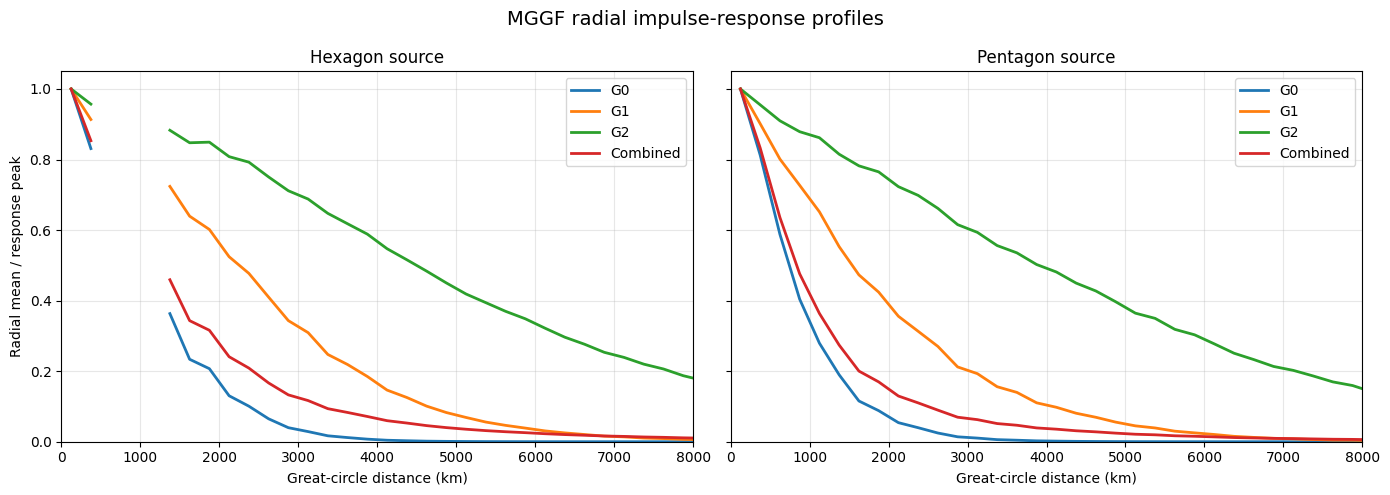

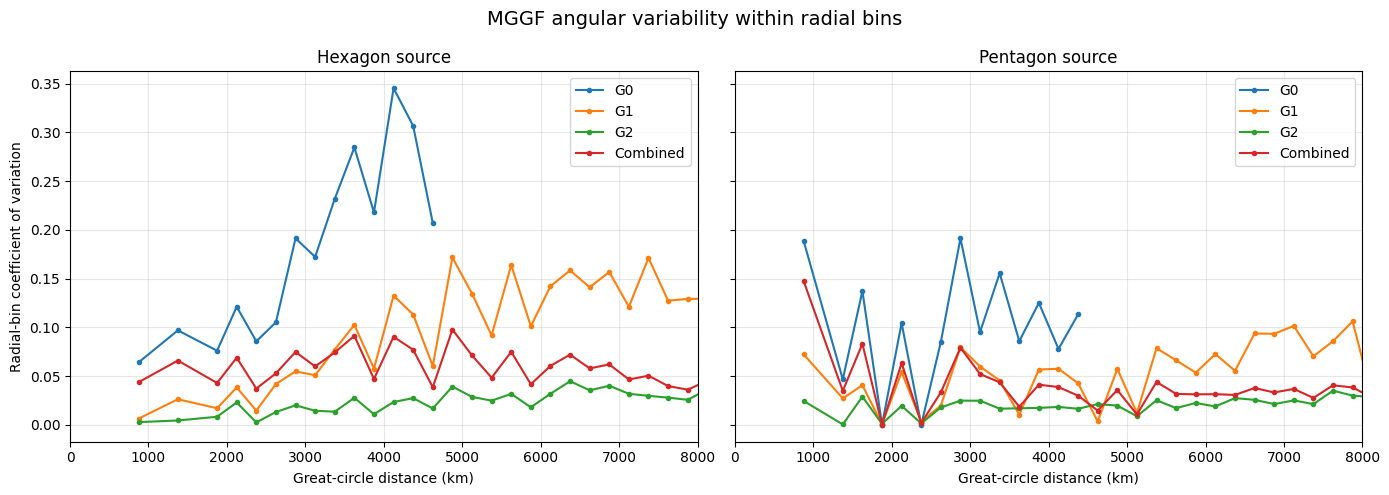


HEXAGON–PENTAGON EFFECTIVE-RADIUS COMPARISON
Response        Hexagon (km)   Pentagon (km)    Difference (%)
G0                   1706.97         1466.58           -14.083
G1                   3340.60         3205.26            -4.051
G2                   6308.47         6222.80            -1.358
Combined             4237.54         4129.08            -2.559

CELL 6D COMPLETED
Radial spread and isotropy diagnostics are available.
The MGGF operator remains unchanged.


In [ ]:
# =============================================================================
# CELL 6D — RADIAL SPREAD AND ISOTROPY DIAGNOSTICS
# =============================================================================
#
# PURPOSE
# -------
# Quantify the spatial structure of the three-generation MGGF.
#
# For hexagonal and pentagonal unit-integral impulses, calculate:
#
#   1. Effective radius (second radial moment)
#   2. Mass-containment radii: r50, r90, r95
#   3. Radial response profiles
#   4. Angular variability within radial bins
#   5. Hexagon/pentagon comparisons
#
# The response kernels are those calculated in Cell 6B.
#
# IMPORTANT
# ---------
# All mass and moment diagnostics use the original, unnormalized
# response fields.
#
# Only the plotted radial response profiles are divided by their
# individual maximum values to compare their shapes.
#
# The MGGF operator is not modified.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("CELL 6D — RADIAL SPREAD AND ISOTROPY DIAGNOSTICS")
print("=" * 78)

vertices = grids["G0"]["vertices"]
areas = grids["G0"]["area"]

R_EARTH = EARTH_RADIUS

response_names = [
    "G0",
    "G1",
    "G2",
    "Combined"
]

response_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red"
]

# Radial bins in kilometers.
#
# The maximum great-circle distance on the sphere is pi * R.
# A fixed bin width allows direct comparison between sources.

BIN_WIDTH_KM = 250.0

MAX_DISTANCE_KM = np.pi * R_EARTH / 1000.0

radial_edges = np.arange(
    0.0,
    MAX_DISTANCE_KM + BIN_WIDTH_KM,
    BIN_WIDTH_KM
)

if radial_edges[-1] < MAX_DISTANCE_KM:
    radial_edges = np.append(
        radial_edges,
        MAX_DISTANCE_KM
    )

radial_centers = 0.5 * (
    radial_edges[:-1] + radial_edges[1:]
)

# Minimum number of cells required for an angular-variation
# diagnostic in a radial bin.
#
# This avoids interpreting very small samples as meaningful
# measurements of isotropy.

MIN_BIN_CELLS = 8

# A small relative-response threshold excludes distant bins
# dominated by extremely weak tails.

RELATIVE_PROFILE_THRESHOLD = 1.0e-3


# =============================================================================
# STEP 1 — Great-circle distance
# =============================================================================

def great_circle_distances(vertices, source, radius):

    """
    Great-circle distances from a source vertex.

    All vertex coordinates are unit vectors.
    """

    source_vector = vertices[source]

    dot_products = vertices @ source_vector

    dot_products = np.clip(
        dot_products,
        -1.0,
        1.0
    )

    angles = np.arccos(dot_products)

    # Ensure an exactly zero source distance.
    angles[source] = 0.0

    return radius * angles


# =============================================================================
# STEP 2 — Mass-containment radius
# =============================================================================

def mass_containment_radius(distances, masses, fraction):

    """
    Return the smallest sampled distance enclosing the
    requested fraction of total response mass.

    This is a discrete cumulative-mass diagnostic.
    """

    order = np.argsort(distances)

    sorted_distances = distances[order]
    sorted_masses = masses[order]

    cumulative = np.cumsum(sorted_masses)

    total_mass = cumulative[-1]

    if total_mass <= 0.0:
        raise ValueError(
            "Response mass must be positive."
        )

    target_mass = fraction * total_mass

    index = np.searchsorted(
        cumulative,
        target_mass,
        side="left"
    )

    index = min(
        index,
        len(sorted_distances) - 1
    )

    return sorted_distances[index]


# =============================================================================
# STEP 3 — Radial profile and isotropy diagnostics
# =============================================================================

def calculate_radial_diagnostics(
    source,
    response,
    distances,
    areas,
    radial_edges
):

    """
    Calculate response spread and radial-bin diagnostics.

    Radial profile:
        arithmetic mean of response values within each bin.

    Relative angular variation:
        standard deviation / mean response within each bin.

    The angular variation is meaningful only when enough
    vertices occupy a bin and the response is appreciable.
    """

    response = np.asarray(response, dtype=float)

    mass_per_cell = areas * response

    total_mass = np.sum(mass_per_cell)

    if total_mass <= 0.0:
        raise ValueError(
            "Nonpositive total response mass."
        )

    # ---------------------------------------------------------------------
    # Effective radius.
    # ---------------------------------------------------------------------

    second_moment = (
        np.sum(mass_per_cell * distances**2)
        / total_mass
    )

    effective_radius = np.sqrt(second_moment)

    # ---------------------------------------------------------------------
    # Mass-containment radii.
    # ---------------------------------------------------------------------

    r50 = mass_containment_radius(
        distances, mass_per_cell, 0.50
    )

    r90 = mass_containment_radius(
        distances, mass_per_cell, 0.90
    )

    r95 = mass_containment_radius(
        distances, mass_per_cell, 0.95
    )

    # ---------------------------------------------------------------------
    # Radial bins.
    # ---------------------------------------------------------------------

    nbins = len(radial_edges) - 1

    bin_index = np.searchsorted(
        radial_edges,
        distances / 1000.0,
        side="right"
    ) - 1

    bin_index = np.clip(
        bin_index,
        0,
        nbins - 1
    )

    radial_mean = np.full(nbins, np.nan)
    radial_std = np.full(nbins, np.nan)
    radial_cv = np.full(nbins, np.nan)

    bin_counts = np.zeros(nbins, dtype=int)

    for k in range(nbins):

        mask = bin_index == k

        count = np.count_nonzero(mask)

        bin_counts[k] = count

        if count == 0:
            continue

        values = response[mask]

        radial_mean[k] = np.mean(values)

        radial_std[k] = np.std(values)

        if (
            count >= MIN_BIN_CELLS
            and radial_mean[k] > 0.0
        ):
            radial_cv[k] = (
                radial_std[k] / radial_mean[k]
            )

    # ---------------------------------------------------------------------
    # Normalize radial mean by peak response for plotting.
    # ---------------------------------------------------------------------

    peak = np.max(response)

    normalized_profile = radial_mean / peak

    # ---------------------------------------------------------------------
    # Define the bins where angular variation is sufficiently
    # resolved and the response is not negligible.
    # ---------------------------------------------------------------------

    valid_anisotropy = (
        (bin_counts >= MIN_BIN_CELLS)
        & np.isfinite(radial_cv)
        & (normalized_profile >= RELATIVE_PROFILE_THRESHOLD)
    )

    # A simple summary diagnostic.
    #
    # This is the median of radial-bin coefficients of variation,
    # not a global rotational-invariance measure.

    if np.any(valid_anisotropy):

        median_radial_cv = np.median(
            radial_cv[valid_anisotropy]
        )

        maximum_radial_cv = np.max(
            radial_cv[valid_anisotropy]
        )

    else:

        median_radial_cv = np.nan
        maximum_radial_cv = np.nan

    return {
        "source": source,
        "mass": total_mass,
        "effective_radius_km": effective_radius / 1000.0,
        "r50_km": r50 / 1000.0,
        "r90_km": r90 / 1000.0,
        "r95_km": r95 / 1000.0,
        "radial_mean": radial_mean,
        "radial_std": radial_std,
        "radial_cv": radial_cv,
        "normalized_profile": normalized_profile,
        "bin_counts": bin_counts,
        "valid_anisotropy": valid_anisotropy,
        "median_radial_cv": median_radial_cv,
        "maximum_radial_cv": maximum_radial_cv
    }


# =============================================================================
# STEP 4 — Calculate diagnostics for both sources
# =============================================================================

radial_diagnostics = {}

for source_label in ["Hexagon", "Pentagon"]:

    source_data = impulse_results[source_label]

    source = source_data["source"]

    distances = great_circle_distances(
        vertices,
        source,
        R_EARTH
    )

    radial_diagnostics[source_label] = {}

    print()
    print("=" * 78)
    print(
        f"{source_label.upper()} SOURCE — "
        f"VERTEX {source}"
    )
    print("=" * 78)

    print(
        f"{'Response':<12}"
        f"{'r_eff':>12}"
        f"{'r50':>12}"
        f"{'r90':>12}"
        f"{'r95':>12}"
        f"{'Median CV':>14}"
    )

    print(
        f"{'':12}"
        f"{'(km)':>12}"
        f"{'(km)':>12}"
        f"{'(km)':>12}"
        f"{'(km)':>12}"
        f"{'':>14}"
    )

    for name, response in zip(
        response_names,
        source_data["contributions"]
    ):

        diagnostics = calculate_radial_diagnostics(
            source,
            response,
            distances,
            areas,
            radial_edges
        )

        radial_diagnostics[source_label][name] = diagnostics

        print(
            f"{name:<12}"
            f"{diagnostics['effective_radius_km']:>12.2f}"
            f"{diagnostics['r50_km']:>12.2f}"
            f"{diagnostics['r90_km']:>12.2f}"
            f"{diagnostics['r95_km']:>12.2f}"
            f"{diagnostics['median_radial_cv']:>14.4f}"
        )

        verify(
            f"{source_label} {name}: radial mass",
            abs(diagnostics["mass"] - 1.0),
            1.0e-9
        )


# =============================================================================
# STEP 5 — Plot normalized radial profiles
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, source_label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    for name, color in zip(
        response_names,
        response_colors
    ):

        d = radial_diagnostics[source_label][name]

        ax.plot(
            radial_centers,
            d["normalized_profile"],
            label=name,
            color=color,
            linewidth=2
        )

    ax.set_title(
        f"{source_label} source"
    )

    ax.set_xlabel(
        "Great-circle distance (km)"
    )

    ax.set_xlim(
        0,
        8000
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.grid(
        alpha=0.3
    )

    ax.legend()

axes[0].set_ylabel(
    "Radial mean / response peak"
)

fig.suptitle(
    "MGGF radial impulse-response profiles",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 6 — Plot radial angular-variation diagnostics
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, source_label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    for name, color in zip(
        response_names,
        response_colors
    ):

        d = radial_diagnostics[source_label][name]

        valid = d["valid_anisotropy"]

        ax.plot(
            radial_centers[valid],
            d["radial_cv"][valid],
            marker="o",
            markersize=3,
            linewidth=1.5,
            color=color,
            label=name
        )

    ax.set_title(
        f"{source_label} source"
    )

    ax.set_xlabel(
        "Great-circle distance (km)"
    )

    ax.set_xlim(
        0,
        8000
    )

    ax.grid(
        alpha=0.3
    )

    ax.legend()

axes[0].set_ylabel(
    "Radial-bin coefficient of variation"
)

fig.suptitle(
    "MGGF angular variability within radial bins",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 7 — Compare effective radii for hexagon and pentagon
# =============================================================================

print()
print("=" * 78)
print("HEXAGON–PENTAGON EFFECTIVE-RADIUS COMPARISON")
print("=" * 78)

print(
    f"{'Response':<12}"
    f"{'Hexagon (km)':>16}"
    f"{'Pentagon (km)':>16}"
    f"{'Difference (%)':>18}"
)

for name in response_names:

    rh = radial_diagnostics["Hexagon"][name][
        "effective_radius_km"
    ]

    rp = radial_diagnostics["Pentagon"][name][
        "effective_radius_km"
    ]

    relative_difference = (
        100.0 * (rp - rh) / rh
    )

    print(
        f"{name:<12}"
        f"{rh:>16.2f}"
        f"{rp:>16.2f}"
        f"{relative_difference:>18.3f}"
    )


print()
print("=" * 78)
print("CELL 6D COMPLETED")
print("Radial spread and isotropy diagnostics are available.")
print("The MGGF operator remains unchanged.")
print("=" * 78)

### Cell 6E — Source Dependence and Spatial Uniformity of MGGF

CELL 6E — SOURCE DEPENDENCE AND SPATIAL UNIFORMITY

Source selection
------------------------------------------------------------------------------
Hexagonal sources : 60
Pentagonal sources: 12
Total sources     : 72

Evaluation time: 0.832 s

EFFECTIVE-RADIUS DISTRIBUTIONS

HEXAGON
------------------------------------------------------------------------------
Response         Mean km      Std km        CV %      Min km      Max km
G0               1663.36       59.25       3.562     1499.81     1706.97
G1               3344.33       33.21       0.993     3254.56     3381.18
G2               6351.75       32.92       0.518     6269.87     6395.91
Combined         4254.37       29.98       0.705     4169.45     4289.67

Maximum impulse-mass error: 2.514744e-11
Hexagon: all impulse masses                   error = 2.514744e-11   tolerance = 1.0e-09   [PASS]

PENTAGON
------------------------------------------------------------------------------
Response         Mean km      Std km       

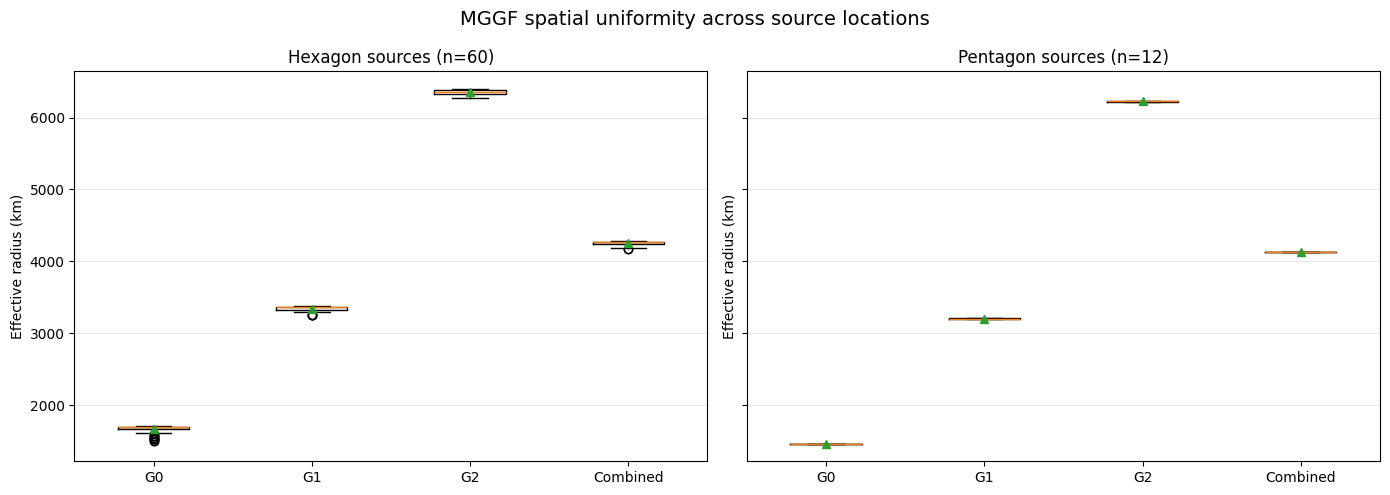

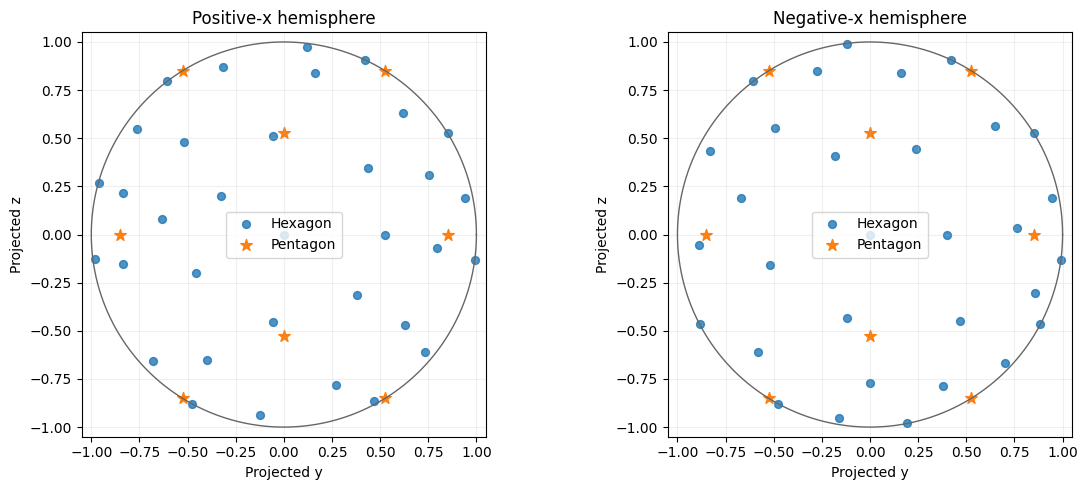


CELL 6E COMPLETED
Spatial-uniformity diagnostics are available.
MGGF operators and generation weights remain unchanged.


In [ ]:
# =============================================================================
# CELL 6E — SOURCE DEPENDENCE AND SPATIAL UNIFORMITY OF MGGF
# =============================================================================
#
# PURPOSE
# -------
# Evaluate the dependence of impulse-response spread on source location
# and source-cell topology.
#
# Sources:
#   - All 12 pentagons
#   - 60 geographically distributed hexagons
#
# Diagnostics:
#   - Effective radius for G0, G1, G2, and combined MGGF
#   - Mean, standard deviation, coefficient of variation
#   - Minimum and maximum effective radius
#   - Hexagon/pentagon comparison
#   - Verification of impulse conservation
#
# No changes are made to the MGGF operator.
# =============================================================================

import time
import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("CELL 6E — SOURCE DEPENDENCE AND SPATIAL UNIFORMITY")
print("=" * 78)

vertices = grids["G0"]["vertices"]
areas = grids["G0"]["area"]
degrees = grids["G0"]["degrees"]

n = len(areas)

hexagon_indices = np.where(degrees == 6)[0]
pentagon_indices = np.where(degrees == 5)[0]

N_HEXAGON_SOURCES = 60

assert len(pentagon_indices) == 12
assert len(hexagon_indices) == n - 12


# =============================================================================
# STEP 1 — Select geographically distributed hexagonal sources.
#
# Farthest-point sampling:
#
#   1. Start with the hexagon used in Cell 6D.
#   2. Select the next hexagon maximizing its minimum angular
#      distance from previously selected sources.
#
# This produces a deterministic, geographically distributed sample.
# It is not a random or statistically unbiased sample.
# =============================================================================

def select_distributed_sources(vertices, candidates, count, first):

    candidates = np.asarray(candidates, dtype=int)

    selected = [int(first)]

    # Minimum angular distance from the selected set.
    minimum_angles = np.full(
        len(candidates),
        np.inf
    )

    for _ in range(count - 1):

        last = selected[-1]

        cos_angles = np.clip(
            vertices[candidates] @ vertices[last],
            -1.0,
            1.0
        )

        angles = np.arccos(cos_angles)

        minimum_angles = np.minimum(
            minimum_angles,
            angles
        )

        # Exclude already selected vertices.
        minimum_angles[
            np.isin(candidates, selected)
        ] = -np.inf

        next_source = int(
            candidates[np.argmax(minimum_angles)]
        )

        selected.append(next_source)

    return np.asarray(selected, dtype=int)


hexagon_sources = select_distributed_sources(
    vertices,
    hexagon_indices,
    N_HEXAGON_SOURCES,
    int(impulse_results["Hexagon"]["source"])
)

pentagon_sources = pentagon_indices.copy()

print()
print("Source selection")
print("-" * 78)
print(f"Hexagonal sources : {len(hexagon_sources)}")
print(f"Pentagonal sources: {len(pentagon_sources)}")
print(f"Total sources     : {len(hexagon_sources) + len(pentagon_sources)}")


# =============================================================================
# STEP 2 — Calculate effective radius for an impulse response.
# =============================================================================

def effective_radius_from_response(source, response):

    source_vector = vertices[source]

    cosine = np.clip(
        vertices @ source_vector,
        -1.0,
        1.0
    )

    distance = EARTH_RADIUS * np.arccos(cosine)
    distance[source] = 0.0

    mass = areas * response
    total_mass = np.sum(mass)

    if total_mass <= 0.0:
        raise ValueError("Impulse response has nonpositive mass.")

    radius_squared = (
        np.sum(mass * distance**2) / total_mass
    )

    return np.sqrt(radius_squared) / 1000.0, total_mass


# =============================================================================
# STEP 3 — Evaluate all selected sources.
# =============================================================================

source_uniformity_results = {
    "Hexagon": {},
    "Pentagon": {}
}

component_names = ["G0", "G1", "G2", "Combined"]

start_time = time.perf_counter()

for label, sources in [
    ("Hexagon", hexagon_sources),
    ("Pentagon", pentagon_sources)
]:

    radii = np.zeros(
        (len(sources), 4),
        dtype=float
    )

    mass_errors = np.zeros(
        (len(sources), 4),
        dtype=float
    )

    for k, source in enumerate(sources):

        impulse = np.zeros(n)
        impulse[source] = 1.0 / areas[source]

        c0, c1, c2 = MGGF.apply_components(impulse)

        # Reuse the components rather than performing
        # an additional complete MGGF application.
        combined = (
            MGGF.weights[0] * c0
            + MGGF.weights[1] * c1
            + MGGF.weights[2] * c2
        )

        for j, response in enumerate(
            [c0, c1, c2, combined]
        ):

            radius_km, total_mass = (
                effective_radius_from_response(
                    source, response
                )
            )

            radii[k, j] = radius_km
            mass_errors[k, j] = abs(total_mass - 1.0)

    source_uniformity_results[label] = {
        "sources": sources,
        "radii_km": radii,
        "mass_errors": mass_errors
    }

elapsed = time.perf_counter() - start_time

print()
print(f"Evaluation time: {elapsed:.3f} s")


# =============================================================================
# STEP 4 — Summarize effective-radius distributions.
# =============================================================================

print()
print("=" * 78)
print("EFFECTIVE-RADIUS DISTRIBUTIONS")
print("=" * 78)

for label in ["Hexagon", "Pentagon"]:

    results = source_uniformity_results[label]

    radii = results["radii_km"]

    print()
    print(label.upper())
    print("-" * 78)

    print(
        f"{'Response':<12}"
        f"{'Mean km':>12}"
        f"{'Std km':>12}"
        f"{'CV %':>12}"
        f"{'Min km':>12}"
        f"{'Max km':>12}"
    )

    for j, name in enumerate(component_names):

        values = radii[:, j]

        mean = np.mean(values)
        std = np.std(values)

        cv = 100.0 * std / mean

        print(
            f"{name:<12}"
            f"{mean:>12.2f}"
            f"{std:>12.2f}"
            f"{cv:>12.3f}"
            f"{np.min(values):>12.2f}"
            f"{np.max(values):>12.2f}"
        )

    maximum_mass_error = np.max(
        results["mass_errors"]
    )

    print()
    print(
        f"Maximum impulse-mass error: "
        f"{maximum_mass_error:.6e}"
    )

    verify(
        f"{label}: all impulse masses",
        maximum_mass_error,
        1.0e-9
    )


# =============================================================================
# STEP 5 — Compare group-mean effective radii.
# =============================================================================

hex_radii = source_uniformity_results["Hexagon"]["radii_km"]
pent_radii = source_uniformity_results["Pentagon"]["radii_km"]

print()
print("=" * 78)
print("HEXAGON–PENTAGON GROUP COMPARISON")
print("=" * 78)

print(
    f"{'Response':<12}"
    f"{'Hex mean km':>15}"
    f"{'Pent mean km':>15}"
    f"{'Difference %':>16}"
)

for j, name in enumerate(component_names):

    hex_mean = np.mean(hex_radii[:, j])
    pent_mean = np.mean(pent_radii[:, j])

    difference = (
        100.0 * (pent_mean - hex_mean) / hex_mean
    )

    print(
        f"{name:<12}"
        f"{hex_mean:>15.2f}"
        f"{pent_mean:>15.2f}"
        f"{difference:>16.3f}"
    )


# =============================================================================
# STEP 6 — Plot effective-radius distributions.
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    values = source_uniformity_results[label]["radii_km"]

    ax.boxplot(
        [values[:, j] for j in range(4)],
        tick_labels=component_names,
        showmeans=True
    )

    ax.set_title(
        f"{label} sources (n={len(values)})"
    )

    ax.set_ylabel(
        "Effective radius (km)"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

fig.suptitle(
    "MGGF spatial uniformity across source locations",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 7 — Plot selected source locations on the sphere.
#
# Orthographic projections centered on the positive and negative
# x-axis show the geographic distribution of selected sources.
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, sign, title in zip(
    axes,
    [1.0, -1.0],
    ["Positive-x hemisphere", "Negative-x hemisphere"]
):

    # Hemisphere-facing condition.
    visible_hex = (
        sign * vertices[hexagon_sources, 0] >= 0.0
    )

    visible_pent = (
        sign * vertices[pentagon_sources, 0] >= 0.0
    )

    # Project onto the y-z plane.
    ax.scatter(
        vertices[hexagon_sources[visible_hex], 1],
        vertices[hexagon_sources[visible_hex], 2],
        s=32,
        label="Hexagon",
        alpha=0.8
    )

    ax.scatter(
        vertices[pentagon_sources[visible_pent], 1],
        vertices[pentagon_sources[visible_pent], 2],
        s=75,
        marker="*",
        label="Pentagon"
    )

    theta = np.linspace(0, 2*np.pi, 400)

    ax.plot(
        np.cos(theta),
        np.sin(theta),
        color="0.4",
        linewidth=1
    )

    ax.set_aspect("equal")
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)

    ax.set_title(title)
    ax.set_xlabel("Projected y")
    ax.set_ylabel("Projected z")

    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 8 — Preserve results for later calibration and analysis.
# =============================================================================

mggf_source_uniformity = {
    "hexagon_sources": hexagon_sources,
    "pentagon_sources": pentagon_sources,
    "results": source_uniformity_results,
    "component_names": component_names,
    "evaluation_time": elapsed
}

print()
print("=" * 78)
print("CELL 6E COMPLETED")
print("Spatial-uniformity diagnostics are available.")
print("MGGF operators and generation weights remain unchanged.")
print("=" * 78)

### Cell 7A — Gaussian Reference Kernels and Calibration Targets

CELL 7A — GAUSSIAN REFERENCE KERNELS AND CALIBRATION TARGETS

HEXAGON SOURCE — VERTEX 2052

MGGF generation effective radii
------------------------------------------------------------------------------
G0          :    1706.97 km
G1          :    3340.60 km
G2          :    6308.47 km

Achievable effective-radius interval: 1706.97 to 6308.47 km

Gaussian reference diagnostics
------------------------------------------------------------------------------
    L (km)    r_eff (km)      r50 (km)      r90 (km)      r95 (km)    In range
       750       1056.78        854.20       1718.07       1794.14          NO
Hexagon: Gaussian L=750 km mass               error = 0.000000e+00   tolerance = 1.0e-10   [PASS]
      1250       1755.78       1450.99       2640.78       3047.11         YES
Hexagon: Gaussian L=1250 km mass              error = 2.220446e-16   tolerance = 1.0e-10   [PASS]
      1750       2444.26       2001.58       3722.37       4215.48         YES
Hexagon: Gaussian L=1750 km m

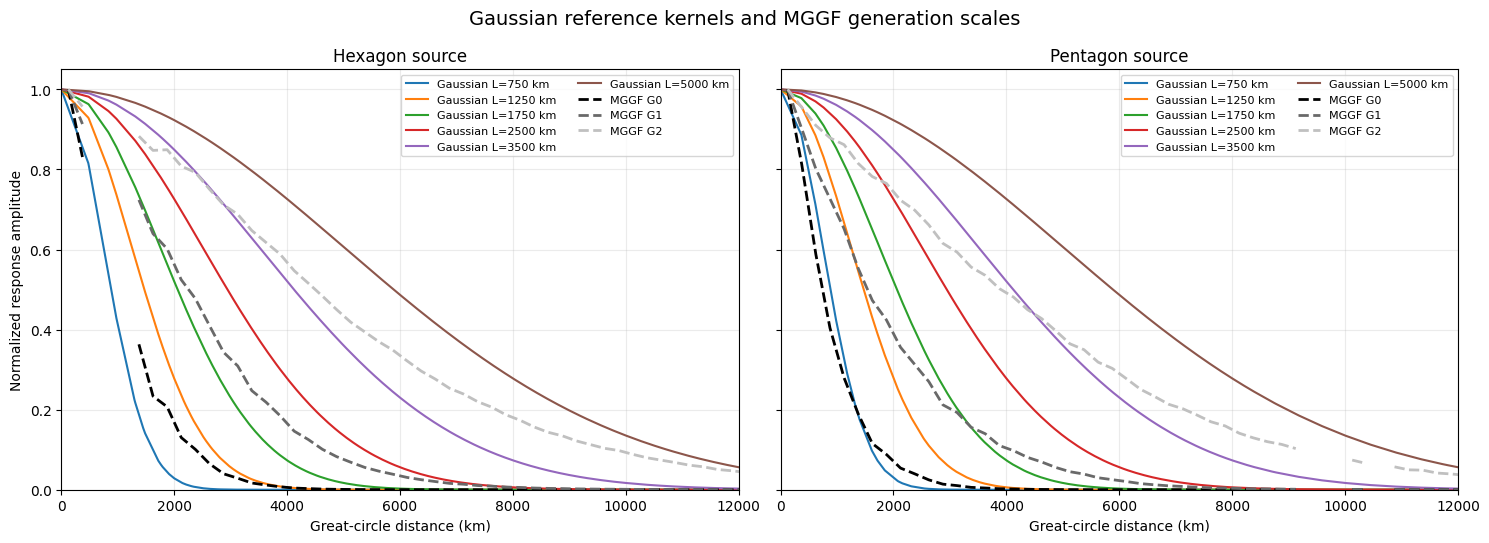


EFFECTIVE-RADIUS MIXTURE IDENTITY

Hexagon:
Predicted radius : 4237.53540781 km
Measured radius  : 4237.53540781 km
Difference       : 3.823516e-09 km
Hexagon: effective-radius mixture identity    error = 3.823516e-09   tolerance = 1.0e-06   [PASS]

Pentagon:
Predicted radius : 4129.07574646 km
Measured radius  : 4129.07574646 km
Difference       : 6.366463e-12 km
Pentagon: effective-radius mixture identity   error = 6.366463e-12   tolerance = 1.0e-06   [PASS]

CELL 7A COMPLETED
Gaussian reference kernels and calibration targets are available.
No MGGF operators or generation weights have been modified.


In [ ]:
# =============================================================================
# CELL 7A — GAUSSIAN REFERENCE KERNELS AND CALIBRATION TARGETS
# =============================================================================
#
# PURPOSE
# -------
# 1. Construct unit-integral Gaussian-like reference kernels on the sphere.
# 2. Calculate their effective radii and mass-containment radii.
# 3. Compare them with the three MGGF generation responses.
# 4. Determine which reference widths fall within the achievable
#    effective-radius range of the three-generation convex combination.
# 5. Plot normalized radial profiles for visual comparison.
#
# IMPORTANT
# ---------
# This cell DOES NOT optimize weights or modify the MGGF.
#
# The Gaussian is a prescribed radial reference kernel. We are not
# claiming that every such kernel is a valid positive-semidefinite
# covariance function on the sphere.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("CELL 7A — GAUSSIAN REFERENCE KERNELS AND CALIBRATION TARGETS")
print("=" * 78)

vertices0 = grids["G0"]["vertices"]
area0 = grids["G0"]["area"]

n0 = len(area0)

# Gaussian length parameters in kilometers.
GAUSSIAN_LENGTHS_KM = np.array(
    [750.0, 1250.0, 1750.0, 2500.0, 3500.0, 5000.0]
)

# Use the previously examined hexagonal and pentagonal sources.
calibration_sources = {
    "Hexagon": int(impulse_results["Hexagon"]["source"]),
    "Pentagon": int(impulse_results["Pentagon"]["source"])
}

component_names = ["G0", "G1", "G2"]


# =============================================================================
# STEP 1 — Define normalized spherical Gaussian reference
# =============================================================================

def spherical_gaussian_reference(
    distances_m,
    areas,
    length_km
):
    """
    Construct a discrete, unit-area-integral Gaussian-like kernel:

        K_i = exp[-d_i^2 / (2 L^2)] / Z

    where:

        Z = sum_i area_i * exp[-d_i^2 / (2 L^2)]

    The distances are great-circle distances in meters.
    """

    length_m = float(length_km) * 1000.0

    if length_m <= 0.0:
        raise ValueError("Gaussian length must be positive.")

    unnormalized = np.exp(
        -0.5 * (distances_m / length_m)**2
    )

    normalization = np.sum(
        areas * unnormalized
    )

    if normalization <= 0.0:
        raise ValueError("Gaussian normalization failed.")

    return unnormalized / normalization


# =============================================================================
# STEP 2 — Calculate effective radius and containment radii
# =============================================================================

def kernel_spread_diagnostics(
    response,
    distances_m,
    areas
):
    """
    Compute area-weighted response mass and radial spread.
    """

    masses = areas * response

    total_mass = np.sum(masses)

    if total_mass <= 0.0:
        raise ValueError("Kernel has nonpositive mass.")

    effective_radius_km = (
        np.sqrt(
            np.sum(masses * distances_m**2) / total_mass
        ) / 1000.0
    )

    order = np.argsort(distances_m)

    sorted_distances = distances_m[order]
    sorted_masses = masses[order]

    cumulative = np.cumsum(sorted_masses) / total_mass

    containment = {}

    for fraction in [0.50, 0.90, 0.95]:

        index = np.searchsorted(
            cumulative,
            fraction,
            side="left"
        )

        index = min(
            index,
            len(sorted_distances) - 1
        )

        containment[fraction] = (
            sorted_distances[index] / 1000.0
        )

    return {
        "mass": total_mass,
        "effective_radius_km": effective_radius_km,
        "r50_km": containment[0.50],
        "r90_km": containment[0.90],
        "r95_km": containment[0.95]
    }


# =============================================================================
# STEP 3 — Construct reference kernels and compare radial scales
# =============================================================================

gaussian_calibration_targets = {}

for label, source in calibration_sources.items():

    print()
    print("=" * 78)
    print(f"{label.upper()} SOURCE — VERTEX {source}")
    print("=" * 78)

    # Great-circle distances from the source.
    cosine = np.clip(
        vertices0 @ vertices0[source],
        -1.0,
        1.0
    )

    distances_m = EARTH_RADIUS * np.arccos(cosine)
    distances_m[source] = 0.0

    # Existing MGGF generation responses.
    generation_responses = (
        impulse_results[label]["contributions"][:3]
    )

    generation_spreads = []

    for response in generation_responses:

        diagnostics = kernel_spread_diagnostics(
            response,
            distances_m,
            area0
        )

        generation_spreads.append(
            diagnostics["effective_radius_km"]
        )

    generation_spreads = np.asarray(
        generation_spreads
    )

    # For convex combinations of normalized, nonnegative kernels,
    # squared effective radius is a weighted average.
    #
    # Therefore the achievable effective radius is bounded by the
    # smallest and largest generation effective radii.

    minimum_radius = np.min(generation_spreads)
    maximum_radius = np.max(generation_spreads)

    print()
    print("MGGF generation effective radii")
    print("-" * 78)

    for name, radius in zip(
        component_names,
        generation_spreads
    ):
        print(f"{name:<12}: {radius:10.2f} km")

    print()
    print(
        f"Achievable effective-radius interval: "
        f"{minimum_radius:.2f} to {maximum_radius:.2f} km"
    )

    reference_kernels = {}
    reference_diagnostics = {}

    print()
    print("Gaussian reference diagnostics")
    print("-" * 78)

    print(
        f"{'L (km)':>10}"
        f"{'r_eff (km)':>14}"
        f"{'r50 (km)':>14}"
        f"{'r90 (km)':>14}"
        f"{'r95 (km)':>14}"
        f"{'In range':>12}"
    )

    for length_km in GAUSSIAN_LENGTHS_KM:

        reference = spherical_gaussian_reference(
            distances_m,
            area0,
            length_km
        )

        diagnostics = kernel_spread_diagnostics(
            reference,
            distances_m,
            area0
        )

        radius = diagnostics["effective_radius_km"]

        in_range = (
            minimum_radius <= radius <= maximum_radius
        )

        reference_kernels[float(length_km)] = reference
        reference_diagnostics[float(length_km)] = diagnostics

        print(
            f"{length_km:>10.0f}"
            f"{radius:>14.2f}"
            f"{diagnostics['r50_km']:>14.2f}"
            f"{diagnostics['r90_km']:>14.2f}"
            f"{diagnostics['r95_km']:>14.2f}"
            f"{'YES' if in_range else 'NO':>12}"
        )

        verify(
            f"{label}: Gaussian L={length_km:.0f} km mass",
            abs(diagnostics["mass"] - 1.0),
            1.0e-10
        )

    gaussian_calibration_targets[label] = {
        "source": source,
        "distances_m": distances_m,
        "generation_responses": generation_responses,
        "generation_effective_radii_km": generation_spreads,
        "reference_kernels": reference_kernels,
        "reference_diagnostics": reference_diagnostics,
        "achievable_radius_interval_km": (
            minimum_radius,
            maximum_radius
        )
    }


# =============================================================================
# STEP 4 — Plot Gaussian radial profiles and MGGF generation profiles
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    data = gaussian_calibration_targets[label]

    distances_km = data["distances_m"] / 1000.0

    # Sort by distance for smooth reference curves.
    order = np.argsort(distances_km)

    sorted_distances = distances_km[order]

    for length_km in GAUSSIAN_LENGTHS_KM:

        reference = data["reference_kernels"][
            float(length_km)
        ]

        normalized = reference / np.max(reference)

        ax.plot(
            sorted_distances,
            normalized[order],
            linewidth=1.5,
            label=f"Gaussian L={length_km:.0f} km"
        )

    # Overlay the normalized radial-bin means of the existing
    # MGGF generation responses, calculated in Cell 6D.
    for name, color in zip(
        ["G0", "G1", "G2"],
        ["black", "dimgray", "silver"]
    ):

        radial_data = radial_diagnostics[label][name]

        ax.plot(
            radial_centers,
            radial_data["normalized_profile"],
            linestyle="--",
            linewidth=2.0,
            color=color,
            label=f"MGGF {name}"
        )

    ax.set_title(f"{label} source")

    ax.set_xlabel("Great-circle distance (km)")
    ax.set_xlim(0, 12000)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)

    ax.legend(
        fontsize=8,
        ncol=2
    )

axes[0].set_ylabel(
    "Normalized response amplitude"
)

fig.suptitle(
    "Gaussian reference kernels and MGGF generation scales",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 5 — Verify effective-radius mixture identity
#
# With equal weights and unit-integral generation responses:
#
#     r_M^2 = sum_l w_l * r_l^2
#
# This provides an independent consistency check.
# =============================================================================

print()
print("=" * 78)
print("EFFECTIVE-RADIUS MIXTURE IDENTITY")
print("=" * 78)

for label in ["Hexagon", "Pentagon"]:

    radii = gaussian_calibration_targets[label][
        "generation_effective_radii_km"
    ]

    predicted_radius = np.sqrt(
        np.sum(MGGF.weights * radii**2)
    )

    measured_radius = radial_diagnostics[label][
        "Combined"
    ]["effective_radius_km"]

    difference = abs(
        predicted_radius - measured_radius
    )

    print()
    print(f"{label}:")
    print(f"Predicted radius : {predicted_radius:.8f} km")
    print(f"Measured radius  : {measured_radius:.8f} km")
    print(f"Difference       : {difference:.6e} km")

    verify(
        f"{label}: effective-radius mixture identity",
        difference,
        1.0e-6
    )


print()
print("=" * 78)
print("CELL 7A COMPLETED")
print("Gaussian reference kernels and calibration targets are available.")
print("No MGGF operators or generation weights have been modified.")
print("=" * 78)

### Cell 7B — Nonnegative Calibration of MGGF Generation Weights

CELL 7B — NONNEGATIVE CALIBRATION OF GENERATION WEIGHTS

HEXAGON SOURCE
   L km        w0        w1        w2    Fit L2 %   Equal L2 %   Radius err %
    750   1.00000   0.00000   0.00000      43.097       72.443         61.525
Hexagon L=750: weight sum                     error = 1.110223e-15   tolerance = 1.0e-09   [PASS]
Hexagon L=750: nonnegativity                  error = 0.000000e+00   tolerance = 1.0e-10   [PASS]
Hexagon L=750: fitted mass                    error = 6.661338e-16   tolerance = 1.0e-09   [PASS]
   1250   0.79624   0.20376   0.00000      13.336       44.718         22.073
Hexagon L=1250: weight sum                    error = 0.000000e+00   tolerance = 1.0e-09   [PASS]
Hexagon L=1250: nonnegativity                 error = 0.000000e+00   tolerance = 1.0e-10   [PASS]
Hexagon L=1250: fitted mass                   error = 2.222666e-13   tolerance = 1.0e-09   [PASS]
   1750   0.24637   0.75363   0.00000      16.337       27.201         23.607
Hexagon L=1750: weight sum  

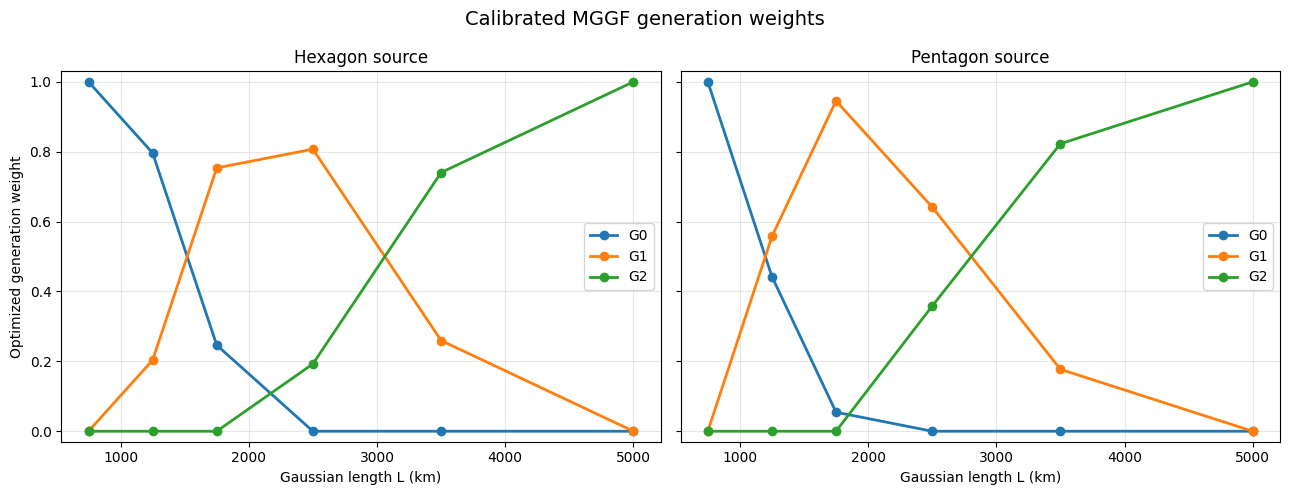

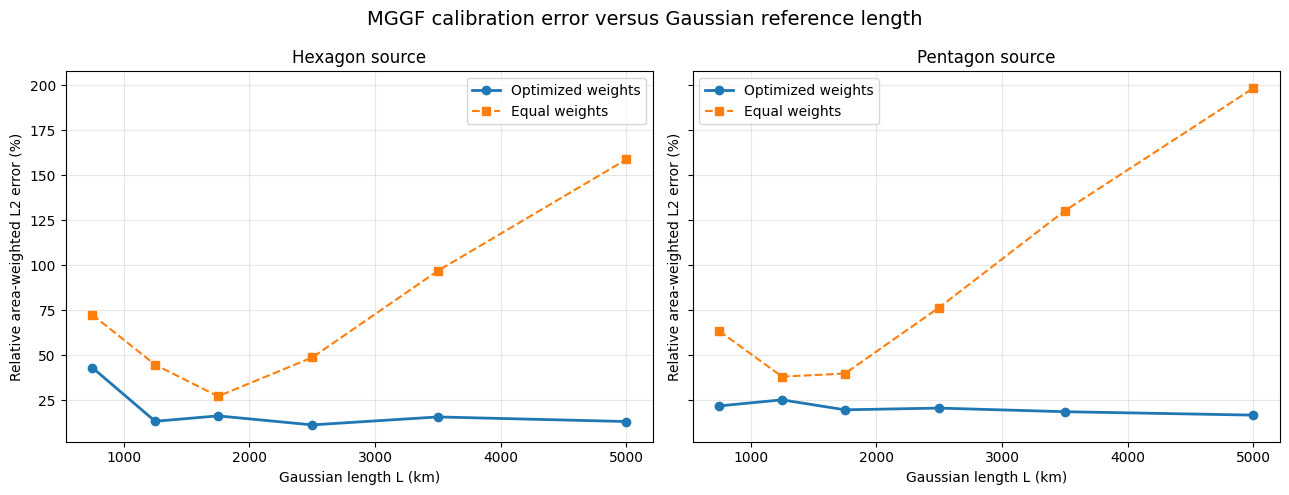


CELL 7B COMPLETED
Optimized weights and calibration errors are available.
The original MGGF operator and weights remain unchanged.


In [ ]:
# =============================================================================
# CELL 7B — NONNEGATIVE CALIBRATION OF MGGF GENERATION WEIGHTS
# =============================================================================
#
# PURPOSE
# -------
# For each Gaussian reference length and source topology:
#
#   1. Fit the three MGGF generation weights.
#   2. Require nonnegative weights summing to one.
#   3. Minimize area-weighted squared response error.
#   4. Report relative L2 error and effective-radius mismatch.
#   5. Compare fitted and equal-weight responses.
#
# Each calibration is independent.
# No global MGGF weights or operators are modified.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

print("=" * 78)
print("CELL 7B — NONNEGATIVE CALIBRATION OF GENERATION WEIGHTS")
print("=" * 78)


# =============================================================================
# STEP 1 — Define the constrained least-squares problem
# =============================================================================

def calibrate_generation_weights(
    generation_responses,
    reference,
    areas
):
    """
    Solve:

        min_w || sum_l w_l K_l - K_ref ||_A^2

    subject to:

        w_l >= 0
        sum_l w_l = 1

    The objective is divided by ||K_ref||_A^2.
    """

    K = np.column_stack(generation_responses)

    reference = np.asarray(reference, dtype=float)
    areas = np.asarray(areas, dtype=float)

    sqrt_area = np.sqrt(areas)

    # Scale the least-squares system to improve numerical conditioning.
    weighted_reference = sqrt_area * reference

    reference_norm = np.linalg.norm(weighted_reference)

    if reference_norm <= 0.0:
        raise ValueError("Reference norm must be positive.")

    A = (
        sqrt_area[:, None] * K
    ) / reference_norm

    b = weighted_reference / reference_norm

    # Precompute the small quadratic objective.
    H = A.T @ A
    g = A.T @ b

    def objective(w):
        return float(
            w @ H @ w - 2.0 * g @ w + b @ b
        )

    def gradient(w):
        return 2.0 * (H @ w - g)

    constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0,
        "jac": lambda w: np.ones(3)
    }]

    bounds = [(0.0, 1.0)] * 3

    # Several initial points make the small constrained problem robust.
    starting_points = [
        np.full(3, 1.0 / 3.0),
        np.array([1.0, 0.0, 0.0]),
        np.array([0.0, 1.0, 0.0]),
        np.array([0.0, 0.0, 1.0])
    ]

    solutions = []

    for initial in starting_points:

        result = minimize(
            objective,
            initial,
            jac=gradient,
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={
                "ftol": 1.0e-13,
                "maxiter": 1000
            }
        )

        if result.success:
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            "No successful constrained calibration."
        )

    best = min(
        solutions,
        key=lambda result: objective(result.x)
    )

    weights = best.x.copy()

    fitted = K @ weights

    residual = fitted - reference

    relative_l2 = (
        np.sqrt(np.sum(areas * residual**2))
        / np.sqrt(np.sum(areas * reference**2))
    )

    equal_weights = np.full(3, 1.0 / 3.0)
    equal_response = K @ equal_weights

    equal_residual = equal_response - reference

    equal_relative_l2 = (
        np.sqrt(np.sum(areas * equal_residual**2))
        / np.sqrt(np.sum(areas * reference**2))
    )

    return {
        "weights": weights,
        "fitted_response": fitted,
        "relative_l2": relative_l2,
        "equal_relative_l2": equal_relative_l2,
        "success": best.success,
        "iterations": best.nit
    }


# =============================================================================
# STEP 2 — Calibrate every Gaussian length for both source types
# =============================================================================

mggf_calibration_results = {}

for label in ["Hexagon", "Pentagon"]:

    data = gaussian_calibration_targets[label]

    generation_responses = data["generation_responses"]
    distances_m = data["distances_m"]

    mggf_calibration_results[label] = {}

    print()
    print("=" * 78)
    print(f"{label.upper()} SOURCE")
    print("=" * 78)

    print(
        f"{'L km':>7}"
        f"{'w0':>10}"
        f"{'w1':>10}"
        f"{'w2':>10}"
        f"{'Fit L2 %':>12}"
        f"{'Equal L2 %':>13}"
        f"{'Radius err %':>15}"
    )

    for length_km in GAUSSIAN_LENGTHS_KM:

        reference = data["reference_kernels"][
            float(length_km)
        ]

        result = calibrate_generation_weights(
            generation_responses,
            reference,
            area0
        )

        fitted_diagnostics = kernel_spread_diagnostics(
            result["fitted_response"],
            distances_m,
            area0
        )

        reference_diagnostics = data[
            "reference_diagnostics"
        ][float(length_km)]

        fitted_radius = fitted_diagnostics[
            "effective_radius_km"
        ]

        reference_radius = reference_diagnostics[
            "effective_radius_km"
        ]

        radius_error_percent = (
            100.0 * (fitted_radius - reference_radius)
            / reference_radius
        )

        result["fitted_diagnostics"] = fitted_diagnostics
        result["radius_error_percent"] = radius_error_percent

        mggf_calibration_results[label][
            float(length_km)
        ] = result

        w = result["weights"]

        print(
            f"{length_km:>7.0f}"
            f"{w[0]:>10.5f}"
            f"{w[1]:>10.5f}"
            f"{w[2]:>10.5f}"
            f"{100.0 * result['relative_l2']:>12.3f}"
            f"{100.0 * result['equal_relative_l2']:>13.3f}"
            f"{radius_error_percent:>15.3f}"
        )

        verify(
            f"{label} L={length_km:.0f}: weight sum",
            abs(np.sum(w) - 1.0),
            1.0e-9
        )

        verify(
            f"{label} L={length_km:.0f}: nonnegativity",
            max(0.0, -np.min(w)),
            1.0e-10
        )

        verify(
            f"{label} L={length_km:.0f}: fitted mass",
            abs(fitted_diagnostics["mass"] - 1.0),
            1.0e-9
        )


# =============================================================================
# STEP 3 — Plot optimal generation weights versus reference length
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    weights = np.array([
        mggf_calibration_results[label][
            float(L)
        ]["weights"]
        for L in GAUSSIAN_LENGTHS_KM
    ])

    for j, name in enumerate(component_names):

        ax.plot(
            GAUSSIAN_LENGTHS_KM,
            weights[:, j],
            marker="o",
            linewidth=2,
            label=name
        )

    ax.set_title(f"{label} source")
    ax.set_xlabel("Gaussian length L (km)")
    ax.set_ylim(-0.03, 1.03)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Optimized generation weight")

fig.suptitle(
    "Calibrated MGGF generation weights",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 4 — Plot relative response errors
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    fitted_errors = np.array([
        100.0 * mggf_calibration_results[label][
            float(L)
        ]["relative_l2"]
        for L in GAUSSIAN_LENGTHS_KM
    ])

    equal_errors = np.array([
        100.0 * mggf_calibration_results[label][
            float(L)
        ]["equal_relative_l2"]
        for L in GAUSSIAN_LENGTHS_KM
    ])

    ax.plot(
        GAUSSIAN_LENGTHS_KM,
        fitted_errors,
        marker="o",
        linewidth=2,
        label="Optimized weights"
    )

    ax.plot(
        GAUSSIAN_LENGTHS_KM,
        equal_errors,
        marker="s",
        linestyle="--",
        label="Equal weights"
    )

    ax.set_title(f"{label} source")
    ax.set_xlabel("Gaussian length L (km)")
    ax.set_ylabel("Relative area-weighted L2 error (%)")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "MGGF calibration error versus Gaussian reference length",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 5 — Preserve results
# =============================================================================

print()
print("=" * 78)
print("CELL 7B COMPLETED")
print("Optimized weights and calibration errors are available.")
print("The original MGGF operator and weights remain unchanged.")
print("=" * 78)

### Cell 7C — Profile Versus Moment-Constrained Calibration

CELL 7C — PROFILE VERSUS MOMENT-CONSTRAINED CALIBRATION

HEXAGON SOURCE

Gaussian L = 750 km
------------------------------------------------------------------------------
Method                 w0       w1       w2       L2 %    Radius %
Profile            1.0000   0.0000   0.0000     43.097      61.525
Hexagon L=750 Profile: weight sum             error = 1.110223e-15   tolerance = 1.0e-09   [PASS]
Hexagon L=750 Profile: nonnegative            error = 0.000000e+00   tolerance = 1.0e-09   [PASS]
Hexagon L=750 Profile: conservation           error = 6.661338e-16   tolerance = 1.0e-09   [PASS]
Penalized          1.0000   0.0000   0.0000     43.097      61.525
Hexagon L=750 Penalized: weight sum           error = 0.000000e+00   tolerance = 1.0e-09   [PASS]
Hexagon L=750 Penalized: nonnegative          error = 0.000000e+00   tolerance = 1.0e-09   [PASS]
Hexagon L=750 Penalized: conservation         error = 4.440892e-16   tolerance = 1.0e-09   [PASS]
Exact moment                           

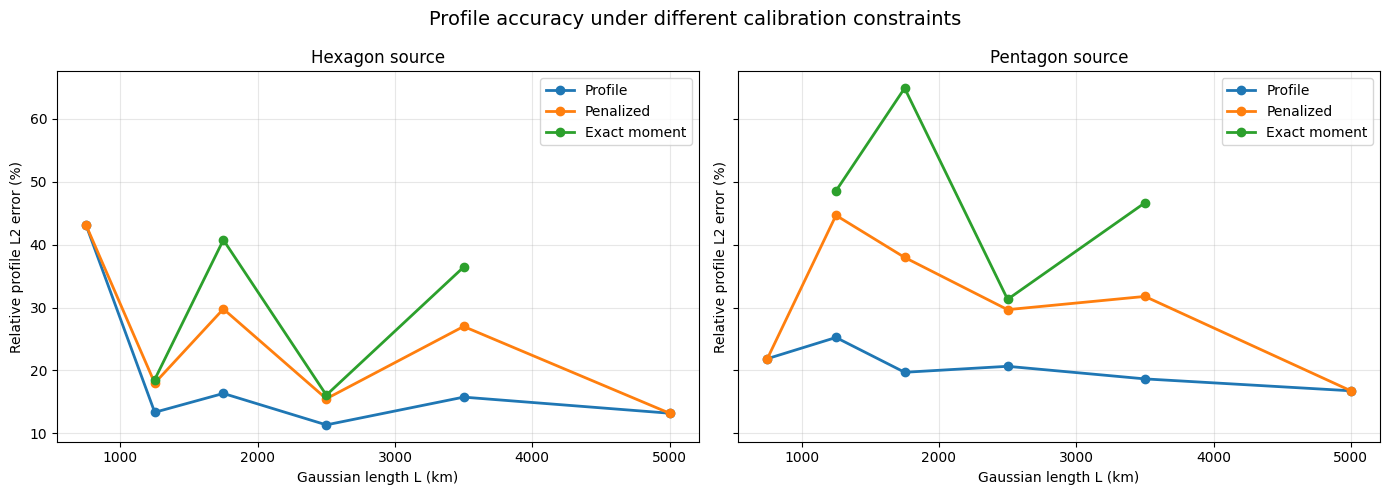

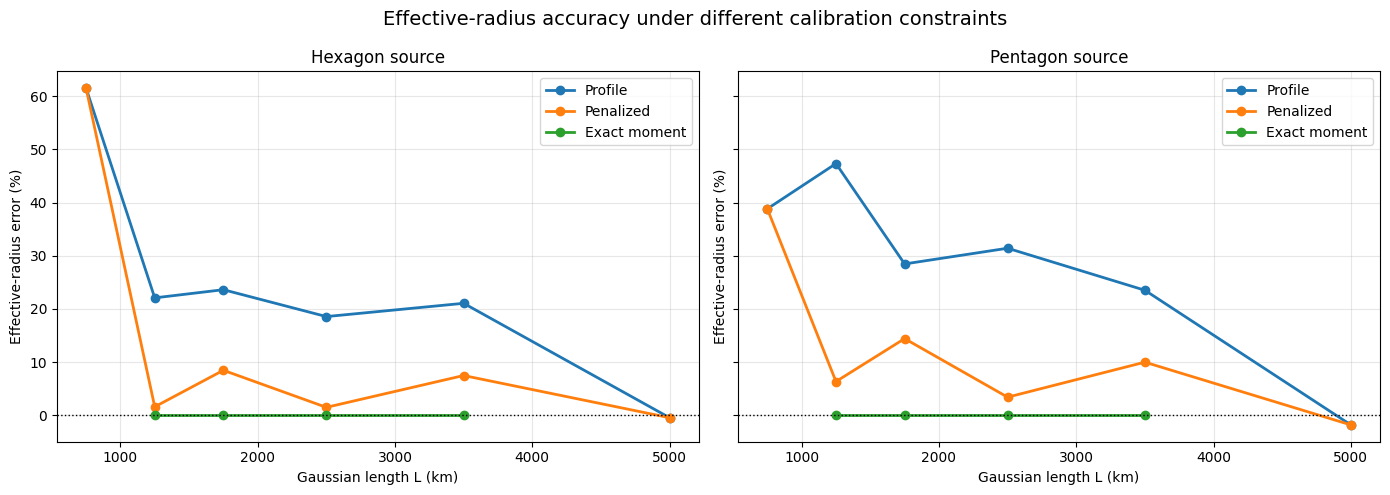


CELL 7C COMPLETED
Profile, penalized, and exact-moment calibration results saved.
The original MGGF operators and weights remain unchanged.


In [ ]:
# =============================================================================
# CELL 7C — PROFILE VERSUS MOMENT-CONSTRAINED CALIBRATION
# =============================================================================
#
# PURPOSE
# -------
# Compare three strategies for selecting generation weights:
#
# A. Profile-only least squares (Cell 7B)
#
# B. Profile least squares + squared-radius mismatch penalty
#
# C. Profile least squares with exact squared-radius matching
#
# All methods require:
#
#       w0 >= 0, w1 >= 0, w2 >= 0
#       w0 + w1 + w2 = 1
#
# IMPORTANT
# ---------
# The generation kernels are already computed.
#
# This cell changes neither the MGGF transfer operators nor the
# generation weights stored in the original MGGF object.
#
# We solve the three-weight problems directly in two dimensions.
# This avoids relying on an optimizer's convergence tolerance
# to enforce the exact moment constraint.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

print("=" * 78)
print("CELL 7C — PROFILE VERSUS MOMENT-CONSTRAINED CALIBRATION")
print("=" * 78)

MOMENT_PENALTY = 1.0

METHOD_NAMES = [
    "Profile",
    "Penalized",
    "Exact moment"
]

CALIBRATION_TOL = 1.0e-9


# =============================================================================
# STEP 1 — Construct the quadratic profile objective
# =============================================================================

def prepare_calibration_problem(
    generation_responses,
    reference,
    areas,
    distances_m
):
    """
    Build a dimensionless quadratic profile objective:

        E_profile(w) =
            || K w - K_ref ||_A^2 / || K_ref ||_A^2

    and the squared effective radii of all three generations.
    """

    K = np.column_stack(generation_responses)

    reference = np.asarray(reference, dtype=float)
    areas = np.asarray(areas, dtype=float)
    distances_m = np.asarray(distances_m, dtype=float)

    reference_norm2 = np.sum(
        areas * reference**2
    )

    if reference_norm2 <= 0.0:
        raise ValueError("Reference norm must be positive.")

    H = (
        K.T @ (areas[:, None] * K)
    ) / reference_norm2

    g = (
        K.T @ (areas * reference)
    ) / reference_norm2

    c = (
        np.sum(areas * reference**2)
        / reference_norm2
    )

    generation_masses = (
        K.T @ areas
    )

    generation_r2 = (
        K.T @ (areas * distances_m**2)
    ) / generation_masses

    reference_mass = np.sum(areas * reference)

    reference_r2 = (
        np.sum(areas * reference * distances_m**2)
        / reference_mass
    )

    # Express squared radii in km^2 for convenient reporting.
    generation_r2_km2 = generation_r2 / 1.0e6
    reference_r2_km2 = reference_r2 / 1.0e6

    return {
        "K": K,
        "reference": reference,
        "areas": areas,
        "H": H,
        "g": g,
        "c": c,
        "generation_r2_km2": generation_r2_km2,
        "reference_r2_km2": reference_r2_km2
    }


def profile_error_squared(w, problem):

    return max(
        0.0,
        float(
            w @ problem["H"] @ w
            - 2.0 * problem["g"] @ w
            + problem["c"]
        )
    )


def evaluate_calibration(w, problem):

    """
    Evaluate profile error, radius error, and response mass.

    The actual fitted effective radius is calculated from the
    fitted kernel rather than assuming perfect normalization.
    """

    response = problem["K"] @ w

    areas = problem["areas"]

    # Reconstruct distances^2 moments from the generation kernels.
    # This is exact up to the previously measured kernel-mass errors.
    masses = areas @ problem["K"]

    weighted_r2 = (
        np.dot(
            w * masses,
            problem["generation_r2_km2"]
        )
        / np.dot(w, masses)
    )

    reference_r2 = problem["reference_r2_km2"]

    fitted_radius = np.sqrt(weighted_r2)
    target_radius = np.sqrt(reference_r2)

    relative_profile_error = np.sqrt(
        np.sum(
            areas * (response - problem["reference"])**2
        )
        /
        np.sum(
            areas * problem["reference"]**2
        )
    )

    return {
        "weights": np.asarray(w).copy(),
        "response": response,
        "profile_error_percent": (
            100.0 * relative_profile_error
        ),
        "radius_km": fitted_radius,
        "target_radius_km": target_radius,
        "radius_error_percent": (
            100.0 * (fitted_radius - target_radius)
            / target_radius
        ),
        "mass": np.sum(areas * response)
    }


# =============================================================================
# STEP 2 — Penalized calibration
# =============================================================================

def solve_penalized_calibration(problem, penalty):

    """
    Minimize:

       E_profile(w)
       + penalty * [(sum(w*r_l^2) - r_ref^2)/r_ref^2]^2

    with w >= 0 and sum(w) = 1.
    """

    r2 = problem["generation_r2_km2"]
    target_r2 = problem["reference_r2_km2"]

    q = r2 / target_r2

    H = problem["H"]
    g = problem["g"]

    def objective(w):

        profile = (
            w @ H @ w
            - 2.0 * g @ w
            + problem["c"]
        )

        moment = (
            np.dot(w, q) - 1.0
        )**2

        return float(
            profile + penalty * moment
        )

    def gradient(w):

        return (
            2.0 * (H @ w - g)
            + 2.0 * penalty
            * (np.dot(w, q) - 1.0) * q
        )

    constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0,
        "jac": lambda w: np.ones(3)
    }]

    starting_points = [
        np.array([1.0/3.0] * 3),
        np.array([1.0, 0.0, 0.0]),
        np.array([0.0, 1.0, 0.0]),
        np.array([0.0, 0.0, 1.0])
    ]

    candidates = []

    for initial in starting_points:

        result = minimize(
            objective,
            initial,
            jac=gradient,
            method="SLSQP",
            bounds=[(0.0, 1.0)] * 3,
            constraints=constraints,
            options={
                "ftol": 1.0e-13,
                "maxiter": 1000
            }
        )

        if result.success:
            candidates.append(result)

    if not candidates:
        raise RuntimeError(
            "Penalized calibration failed."
        )

    best = min(
        candidates,
        key=lambda result: objective(result.x)
    )

    return best.x.copy()


# =============================================================================
# STEP 3 — Exact-moment calibration
#
# With three weights and two equality constraints:
#
#       sum(w) = 1
#       dot(w, r2) = target_r2
#
# the feasible weights form a line segment inside the simplex.
#
# We find its endpoints by intersecting the moment constraint
# with the three edges of the weight simplex.
#
# The quadratic profile objective is then minimized analytically
# along that segment.
# =============================================================================

def solve_exact_moment_calibration(problem):

    r2 = problem["generation_r2_km2"]
    target = problem["reference_r2_km2"]

    scale = max(
        1.0,
        float(np.max(np.abs(r2))),
        abs(float(target))
    )

    tolerance = 1.0e-12 * scale

    if (
        target < np.min(r2) - tolerance
        or target > np.max(r2) + tolerance
    ):
        return None

    candidates = []

    # Intersect the target moment with every simplex edge.
    for i, j in [(0, 1), (0, 2), (1, 2)]:

        denominator = r2[j] - r2[i]

        if abs(denominator) <= tolerance:

            if abs(target - r2[i]) <= tolerance:
                for vertex in [i, j]:
                    w = np.zeros(3)
                    w[vertex] = 1.0
                    candidates.append(w)

            continue

        fraction = (
            target - r2[i]
        ) / denominator

        if -1.0e-12 <= fraction <= 1.0 + 1.0e-12:

            fraction = np.clip(
                fraction,
                0.0,
                1.0
            )

            w = np.zeros(3)

            w[i] = 1.0 - fraction
            w[j] = fraction

            candidates.append(w)

    # Remove duplicate endpoints.
    unique = []

    for candidate in candidates:

        if not any(
            np.linalg.norm(candidate - old) < 1.0e-10
            for old in unique
        ):
            unique.append(candidate)

    if len(unique) == 0:
        return None

    if len(unique) == 1:
        return unique[0]

    # The intersection is a line segment.
    # Choose the most widely separated endpoints.
    maximum_distance = -1.0

    for i in range(len(unique)):
        for j in range(i + 1, len(unique)):

            distance = np.linalg.norm(
                unique[i] - unique[j]
            )

            if distance > maximum_distance:

                maximum_distance = distance
                endpoint_a = unique[i]
                endpoint_b = unique[j]

    direction = endpoint_b - endpoint_a

    H = problem["H"]
    g = problem["g"]

    denominator = direction @ H @ direction

    if denominator > 1.0e-15:

        t = (
            direction @ (g - H @ endpoint_a)
        ) / denominator

        t = np.clip(t, 0.0, 1.0)

    else:

        error_a = profile_error_squared(
            endpoint_a, problem
        )

        error_b = profile_error_squared(
            endpoint_b, problem
        )

        t = 0.0 if error_a <= error_b else 1.0

    return (
        endpoint_a + t * direction
    )


# =============================================================================
# STEP 4 — Run the three calibration strategies
# =============================================================================

moment_calibration_results = {}

for label in ["Hexagon", "Pentagon"]:

    data = gaussian_calibration_targets[label]

    moment_calibration_results[label] = {}

    print()
    print("=" * 78)
    print(f"{label.upper()} SOURCE")
    print("=" * 78)

    for length_km in GAUSSIAN_LENGTHS_KM:

        reference = data["reference_kernels"][
            float(length_km)
        ]

        problem = prepare_calibration_problem(
            data["generation_responses"],
            reference,
            area0,
            data["distances_m"]
        )

        # Method A: Reuse the profile-only fit from Cell 7B.
        w_profile = mggf_calibration_results[label][
            float(length_km)
        ]["weights"]

        # Method B: Penalize the squared-radius mismatch.
        w_penalized = solve_penalized_calibration(
            problem,
            MOMENT_PENALTY
        )

        # Method C: Match squared effective radius exactly.
        w_exact = solve_exact_moment_calibration(
            problem
        )

        solutions = {
            "Profile": evaluate_calibration(
                w_profile, problem
            ),
            "Penalized": evaluate_calibration(
                w_penalized, problem
            ),
            "Exact moment": (
                evaluate_calibration(w_exact, problem)
                if w_exact is not None
                else None
            )
        }

        moment_calibration_results[label][
            float(length_km)
        ] = solutions

        print()
        print(f"Gaussian L = {length_km:.0f} km")
        print("-" * 78)

        print(
            f"{'Method':<16}"
            f"{'w0':>9}"
            f"{'w1':>9}"
            f"{'w2':>9}"
            f"{'L2 %':>11}"
            f"{'Radius %':>12}"
        )

        for method in METHOD_NAMES:

            result = solutions[method]

            if result is None:

                print(
                    f"{method:<16}"
                    f"{'INFEASIBLE':>50}"
                )

                continue

            w = result["weights"]

            print(
                f"{method:<16}"
                f"{w[0]:>9.4f}"
                f"{w[1]:>9.4f}"
                f"{w[2]:>9.4f}"
                f"{result['profile_error_percent']:>11.3f}"
                f"{result['radius_error_percent']:>12.3f}"
            )

            verify(
                f"{label} L={length_km:.0f} "
                f"{method}: weight sum",
                abs(np.sum(w) - 1.0),
                CALIBRATION_TOL
            )

            verify(
                f"{label} L={length_km:.0f} "
                f"{method}: nonnegative",
                max(0.0, -np.min(w)),
                CALIBRATION_TOL
            )

            verify(
                f"{label} L={length_km:.0f} "
                f"{method}: conservation",
                abs(result["mass"] - 1.0),
                CALIBRATION_TOL
            )

            if method == "Exact moment":

                verify(
                    f"{label} L={length_km:.0f} "
                    f"exact radius",
                    abs(
                        result["radius_error_percent"]
                    ),
                    1.0e-7
                )


# =============================================================================
# STEP 5 — Plot relative profile errors for all methods
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    for method in METHOD_NAMES:

        errors = []

        for L in GAUSSIAN_LENGTHS_KM:

            result = moment_calibration_results[label][
                float(L)
            ][method]

            errors.append(
                np.nan if result is None
                else result["profile_error_percent"]
            )

        ax.plot(
            GAUSSIAN_LENGTHS_KM,
            errors,
            marker="o",
            linewidth=2,
            label=method
        )

    ax.set_title(f"{label} source")
    ax.set_xlabel("Gaussian length L (km)")
    ax.set_ylabel("Relative profile L2 error (%)")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Profile accuracy under different calibration constraints",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 6 — Plot effective-radius errors
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, label in zip(
    axes,
    ["Hexagon", "Pentagon"]
):

    for method in METHOD_NAMES:

        errors = []

        for L in GAUSSIAN_LENGTHS_KM:

            result = moment_calibration_results[label][
                float(L)
            ][method]

            errors.append(
                np.nan if result is None
                else result["radius_error_percent"]
            )

        ax.plot(
            GAUSSIAN_LENGTHS_KM,
            errors,
            marker="o",
            linewidth=2,
            label=method
        )

    ax.axhline(
        0.0,
        color="black",
        linewidth=1,
        linestyle=":"
    )

    ax.set_title(f"{label} source")
    ax.set_xlabel("Gaussian length L (km)")
    ax.set_ylabel("Effective-radius error (%)")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Effective-radius accuracy under different calibration constraints",
    fontsize=14
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 7 — Preserve results
# =============================================================================

print()
print("=" * 78)
print("CELL 7C COMPLETED")
print("Profile, penalized, and exact-moment calibration results saved.")
print("The original MGGF operators and weights remain unchanged.")
print("=" * 78)

### Cell 7D — Global Calibration of Generation Weights

CELL 7D — GLOBAL CALIBRATION OF GENERATION WEIGHTS
Optimized transfer operators loaded successfully.

Source selection
------------------------------------------------------------------------
Hexagon variable  : hex_sources
Pentagon variable : pent_sources
Hexagon sources   : 60
Pentagon sources  : 12

Computing generation impulse responses ...
Response construction time: 0.579 s

GLOBAL CALIBRATION RESULTS

Gaussian L = 750 km
------------------------------------------------------------------------
Method            w0      w1      w2    Mean L2%   Mean |r%|
Profile       1.0000  0.0000  0.0000      37.150      54.141
Penalized     1.0000  0.0000  0.0000      37.150      54.141

Gaussian L = 1250 km
------------------------------------------------------------------------
Method            w0      w1      w2    Mean L2%   Mean |r%|
Profile       0.6593  0.3407  0.0000      19.922      33.705
Penalized     0.9283  0.0717  0.0000      26.019       5.175

Gaussian L = 1750 km
------------

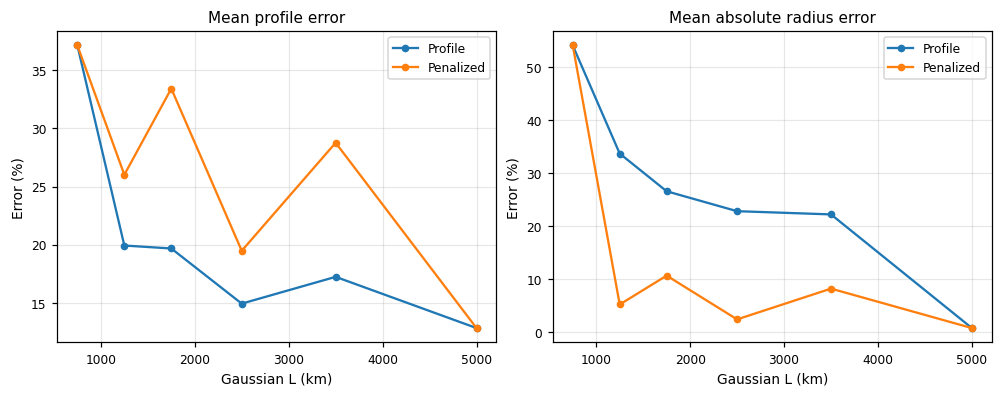

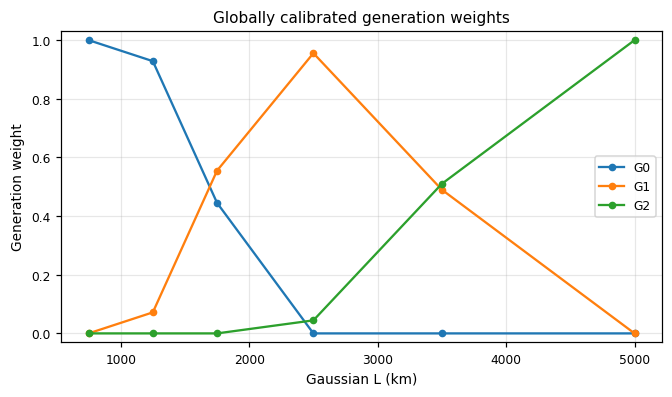


CELL 7D COMPLETED
Globally calibrated weights saved for all Gaussian lengths.
Original MGGF operators remain unchanged.


In [ ]:
# =============================================================================
# CELL 7D — GLOBAL CALIBRATION OF GENERATION WEIGHTS
# =============================================================================
#
# Fit ONE common weight vector for all selected impulse sources.
#
# Methods:
#   A. Profile-only calibration
#   B. Profile + effective-radius penalty
#
# Source set:
#   60 hexagons + 12 pentagons (from Cell 6E)
#
# All weights:
#   w >= 0, sum(w) = 1
#
# No existing MGGF operator is modified.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import time

print("=" * 72)
print("CELL 7D — GLOBAL CALIBRATION OF GENERATION WEIGHTS")
print("=" * 72)

GLOBAL_PENALTY = 1.0
GLOBAL_LENGTHS_KM = np.asarray(GAUSSIAN_LENGTHS_KM, dtype=float)

area0 = np.asarray(grids["G0"]["area"], dtype=float)
xyz0 = np.asarray(grids["G0"]["vertices"], dtype=float)

n0 = len(area0)

# Optimized, area-compatible transfer operators from Cells 5H–5I

P01 = optimized_prolongation["P01"]
R10 = optimized_restriction["R10"]

P12 = optimized_prolongation["P12"]
R21 = optimized_restriction["R21"]

# Confirm matrix dimensions.
assert P01.shape == (2562, 642)
assert R10.shape == (642, 2562)
assert P12.shape == (642, 162)
assert R21.shape == (162, 642)

print("Optimized transfer operators loaded successfully.")

B0 = grids["G0"]["GGF"]
B1 = grids["G1"]["GGF"]
B2 = grids["G2"]["GGF"]


# =============================================================================
# STEP 1 — Recover the source set from Cell 6E
# =============================================================================

# This avoids changing the original source selection.
# We expect Cell 6E to have retained the chosen source indices.
#
# If the names differ in the existing notebook, this section will
# identify the issue rather than silently choosing different sources.

candidate_hex_names = [
    "selected_hex_sources",
    "hex_sources",
    "hexagon_sources"
]

candidate_pent_names = [
    "selected_pent_sources",
    "pent_sources",
    "pentagon_sources"
]

def find_existing_source_array(candidates):

    for name in candidates:
        if name in globals():
            values = np.asarray(globals()[name], dtype=int)
            if values.ndim == 1 and len(values) > 0:
                return values, name

    return None, None


hex_sources, hex_name = find_existing_source_array(
    candidate_hex_names
)

pent_sources, pent_name = find_existing_source_array(
    candidate_pent_names
)

if hex_sources is None or pent_sources is None:

    print()
    print("Source arrays from Cell 6E were not found.")
    print("Available source-related variables:")

    for name in sorted(globals()):
        if "source" in name.lower():
            print("  ", name)

    raise RuntimeError(
        "Please identify the source arrays from Cell 6E."
    )

print()
print("Source selection")
print("-" * 72)
print(f"Hexagon variable  : {hex_name}")
print(f"Pentagon variable : {pent_name}")
print(f"Hexagon sources   : {len(hex_sources)}")
print(f"Pentagon sources  : {len(pent_sources)}")

assert len(hex_sources) == 60
assert len(pent_sources) == 12

source_ids = np.concatenate([
    hex_sources,
    pent_sources
])

source_classes = (
    ["Hexagon"] * len(hex_sources)
    + ["Pentagon"] * len(pent_sources)
)

assert len(np.unique(source_ids)) == len(source_ids)


# =============================================================================
# STEP 2 — Compute generation impulse responses for all sources
# =============================================================================

def generation_impulse_responses(source):

    impulse = np.zeros(n0)
    impulse[source] = 1.0 / area0[source]

    k0 = B0.apply(impulse)

    k1 = P01 @ B1.apply(
        R10 @ impulse
    )

    k2 = P01 @ P12 @ B2.apply(
        R21 @ R10 @ impulse
    )

    return np.column_stack([k0, k1, k2])


print()
print("Computing generation impulse responses ...")

t0 = time.perf_counter()

source_data = []

for source, source_class in zip(
    source_ids,
    source_classes
):

    K = generation_impulse_responses(
        int(source)
    )

    dot = np.clip(
        xyz0 @ xyz0[source],
        -1.0,
        1.0
    )

    distance_km = (
        EARTH_RADIUS / 1000.0
    ) * np.arccos(dot)

    generation_mass = area0 @ K

    generation_r2 = (
        (area0 * distance_km**2) @ K
    ) / generation_mass

    source_data.append({
        "source": int(source),
        "class": source_class,
        "K": K,
        "distance_km": distance_km,
        "generation_r2": generation_r2
    })

print(
    f"Response construction time: "
    f"{time.perf_counter() - t0:.3f} s"
)


# =============================================================================
# STEP 3 — Construct per-source Gaussian calibration problems
# =============================================================================

def make_source_problem(data, length_km):

    distance = data["distance_km"]

    # Same Gaussian convention used in Cell 7A.
    reference = np.exp(
        -0.5 * (distance / length_km)**2
    )

    reference /= np.dot(
        area0,
        reference
    )

    K = data["K"]

    reference_norm2 = np.dot(
        area0,
        reference**2
    )

    H = (
        K.T @ (area0[:, None] * K)
    ) / reference_norm2

    g = (
        K.T @ (area0 * reference)
    ) / reference_norm2

    reference_r2 = np.dot(
        area0 * reference,
        distance**2
    )

    return {
        "H": H,
        "g": g,
        "reference": reference,
        "reference_r2": reference_r2,
        "generation_r2": data["generation_r2"]
    }


# =============================================================================
# STEP 4 — Optimize common weights
# =============================================================================

def optimize_global_weights(problems, penalty):

    H = np.mean(
        [p["H"] for p in problems],
        axis=0
    )

    g = np.mean(
        [p["g"] for p in problems],
        axis=0
    )

    # Relative squared-radius mismatch:
    #
    #    (sum_l w_l r_l^2 / r_ref^2 - 1)^2
    #
    q = np.array([
        p["generation_r2"] / p["reference_r2"]
        for p in problems
    ])

    def objective(w):

        profile = (
            w @ H @ w - 2.0 * g @ w
        )

        moment = np.mean(
            (q @ w - 1.0)**2
        )

        return float(
            profile + penalty * moment
        )

    def gradient(w):

        grad_profile = (
            2.0 * (H @ w - g)
        )

        residual = q @ w - 1.0

        grad_moment = (
            2.0 / len(problems)
        ) * (q.T @ residual)

        return (
            grad_profile
            + penalty * grad_moment
        )

    constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0,
        "jac": lambda w: np.ones(3)
    }]

    initial_points = [
        np.full(3, 1.0 / 3.0),
        np.array([1.0, 0.0, 0.0]),
        np.array([0.0, 1.0, 0.0]),
        np.array([0.0, 0.0, 1.0])
    ]

    solutions = []

    for initial in initial_points:

        result = minimize(
            objective,
            initial,
            method="SLSQP",
            jac=gradient,
            bounds=[(0.0, 1.0)] * 3,
            constraints=constraints,
            options={
                "ftol": 1.0e-13,
                "maxiter": 1000
            }
        )

        if result.success:
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            "Global calibration optimization failed."
        )

    best = min(
        solutions,
        key=lambda result: objective(result.x)
    )

    return best.x


# =============================================================================
# STEP 5 — Evaluate source-wise errors
# =============================================================================

def evaluate_global_weights(w, data, problem):

    fitted = data["K"] @ w
    reference = problem["reference"]

    profile_error = 100.0 * np.sqrt(
        np.dot(
            area0,
            (fitted - reference)**2
        )
        /
        np.dot(
            area0,
            reference**2
        )
    )

    fitted_mass = np.dot(
        area0,
        fitted
    )

    fitted_r2 = np.dot(
        area0 * data["distance_km"]**2,
        fitted
    ) / fitted_mass

    radius_error = 100.0 * (
        np.sqrt(fitted_r2)
        / np.sqrt(problem["reference_r2"])
        - 1.0
    )

    return profile_error, radius_error, fitted_mass


global_calibration_results = {}

print()
print("=" * 72)
print("GLOBAL CALIBRATION RESULTS")
print("=" * 72)

for L in GLOBAL_LENGTHS_KM:

    problems = [
        make_source_problem(data, L)
        for data in source_data
    ]

    global_calibration_results[float(L)] = {}

    for method, penalty in [
        ("Profile", 0.0),
        ("Penalized", GLOBAL_PENALTY)
    ]:

        w = optimize_global_weights(
            problems,
            penalty
        )

        evaluations = [
            evaluate_global_weights(
                w, data, problem
            )
            for data, problem in zip(
                source_data,
                problems
            )
        ]

        evaluations = np.asarray(
            evaluations
        )

        global_calibration_results[float(L)][
            method
        ] = {
            "weights": w,
            "evaluations": evaluations
        }

        assert np.min(w) >= -1.0e-10
        assert abs(np.sum(w) - 1.0) < 1.0e-10

        assert np.max(
            np.abs(evaluations[:, 2] - 1.0)
        ) < 1.0e-9

    print()
    print(f"Gaussian L = {L:.0f} km")
    print("-" * 72)

    print(
        f"{'Method':<12}"
        f"{'w0':>8}{'w1':>8}{'w2':>8}"
        f"{'Mean L2%':>12}"
        f"{'Mean |r%|':>12}"
    )

    for method in ["Profile", "Penalized"]:

        result = global_calibration_results[
            float(L)
        ][method]

        w = result["weights"]
        e = result["evaluations"]

        print(
            f"{method:<12}"
            f"{w[0]:8.4f}"
            f"{w[1]:8.4f}"
            f"{w[2]:8.4f}"
            f"{np.mean(e[:, 0]):12.3f}"
            f"{np.mean(np.abs(e[:, 1])):12.3f}"
        )


# =============================================================================
# STEP 6 — Compact figures
# =============================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(9, 3.5),
    dpi=110,
    constrained_layout=True
)

for ax, metric, title in [
    (axes[0], 0, "Mean profile error"),
    (axes[1], 1, "Mean absolute radius error")
]:

    for method in ["Profile", "Penalized"]:

        values = []

        for L in GLOBAL_LENGTHS_KM:

            e = global_calibration_results[
                float(L)
            ][method]["evaluations"]

            if metric == 0:
                values.append(
                    np.mean(e[:, 0])
                )
            else:
                values.append(
                    np.mean(np.abs(e[:, 1]))
                )

        ax.plot(
            GLOBAL_LENGTHS_KM,
            values,
            marker="o",
            markersize=4,
            linewidth=1.5,
            label=method
        )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Gaussian L (km)", fontsize=9)
    ax.set_ylabel("Error (%)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.show()


fig, ax = plt.subplots(
    figsize=(6, 3.5),
    dpi=110,
    constrained_layout=True
)

for generation in range(3):

    values = [
        global_calibration_results[
            float(L)
        ]["Penalized"]["weights"][generation]
        for L in GLOBAL_LENGTHS_KM
    ]

    ax.plot(
        GLOBAL_LENGTHS_KM,
        values,
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=f"G{generation}"
    )

ax.set_title(
    "Globally calibrated generation weights",
    fontsize=10
)

ax.set_xlabel(
    "Gaussian L (km)",
    fontsize=9
)

ax.set_ylabel(
    "Generation weight",
    fontsize=9
)

ax.set_ylim(-0.03, 1.03)
ax.tick_params(labelsize=8)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

plt.show()


# =============================================================================
# STEP 7 — Save diagnostics
# =============================================================================

print()
print("=" * 72)
print("CELL 7D COMPLETED")
print("Globally calibrated weights saved for all Gaussian lengths.")
print("Original MGGF operators remain unchanged.")
print("=" * 72)

### Cell 7E — Sensitivity of Global Calibration to the Moment Penalty

CELL 7E — GLOBAL MOMENT-PENALTY SENSITIVITY
Number of sources       : 72
Gaussian lengths (km)   : [ 750. 1250. 1750. 2500. 3500. 5000.]
Moment penalties        : [ 0.    0.01  0.03  0.1   0.3   1.    3.   10.  ]
Calibration experiments : 48

Calibration time: 0.774 seconds

GLOBAL CALIBRATION — PENALTY SENSITIVITY

Gaussian correlation length: 750 km
------------------------------------------------------------------------
   lambda       w0       w1       w2     L2 (%)    |r| (%)
     0.00   1.0000   0.0000   0.0000     37.150     54.141
     0.01   1.0000   0.0000   0.0000     37.150     54.141
     0.03   1.0000   0.0000   0.0000     37.150     54.141
     0.10   1.0000   0.0000   0.0000     37.150     54.141
     0.30   1.0000   0.0000   0.0000     37.150     54.141
     1.00   1.0000   0.0000   0.0000     37.150     54.141
     3.00   1.0000   0.0000   0.0000     37.150     54.141
    10.00   1.0000   0.0000   0.0000     37.150     54.141

Gaussian correlation length: 1250 km
----

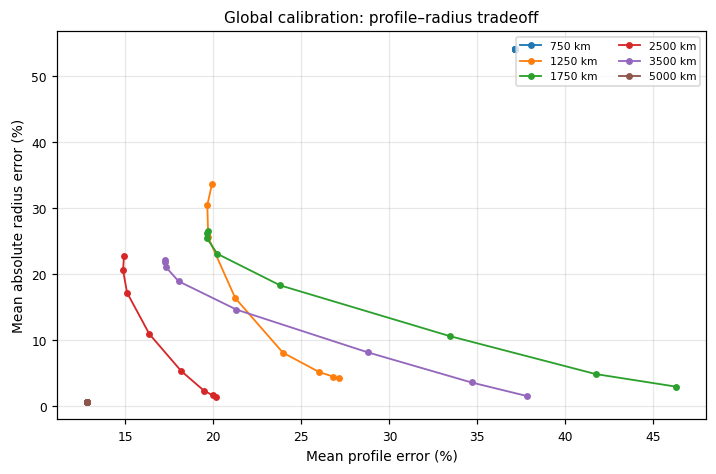

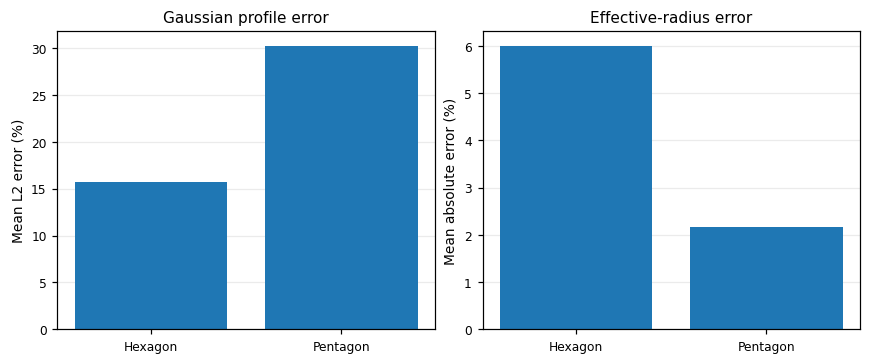


DIAGNOSTIC COMPARISON — L = 2500 km
lambda= 0.0  weights=(0.0000, 0.7637, 0.2363)  L2=14.920%  |radius|=22.812%
lambda= 0.1  weights=(0.0000, 0.8770, 0.1230)  L2=16.362%  |radius|=10.950%
lambda= 0.3  weights=(0.0000, 0.9263, 0.0737)  L2=18.164%  |radius|=5.367%
lambda= 1.0  weights=(0.0000, 0.9555, 0.0445)  L2=19.470%  |radius|=2.357%
lambda= 3.0  weights=(0.0000, 0.9659, 0.0341)  L2=19.968%  |radius|=1.658%

CELL 7E COMPLETED
Penalty sensitivity results saved in:
  penalty_sensitivity_results
Original graph filters and transfer operators unchanged.


In [ ]:
# =============================================================================
# CELL 7E — SENSITIVITY OF GLOBAL CALIBRATION TO THE MOMENT PENALTY
# =============================================================================
#
# Purpose
# -------
# Investigate the tradeoff between:
#
#   (1) Gaussian profile accuracy
#   (2) Effective-radius accuracy
#
# using ONE globally shared generation-weight vector for each
# Gaussian correlation length and each penalty value.
#
# We reuse the 72 source responses computed in Cell 7D.
# No new GGF or MGGF filtering calculations are performed.
#
# The original MGGF operators are not modified.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import time

print("=" * 72)
print("CELL 7E — GLOBAL MOMENT-PENALTY SENSITIVITY")
print("=" * 72)

# -------------------------------------------------------------------------
# 1. Experimental parameters
# -------------------------------------------------------------------------

PENALTY_VALUES = np.array([
    0.0,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
    3.0,
    10.0
])

LENGTHS_KM = np.asarray(
    GLOBAL_LENGTHS_KM,
    dtype=float
)

N_SOURCES = len(source_data)

assert N_SOURCES == 72

print(f"Number of sources       : {N_SOURCES}")
print(f"Gaussian lengths (km)   : {LENGTHS_KM}")
print(f"Moment penalties        : {PENALTY_VALUES}")
print(f"Calibration experiments : {len(LENGTHS_KM) * len(PENALTY_VALUES)}")


# -------------------------------------------------------------------------
# 2. Repeat global calibration for each penalty
# -------------------------------------------------------------------------

penalty_sensitivity_results = {}

t_start = time.perf_counter()

for L in LENGTHS_KM:

    problems = [
        make_source_problem(data, L)
        for data in source_data
    ]

    penalty_sensitivity_results[float(L)] = {}

    for lam in PENALTY_VALUES:

        # The optimizer was defined and validated in Cell 7D.
        w = optimize_global_weights(
            problems,
            penalty=float(lam)
        )

        # Evaluate every source separately.
        evaluations = np.asarray([
            evaluate_global_weights(w, data, problem)
            for data, problem in zip(source_data, problems)
        ])

        profile_errors = evaluations[:, 0]
        radius_errors = evaluations[:, 1]
        masses = evaluations[:, 2]

        # Preserve mathematical admissibility.
        assert np.min(w) >= -1.0e-10
        assert abs(np.sum(w) - 1.0) < 1.0e-10

        # Each calibrated impulse response must retain unit mass.
        assert np.max(
            np.abs(masses - 1.0)
        ) < 1.0e-9

        penalty_sensitivity_results[
            float(L)
        ][float(lam)] = {
            "weights": w.copy(),
            "evaluations": evaluations.copy(),
            "mean_profile_error": float(
                np.mean(profile_errors)
            ),
            "mean_abs_radius_error": float(
                np.mean(np.abs(radius_errors))
            ),
            "max_abs_radius_error": float(
                np.max(np.abs(radius_errors))
            )
        }

elapsed = time.perf_counter() - t_start

print()
print(f"Calibration time: {elapsed:.3f} seconds")


# -------------------------------------------------------------------------
# 3. Numerical summary
# -------------------------------------------------------------------------

print()
print("=" * 72)
print("GLOBAL CALIBRATION — PENALTY SENSITIVITY")
print("=" * 72)

for L in LENGTHS_KM:

    print()
    print(f"Gaussian correlation length: {L:.0f} km")
    print("-" * 72)

    print(
        f"{'lambda':>9}"
        f"{'w0':>9}"
        f"{'w1':>9}"
        f"{'w2':>9}"
        f"{'L2 (%)':>11}"
        f"{'|r| (%)':>11}"
    )

    for lam in PENALTY_VALUES:

        result = penalty_sensitivity_results[
            float(L)
        ][float(lam)]

        w = result["weights"]

        print(
            f"{lam:9.2f}"
            f"{w[0]:9.4f}"
            f"{w[1]:9.4f}"
            f"{w[2]:9.4f}"
            f"{result['mean_profile_error']:11.3f}"
            f"{result['mean_abs_radius_error']:11.3f}"
        )


# -------------------------------------------------------------------------
# 4. Figure 1 — Profile/radius tradeoff
# -------------------------------------------------------------------------
#
# Each curve represents one Gaussian correlation length.
# Each point corresponds to a different penalty.
#
# Points near the lower-left corner have smaller errors in both
# metrics. However, different Gaussian lengths have different
# attainable accuracy, so curves should be interpreted separately.
#
# Compact figure for convenient screenshot capture.
# -------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.4, 4.2),
    dpi=110,
    constrained_layout=True
)

for L in LENGTHS_KM:

    profile = []
    radius = []

    for lam in PENALTY_VALUES:

        result = penalty_sensitivity_results[
            float(L)
        ][float(lam)]

        profile.append(
            result["mean_profile_error"]
        )

        radius.append(
            result["mean_abs_radius_error"]
        )

    ax.plot(
        profile,
        radius,
        marker="o",
        markersize=3.5,
        linewidth=1.2,
        label=f"{L:.0f} km"
    )

ax.set_title(
    "Global calibration: profile–radius tradeoff",
    fontsize=10
)

ax.set_xlabel(
    "Mean profile error (%)",
    fontsize=9
)

ax.set_ylabel(
    "Mean absolute radius error (%)",
    fontsize=9
)

ax.tick_params(labelsize=8)
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)

plt.show()


# -------------------------------------------------------------------------
# 5. Figure 2 — Hexagon/pentagon comparison
# -------------------------------------------------------------------------
#
# Examine a representative intermediate correlation length.
#
# For this figure, lambda = 0.3 is a diagnostic choice, not
# a final recommendation.
# -------------------------------------------------------------------------

L_DIAGNOSTIC = 2500.0
LAMBDA_DIAGNOSTIC = 0.3

result = penalty_sensitivity_results[
    L_DIAGNOSTIC
][LAMBDA_DIAGNOSTIC]

evaluations = result["evaluations"]

hex_mask = np.array([
    data["class"] == "Hexagon"
    for data in source_data
])

pent_mask = np.array([
    data["class"] == "Pentagon"
    for data in source_data
])

group_names = ["Hexagon", "Pentagon"]
group_masks = [hex_mask, pent_mask]

profile_means = [
    np.mean(evaluations[mask, 0])
    for mask in group_masks
]

radius_means = [
    np.mean(np.abs(evaluations[mask, 1]))
    for mask in group_masks
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.8, 3.2),
    dpi=110,
    constrained_layout=True
)

axes[0].bar(
    group_names,
    profile_means
)

axes[0].set_title(
    "Gaussian profile error",
    fontsize=10
)

axes[0].set_ylabel(
    "Mean L2 error (%)",
    fontsize=9
)

axes[1].bar(
    group_names,
    radius_means
)

axes[1].set_title(
    "Effective-radius error",
    fontsize=10
)

axes[1].set_ylabel(
    "Mean absolute error (%)",
    fontsize=9
)

for ax in axes:
    ax.tick_params(labelsize=8)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.show()


# -------------------------------------------------------------------------
# 6. Diagnostic: compare profile-only and penalized solutions
# -------------------------------------------------------------------------
#
# We report the changes for the representative 2500-km Gaussian.
# -------------------------------------------------------------------------

print()
print("=" * 72)
print("DIAGNOSTIC COMPARISON — L = 2500 km")
print("=" * 72)

for lam in [0.0, 0.1, 0.3, 1.0, 3.0]:

    result = penalty_sensitivity_results[
        2500.0
    ][lam]

    w = result["weights"]

    print(
        f"lambda={lam:4.1f}  "
        f"weights=({w[0]:.4f}, {w[1]:.4f}, {w[2]:.4f})  "
        f"L2={result['mean_profile_error']:.3f}%  "
        f"|radius|={result['mean_abs_radius_error']:.3f}%"
    )


# -------------------------------------------------------------------------
# 7. Completion
# -------------------------------------------------------------------------

print()
print("=" * 72)
print("CELL 7E COMPLETED")
print("Penalty sensitivity results saved in:")
print("  penalty_sensitivity_results")
print("Original graph filters and transfer operators unchanged.")
print("=" * 72)

### Cell 7F — Constrained Global Calibration of Generation Weights

CELL 7F — CONSTRAINED GLOBAL CALIBRATION

Calibration time: 0.333 seconds

CONSTRAINED CALIBRATION RESULTS

Gaussian L = 750 km
------------------------------------------------------------------------
 Tolerance       Status       w0       w1       w2     L2 (%)    Max |r|%
        5%   INFEASIBLE
       10%   INFEASIBLE
       15%   INFEASIBLE

Gaussian L = 1250 km
------------------------------------------------------------------------
 Tolerance       Status       w0       w1       w2     L2 (%)    Max |r|%
        5%   INFEASIBLE
       10%     FEASIBLE   0.9032   0.0968   0.0000     24.705      10.000
       15%     FEASIBLE   0.8625   0.1375   0.0000     22.828      15.000

Gaussian L = 1750 km
------------------------------------------------------------------------
 Tolerance       Status       w0       w1       w2     L2 (%)    Max |r|%
        5%     FEASIBLE   0.5682   0.4318   0.0000     45.001       5.000
       10%     FEASIBLE   0.4929   0.5071   0.0000     37.788      10

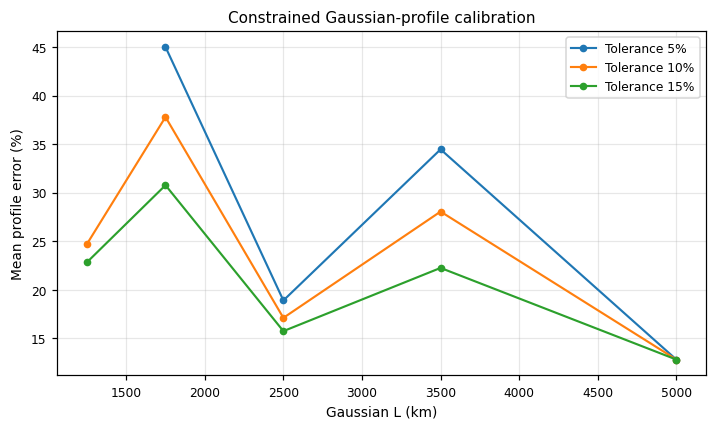

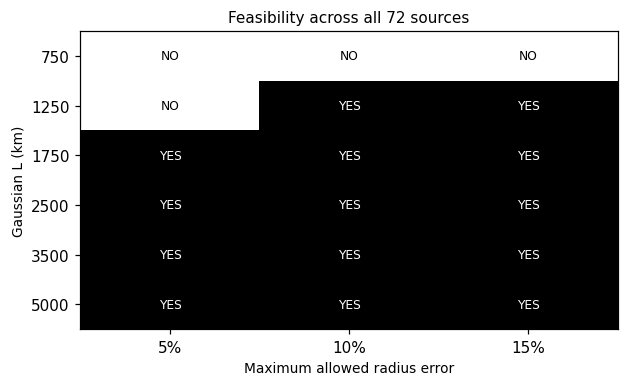


CELL 7F COMPLETED
Results saved in constrained_calibration_results.
No graph filters or transfer operators were modified.


In [ ]:
# =============================================================================
# CELL 7F — CONSTRAINED GLOBAL CALIBRATION
# =============================================================================
#
# Objective:
#   Minimize mean squared relative Gaussian profile error.
#
# Constraints:
#   1. w >= 0
#   2. sum(w) = 1
#   3. Every selected source must satisfy a specified effective-radius
#      tolerance.
#
# Radius tolerances:
#   5%, 10%, 15%
#
# The same weights are applied to all 72 source locations.
#
# This cell reuses Cell 7D response data and calibration functions.
# No new graph filtering calculations are required.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog
import time

print("=" * 72)
print("CELL 7F — CONSTRAINED GLOBAL CALIBRATION")
print("=" * 72)

RADIUS_TOLERANCES = np.array([0.05, 0.10, 0.15])
LENGTHS_7F = np.asarray(GLOBAL_LENGTHS_KM, dtype=float)

assert len(source_data) == 72


# =============================================================================
# 1. Construct the global quadratic objective
# =============================================================================

def build_global_problem(length_km):

    problems = [
        make_source_problem(data, length_km)
        for data in source_data
    ]

    H = np.mean(
        [p["H"] for p in problems],
        axis=0
    )

    g = np.mean(
        [p["g"] for p in problems],
        axis=0
    )

    # Each row contains the generation squared radii divided by
    # the corresponding reference squared radius.
    #
    # Thus Q @ w = (r_MGGF / r_Gaussian)^2 for every source.

    Q = np.asarray([
        p["generation_r2"] / p["reference_r2"]
        for p in problems
    ])

    return {
        "problems": problems,
        "H": H,
        "g": g,
        "Q": Q
    }


def profile_objective(w, problem):

    H = problem["H"]
    g = problem["g"]

    return float(
        w @ H @ w - 2.0 * g @ w
    )


def profile_gradient(w, problem):

    return 2.0 * (
        problem["H"] @ w - problem["g"]
    )


# =============================================================================
# 2. Feasibility test using linear programming
# =============================================================================
#
# For a tolerance eps:
#
#    (1-eps)^2 <= Q @ w <= (1+eps)^2
#
# These are linear constraints.
#
# A linear program determines whether any admissible weight vector
# satisfies all 72 source constraints simultaneously.
# =============================================================================

def radius_constraint_matrices(Q, eps):

    upper = (1.0 + eps)**2
    lower = (1.0 - eps)**2

    A_ub = np.vstack([
        Q,
        -Q
    ])

    b_ub = np.concatenate([
        np.full(len(Q), upper),
        np.full(len(Q), -lower)
    ])

    return A_ub, b_ub


def find_feasible_weights(problem, eps):

    A_ub, b_ub = radius_constraint_matrices(
        problem["Q"], eps
    )

    result = linprog(
        c=np.zeros(3),
        A_ub=A_ub,
        b_ub=b_ub,
        A_eq=np.ones((1, 3)),
        b_eq=np.array([1.0]),
        bounds=[(0.0, 1.0)] * 3,
        method="highs"
    )

    if not result.success:
        return None

    return result.x


# =============================================================================
# 3. Constrained profile optimization
# =============================================================================

def solve_constrained_global(problem, eps):

    feasible = find_feasible_weights(
        problem, eps
    )

    if feasible is None:
        return None

    Q = problem["Q"]

    lower = (1.0 - eps)**2
    upper = (1.0 + eps)**2

    constraints = [
        {
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1.0,
            "jac": lambda w: np.ones(3)
        },
        {
            "type": "ineq",
            "fun": lambda w: upper - Q @ w,
            "jac": lambda w: -Q
        },
        {
            "type": "ineq",
            "fun": lambda w: Q @ w - lower,
            "jac": lambda w: Q
        }
    ]

    result = minimize(
        lambda w: profile_objective(w, problem),
        feasible,
        method="SLSQP",
        jac=lambda w: profile_gradient(w, problem),
        bounds=[(0.0, 1.0)] * 3,
        constraints=constraints,
        options={
            "ftol": 1.0e-12,
            "maxiter": 1000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Constrained optimization failed: {result.message}"
        )

    w = result.x

    # Independently verify every constraint.
    q = Q @ w

    assert np.min(w) >= -1.0e-9
    assert abs(np.sum(w) - 1.0) < 1.0e-9

    assert np.min(q) >= lower - 1.0e-8
    assert np.max(q) <= upper + 1.0e-8

    return w


# =============================================================================
# 4. Execute calibration
# =============================================================================

constrained_calibration_results = {}

t_start = time.perf_counter()

for L in LENGTHS_7F:

    problem = build_global_problem(L)

    constrained_calibration_results[float(L)] = {}

    for eps in RADIUS_TOLERANCES:

        w = solve_constrained_global(
            problem, float(eps)
        )

        if w is None:

            constrained_calibration_results[
                float(L)
            ][float(eps)] = {
                "feasible": False
            }

            continue

        evaluations = np.asarray([
            evaluate_global_weights(
                w, data, source_problem
            )
            for data, source_problem in zip(
                source_data,
                problem["problems"]
            )
        ])

        profile_errors = evaluations[:, 0]
        radius_errors = evaluations[:, 1]
        masses = evaluations[:, 2]

        assert np.max(
            np.abs(masses - 1.0)
        ) < 1.0e-9

        assert np.max(
            np.abs(radius_errors)
        ) <= 100.0 * eps + 1.0e-6

        constrained_calibration_results[
            float(L)
        ][float(eps)] = {
            "feasible": True,
            "weights": w.copy(),
            "evaluations": evaluations.copy(),
            "mean_profile_error": float(
                np.mean(profile_errors)
            ),
            "rms_profile_error": float(
                np.sqrt(
                    np.mean(profile_errors**2)
                )
            ),
            "mean_abs_radius_error": float(
                np.mean(np.abs(radius_errors))
            ),
            "max_abs_radius_error": float(
                np.max(np.abs(radius_errors))
            )
        }

elapsed = time.perf_counter() - t_start


# =============================================================================
# 5. Print numerical results
# =============================================================================

print()
print(f"Calibration time: {elapsed:.3f} seconds")

print()
print("=" * 72)
print("CONSTRAINED CALIBRATION RESULTS")
print("=" * 72)

for L in LENGTHS_7F:

    print()
    print(f"Gaussian L = {L:.0f} km")
    print("-" * 72)

    print(
        f"{'Tolerance':>10}"
        f"{'Status':>13}"
        f"{'w0':>9}"
        f"{'w1':>9}"
        f"{'w2':>9}"
        f"{'L2 (%)':>11}"
        f"{'Max |r|%':>12}"
    )

    for eps in RADIUS_TOLERANCES:

        result = constrained_calibration_results[
            float(L)
        ][float(eps)]

        if not result["feasible"]:

            print(
                f"{100*eps:9.0f}%"
                f"{'INFEASIBLE':>13}"
            )

            continue

        w = result["weights"]

        print(
            f"{100*eps:9.0f}%"
            f"{'FEASIBLE':>13}"
            f"{w[0]:9.4f}"
            f"{w[1]:9.4f}"
            f"{w[2]:9.4f}"
            f"{result['mean_profile_error']:11.3f}"
            f"{result['max_abs_radius_error']:12.3f}"
        )


# =============================================================================
# 6. Compact figure — Profile error by radius tolerance
# =============================================================================

fig, ax = plt.subplots(
    figsize=(6.4, 3.8),
    dpi=110,
    constrained_layout=True
)

for eps in RADIUS_TOLERANCES:

    x = []
    y = []

    for L in LENGTHS_7F:

        result = constrained_calibration_results[
            float(L)
        ][float(eps)]

        if result["feasible"]:

            x.append(L)
            y.append(
                result["mean_profile_error"]
            )

    if x:
        ax.plot(
            x, y,
            marker="o",
            markersize=4,
            linewidth=1.4,
            label=f"Tolerance {100*eps:.0f}%"
        )

ax.set_title(
    "Constrained Gaussian-profile calibration",
    fontsize=10
)

ax.set_xlabel(
    "Gaussian L (km)",
    fontsize=9
)

ax.set_ylabel(
    "Mean profile error (%)",
    fontsize=9
)

ax.tick_params(labelsize=8)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

plt.show()


# =============================================================================
# 7. Compact figure — Feasibility map
# =============================================================================

feasibility = np.array([
    [
        int(
            constrained_calibration_results[
                float(L)
            ][float(eps)]["feasible"]
        )
        for eps in RADIUS_TOLERANCES
    ]
    for L in LENGTHS_7F
])

fig, ax = plt.subplots(
    figsize=(5.6, 3.4),
    dpi=110,
    constrained_layout=True
)

ax.imshow(
    feasibility,
    aspect="auto",
    vmin=0,
    vmax=1,
    cmap="Greys"
)

ax.set_xticks(
    np.arange(len(RADIUS_TOLERANCES))
)

ax.set_xticklabels([
    f"{100*eps:.0f}%"
    for eps in RADIUS_TOLERANCES
])

ax.set_yticks(
    np.arange(len(LENGTHS_7F))
)

ax.set_yticklabels([
    f"{L:.0f}"
    for L in LENGTHS_7F
])

ax.set_xlabel(
    "Maximum allowed radius error",
    fontsize=9
)

ax.set_ylabel(
    "Gaussian L (km)",
    fontsize=9
)

ax.set_title(
    "Feasibility across all 72 sources",
    fontsize=10
)

for i in range(len(LENGTHS_7F)):
    for j in range(len(RADIUS_TOLERANCES)):

        feasible = feasibility[i, j]

        ax.text(
            j, i,
            "YES" if feasible else "NO",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if feasible else "black"
        )

plt.show()


# =============================================================================
# 8. Completion
# =============================================================================

print()
print("=" * 72)
print("CELL 7F COMPLETED")
print("Results saved in constrained_calibration_results.")
print("No graph filters or transfer operators were modified.")
print("=" * 72)

### Cell 7G — Radial Profiles of Globally Calibrated MGGF Responses

CELL 7G — GAUSSIAN PROFILE DIAGNOSTICS


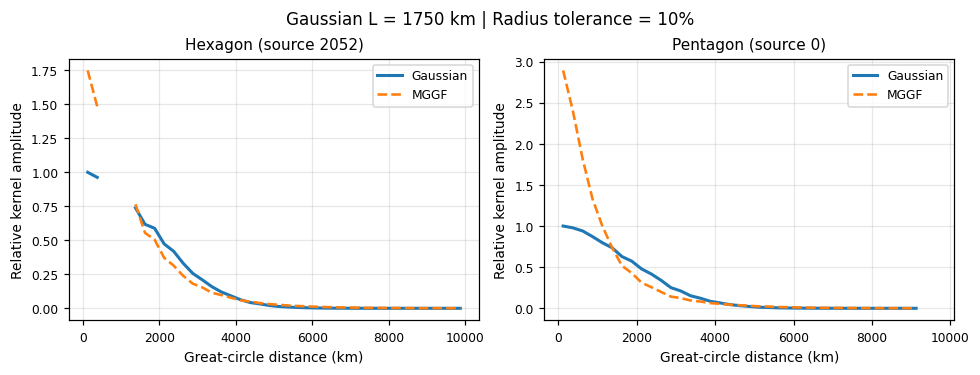

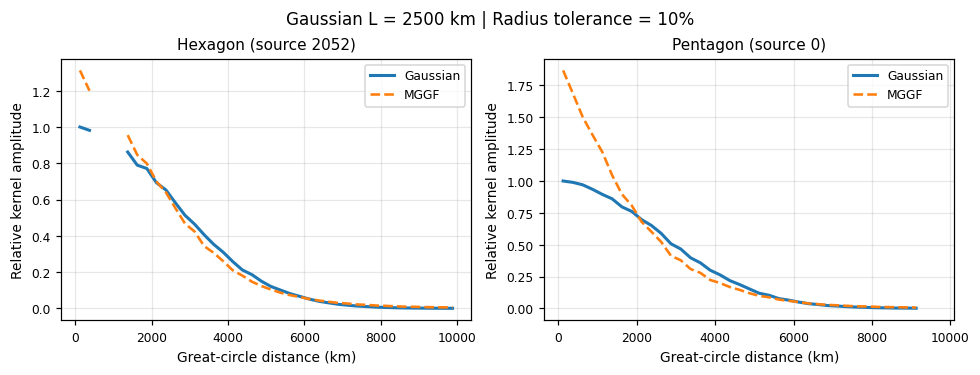

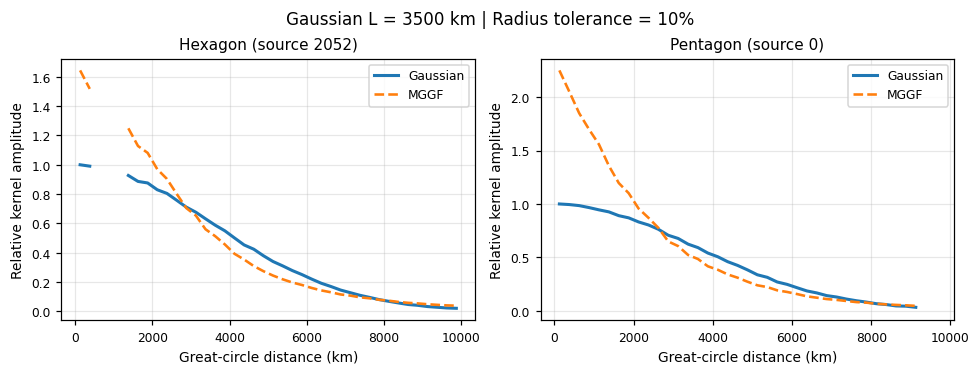


RADIAL PROFILE DIAGNOSTICS

Gaussian L = 1750 km
Weights: G0=0.4929, G1=0.5071, G2=0.0000
  Hexagon   L2= 29.093%  Radius error= +8.977%
  Pentagon  L2= 60.176%  Radius error= +2.583%

Gaussian L = 2500 km
Weights: G0=0.0000, G1=0.8994, G2=0.1006
  Hexagon   L2= 12.945%  Radius error= +8.764%
  Pentagon  L2= 28.767%  Radius error= +5.269%

Gaussian L = 3500 km
Weights: G0=0.0000, G1=0.4805, G2=0.5195
  Hexagon   L2= 25.637%  Radius error= +8.572%
  Pentagon  L2= 36.888%  Radius error= +6.510%

CELL 7G COMPLETED
Radial diagnostics saved in radial_profile_diagnostics.
Original MGGF operators unchanged.


In [ ]:
# =============================================================================
# CELL 7G — RADIAL PROFILES OF GLOBALLY CALIBRATED MGGF RESPONSES
# =============================================================================
#
# Purpose
# -------
# Compare:
#
#   1. Reference Gaussian response
#   2. Globally calibrated MGGF response
#
# for three Gaussian correlation lengths:
#
#   L = 1750, 2500, 3500 km
#
# We use the globally shared weights obtained in Cell 7F,
# with a maximum effective-radius error tolerance of 10%.
#
# For each length, examine:
#
#   - One representative hexagonal source
#   - One representative pentagonal source
#
# Each response is normalized to unit total mass.
#
# IMPORTANT:
#   The plots show area-weighted radial-bin averages.
#   Individual grid-cell responses are not altered.
#
# No graph filtering calculations are repeated.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 72)
print("CELL 7G — GAUSSIAN PROFILE DIAGNOSTICS")
print("=" * 72)


# =============================================================================
# 1. Parameters
# =============================================================================

DIAGNOSTIC_LENGTHS = [
    1750.0,
    2500.0,
    3500.0
]

RADIUS_TOLERANCE = 0.10

# Use the representative sources already employed in Cell 7A.
# These source indices were established in Cell 6B.

REPRESENTATIVE_SOURCES = {
    "Hexagon": 2052,
    "Pentagon": 0
}

# Radial bins in kilometers.
BIN_WIDTH_KM = 250.0

MAX_DISTANCE_KM = (
    np.pi * EARTH_RADIUS / 1000.0
)

bin_edges = np.arange(
    0.0,
    MAX_DISTANCE_KM + BIN_WIDTH_KM,
    BIN_WIDTH_KM
)

bin_centers = 0.5 * (
    bin_edges[:-1] + bin_edges[1:]
)


# =============================================================================
# 2. Locate the previously calculated source responses
# =============================================================================

def get_source_data(source_index):

    matches = [
        data
        for data in source_data
        if data["source"] == source_index
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Source {source_index} not found in Cell 7D source data."
        )

    return matches[0]


# =============================================================================
# 3. Area-weighted radial averages
# =============================================================================

def radial_bin_average(
    distances_km,
    response,
    areas,
    edges
):

    bin_index = np.digitize(
        distances_km,
        edges
    ) - 1

    n_bins = len(edges) - 1

    radial_mean = np.full(
        n_bins,
        np.nan
    )

    radial_mass = np.zeros(
        n_bins
    )

    for j in range(n_bins):

        mask = bin_index == j

        if not np.any(mask):
            continue

        area_sum = np.sum(
            areas[mask]
        )

        radial_mean[j] = (
            np.sum(
                areas[mask] * response[mask]
            )
            / area_sum
        )

        radial_mass[j] = np.sum(
            areas[mask] * response[mask]
        )

    return radial_mean, radial_mass


# =============================================================================
# 4. Normalize response amplitudes for plotting
# =============================================================================
#
# Each kernel has unit area integral, but its peak amplitude depends
# strongly on the correlation length.
#
# We divide both the reference and MGGF radial profiles by the
# maximum of the reference radial profile.
#
# This preserves the relative peak-amplitude difference between
# the MGGF and Gaussian response.
# =============================================================================

def normalized_profiles(
    distances_km,
    reference,
    fitted
):

    gaussian_radial, gaussian_mass = radial_bin_average(
        distances_km,
        reference,
        area0,
        bin_edges
    )

    fitted_radial, fitted_mass = radial_bin_average(
        distances_km,
        fitted,
        area0,
        bin_edges
    )

    peak_reference = np.nanmax(
        gaussian_radial
    )

    return {
        "gaussian": gaussian_radial / peak_reference,
        "fitted": fitted_radial / peak_reference,
        "gaussian_mass": gaussian_mass,
        "fitted_mass": fitted_mass
    }


# =============================================================================
# 5. Generate the three compact diagnostic figures
# =============================================================================

radial_profile_diagnostics = {}

for L in DIAGNOSTIC_LENGTHS:

    calibration = constrained_calibration_results[
        float(L)
    ][float(RADIUS_TOLERANCE)]

    if not calibration["feasible"]:
        raise RuntimeError(
            f"No feasible calibration for L={L:.0f} km."
        )

    w = calibration["weights"]

    radial_profile_diagnostics[L] = {}

    fig, axes = plt.subplots(
        1, 2,
        figsize=(8.8, 3.3),
        dpi=110,
        constrained_layout=True
    )

    for ax, (source_type, source_index) in zip(
        axes,
        REPRESENTATIVE_SOURCES.items()
    ):

        data = get_source_data(
            source_index
        )

        distances = data[
            "distance_km"
        ]

        K = data["K"]

        fitted = K @ w

        # Construct the normalized reference Gaussian.
        reference = np.exp(
            -0.5 * (
                distances / L
            )**2
        )

        reference /= np.dot(
            area0,
            reference
        )

        # Confirm unit mass.
        fitted_mass = np.dot(
            area0,
            fitted
        )

        reference_mass = np.dot(
            area0,
            reference
        )

        assert abs(fitted_mass - 1.0) < 1.0e-9
        assert abs(reference_mass - 1.0) < 1.0e-12

        profiles = normalized_profiles(
            distances,
            reference,
            fitted
        )

        radial_profile_diagnostics[L][
            source_type
        ] = profiles

        # Display distances up to 10,000 km.
        mask = (
            bin_centers <= 10000.0
        )

        ax.plot(
            bin_centers[mask],
            profiles["gaussian"][mask],
            linewidth=2.0,
            label="Gaussian"
        )

        ax.plot(
            bin_centers[mask],
            profiles["fitted"][mask],
            linewidth=1.7,
            linestyle="--",
            label="MGGF"
        )

        ax.set_title(
            f"{source_type} (source {source_index})",
            fontsize=10
        )

        ax.set_xlabel(
            "Great-circle distance (km)",
            fontsize=9
        )

        ax.set_ylabel(
            "Relative kernel amplitude",
            fontsize=9
        )

        ax.tick_params(
            labelsize=8
        )

        ax.grid(
            alpha=0.3
        )

        ax.legend(
            fontsize=8
        )

    fig.suptitle(
        f"Gaussian L = {L:.0f} km | "
        f"Radius tolerance = 10%",
        fontsize=11
    )

    plt.show()


# =============================================================================
# 6. Numerical diagnostics
# =============================================================================

print()
print("=" * 72)
print("RADIAL PROFILE DIAGNOSTICS")
print("=" * 72)

for L in DIAGNOSTIC_LENGTHS:

    calibration = constrained_calibration_results[
        float(L)
    ][float(RADIUS_TOLERANCE)]

    w = calibration["weights"]

    print()
    print(f"Gaussian L = {L:.0f} km")
    print(
        f"Weights: "
        f"G0={w[0]:.4f}, "
        f"G1={w[1]:.4f}, "
        f"G2={w[2]:.4f}"
    )

    for source_type, source_index in (
        REPRESENTATIVE_SOURCES.items()
    ):

        data = get_source_data(
            source_index
        )

        distances = data["distance_km"]

        fitted = data["K"] @ w

        reference = np.exp(
            -0.5 * (distances / L)**2
        )

        reference /= np.dot(
            area0,
            reference
        )

        profile_error = 100.0 * np.sqrt(
            np.dot(
                area0,
                (fitted - reference)**2
            )
            /
            np.dot(
                area0,
                reference**2
            )
        )

        fitted_r2 = np.dot(
            area0 * fitted,
            distances**2
        )

        reference_r2 = np.dot(
            area0 * reference,
            distances**2
        )

        radius_error = 100.0 * (
            np.sqrt(fitted_r2 / reference_r2)
            - 1.0
        )

        print(
            f"  {source_type:<9} "
            f"L2={profile_error:7.3f}%  "
            f"Radius error={radius_error:+7.3f}%"
        )


# =============================================================================
# 7. Completion
# =============================================================================

print()
print("=" * 72)
print("CELL 7G COMPLETED")
print("Radial diagnostics saved in radial_profile_diagnostics.")
print("Original MGGF operators unchanged.")
print("=" * 72)